# <font color = 'bargandi'> Credit Card spending prediction</font>

## <font color='red'> Spending with credit cards</font>

While there are benefits to paying with a credit card - such as earning rewards and building credit - they
do not account for the enormous premium that consumers seem willing to pay. While there are no definitive
answers that explain this phenomenon, there are several popular theories that have emerged over the years.


### <font color='red'>Credit Card Shoppers Focus More on Benefits Than Costs</font>

There has been evidence that shows when customers use credit cards, they tend to focus on product's benefits
than its costs. Credit card users were 28% better at recalling aspects related to product's benefits
than cash users. Conversely, cash users were 82% better at recalling aspects related to item's cost
than credit card users.



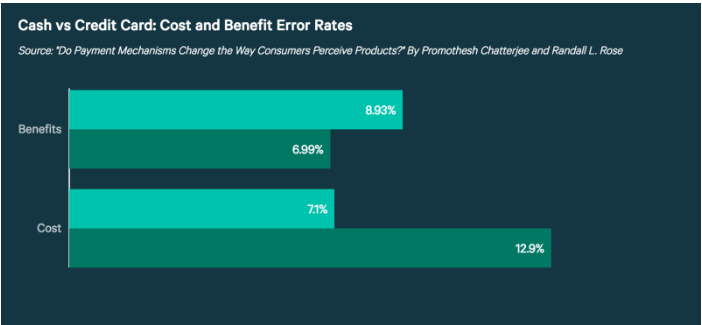

In [1]:
from IPython.display import Image
Image(r'C:\Users\ashwi\Documents\Data Tales\Amex Hackathon\Pic1.png',width=1000)

### <font color='red'> People Are Using Credit Cards Now More Than Ever </font>

With such an increase in credit card and remote transactions, it's important for consumers to be aware of
how their payment choice might affect their spending. This doesn't mean you shouldn't use a credit card. However,
it does mean consumers should make an effort to be especially cognizant of their choices when using a 
credit card or shopping online.

### <font color='red'> Problem Statement</font>

We will be estimating the pattern of credit cards being spent by the cardholders for the next 3 months
based on the age of the consumers, debit cards / credit cards spending rate,number of transactions being carried out by them, emi active for cardholders. 

### <font color='red'> Data Analysis</font>

In [2]:
# Importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
import warnings 
warnings.simplefilter(action='ignore', category = FutureWarning)
warnings.simplefilter(action='ignore', category = DeprecationWarning)
warnings.simplefilter(action='ignore', category = UserWarning)
pd.options.mode.chained_assignment = None
import missingno as msno
from collections import Counter
import itertools
import matplotlib

### <font color='red'> Load and explore dataset</font>

Let us explore the credit card spent dataset 

In [3]:
cc_spent_train = pd.read_csv(r'C:\Users\ashwi\Documents\Data Tales\Amex Hackathon\train.csv')

In [4]:
pd.set_option('display.max_columns',45)
cc_spent_train.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
0,23334,saving,M,63,305,7695.00,NaN,479.00,NaN,622.0,NaN,2.0,1.0,3.0,NaN,NaN,NaN,150000.0,NaN,NaN,NaN,NaN,NaN,118845.2,50000.0,NaN,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,NaN,0.00,435
1,20329,current,M,33,326,52702.00,988.72,29873.00,NaN,1087.0,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,176000.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,NaN,4963.33,1921
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,65000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,NaN,0.00,1970
3,16428,saving,M,44,233,20936.00,NaN,2094.00,NaN,11778.5,NaN,9.0,6.0,6.0,NaN,NaN,NaN,600000.0,NaN,NaN,NaN,NaN,NaN,132442.0,NaN,NaN,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,NaN,1238.18,21579
4,18721,saving,F,35,324,1183.83,NaN,3656.29,NaN,945.0,NaN,2.0,7.0,9.0,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,NaN,0.00,1814


Let us look into the shape of data

In [5]:
cc_spent_train.shape

(32820, 44)

Now, we wil look into the Test data as well

In [6]:
cc_spent_test = pd.read_csv(r'C:\Users\ashwi\Documents\Data Tales\Amex Hackathon\test.csv')

In [7]:
cc_spent_test.shape

(14067, 43)

Let us combine the train and test set for further analysis of data.

In [8]:
cc_spent = pd.concat([cc_spent_train, cc_spent_test], sort=False)
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
0,23334,saving,M,63,305,7695.00,NaN,479.00,NaN,622.0,NaN,2.0,1.0,3.0,NaN,NaN,NaN,150000.0,NaN,NaN,NaN,NaN,NaN,118845.2,50000.0,NaN,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,NaN,0.00,435.0
1,20329,current,M,33,326,52702.00,988.72,29873.00,NaN,1087.0,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,176000.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,NaN,4963.33,1921.0
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,65000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,NaN,0.00,1970.0
3,16428,saving,M,44,233,20936.00,NaN,2094.00,NaN,11778.5,NaN,9.0,6.0,6.0,NaN,NaN,NaN,600000.0,NaN,NaN,NaN,NaN,NaN,132442.0,NaN,NaN,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,NaN,1238.18,21579.0
4,18721,saving,F,35,324,1183.83,NaN,3656.29,NaN,945.0,NaN,2.0,7.0,9.0,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,NaN,0.00,1814.0


In [9]:
cc_spent.columns

Index(['id', 'account_type', 'gender', 'age', 'region_code', 'cc_cons_apr',
       'dc_cons_apr', 'cc_cons_may', 'dc_cons_may', 'cc_cons_jun',
       'dc_cons_jun', 'cc_count_apr', 'cc_count_may', 'cc_count_jun',
       'dc_count_apr', 'dc_count_may', 'dc_count_jun', 'card_lim',
       'personal_loan_active', 'vehicle_loan_active', 'personal_loan_closed',
       'vehicle_loan_closed', 'investment_1', 'investment_2', 'investment_3',
       'investment_4', 'debit_amount_apr', 'credit_amount_apr',
       'debit_count_apr', 'credit_count_apr', 'max_credit_amount_apr',
       'debit_amount_may', 'credit_amount_may', 'credit_count_may',
       'debit_count_may', 'max_credit_amount_may', 'debit_amount_jun',
       'credit_amount_jun', 'credit_count_jun', 'debit_count_jun',
       'max_credit_amount_jun', 'loan_enq', 'emi_active', 'cc_cons'],
      dtype='object')

#### <font color='red'> Understanding features </font>

- id : Unique ID for every Customer
- account_type : Account Type – current or saving
- gender : Gender of customer
- age : Age of customer
- region_code : Code assigned to region of residence (has order)
- cc_cons_apr : Credit card spend in April
- dc_cons_apr : Debit card spend in April
- cc_cons_may : Credit card spend in May
- dc_cons_may : Debit card spend in May
- cc_cons_jun : Credit card spend in June
- dc_cons_jun : Debit card spend in June
- cc_count_apr: Number of credit card transactions in April
- cc_count_may: Number of credit card transactions in May
- cc_count_jun: Number of credit card transactions in June
- dc_count_apr: Number of debit card transactions in April
- dc_count_may: Number of debit card transactions in May
- dc_count_jun: Number of debit card transactions in June
- card_lim    :Maximum Credit Card Limit allocated
- personal_loan_active : Active personal loan with other bank
- vehicle_loan_active  : Active Vehicle loan with other bank
- personal_loan_closed : Closed personal loan in last 12 months
- vehicle_loan_closed  : Closed vehicle loan in last 12 months
- investment_1 : DEMAT investment in june
    ( A Demat Account holds all the investments an individual makes in shares, govt. securities, exchange-
     traded funds, bonds and mututal funds in one place).
- investment_2 : fixed deposit investment in june
- investment_3 : Life Insurance investment in June
- investment_4 : General Insurance Investment in June
- debit_amount_apr : Total amount debited for April
- credit_amount_apr : Total amount credited for April
- debit_count_apr : Total number of times amount debited in april
- credit_count_apr : Total number of times amount credited in april
- max_credit_amount_apr : Maximum amount credited in April
- debit_amount_may : Total amount debited for May
- credit_amount_may : Total amount credited for May
- credit_count_may : Total number of times amount credited in May
- debit_count_may : Total number of times amount debited in May
- max_credit_amount_may : Maximum amount credited in May
- debit_amount_jun : Total amount debited for June
- credit_amount_jun : Total amount credited for June
- credit_count_jun : Total number of times amount credited in June
- debit_count_jun : Total number of times amount debited in June
- max_credit_amount_jun : Maximum amount credited in June
- loan_enq : Loan enquiry in last 3 months
- emi_active : Monthly EMI paid to other bank for active loans
- cc_cons : (Target) Average Credit Card Spend in next three months


Knowing the data types, memory size of the data through info() function

In [10]:
cc_spent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 46887 entries, 0 to 14066
Data columns (total 44 columns):
id                       46887 non-null int64
account_type             46887 non-null object
gender                   46887 non-null object
age                      46887 non-null int64
region_code              46887 non-null int64
cc_cons_apr              46887 non-null float64
dc_cons_apr              19605 non-null float64
cc_cons_may              46887 non-null float64
dc_cons_may              22173 non-null float64
cc_cons_jun              46887 non-null float64
dc_cons_jun              16526 non-null float64
cc_count_apr             43450 non-null float64
cc_count_may             45192 non-null float64
cc_count_jun             44663 non-null float64
dc_count_apr             19605 non-null float64
dc_count_may             22173 non-null float64
dc_count_jun             24838 non-null float64
card_lim                 46875 non-null float64
personal_loan_active     3876 non-n

There are 3 data types which are mainly used here i.e. float , int and object data type.

In [11]:
cc_spent.describe().T

,count,mean,std,min,25%,50%,75%,max
id,46887.0,23443.000000,1.353526e+04,0.00,11721.500,23443.000,35164.5000,4.688600e+04
age,46887.0,35.945678,8.434601e+00,22.00,31.000,34.000,39.0000,2.240000e+02
region_code,46887.0,555.055751,1.882891e+02,123.00,425.000,575.000,683.0000,9.780000e+02
cc_cons_apr,46887.0,16589.430023,2.491871e+04,233.97,3690.000,8897.500,19920.9450,8.047126e+05
dc_cons_apr,19605.0,5675.813594,1.129697e+04,10.01,858.000,2287.000,6097.0000,3.662232e+05
cc_cons_may,46887.0,14335.412564,2.323877e+04,103.00,2970.795,7337.000,16804.7850,1.117246e+06
dc_cons_may,22173.0,5652.441187,1.408264e+04,11.02,804.000,2139.000,5651.0000,9.112235e+05
cc_cons_jun,46887.0,8944.150405,1.564884e+04,51.00,1626.305,4109.000,10012.5475,4.295224e+05
dc_cons_jun,16526.0,4645.834573,1.069242e+04,23.00,735.000,1811.000,4596.0000,3.397630e+05
cc_count_apr,43450.0,9.165386,1.018436e+01,1.00,3.000,7.000,12.0000,1.012000e+03


From the describe() function, we get the interquantile range from 25% to 75% in which the data points lie the most. If there is any huge deviation among max values, there are high chances of outliers in it.
Also , if the count value is not same across all columns, the column has missing values present in it.

## <font color='red'> Data Cleaning</font>

Evaluating the null values present in the dataframe

In [12]:
cc_spent.isnull().sum()

id                           0
account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr              27282
cc_cons_may                  0
dc_cons_may              24714
cc_cons_jun                  0
dc_cons_jun              30361
cc_count_apr              3437
cc_count_may              1695
cc_count_jun              2224
dc_count_apr             27282
dc_count_may             24714
dc_count_jun             22049
card_lim                    12
personal_loan_active     43011
vehicle_loan_active      45686
personal_loan_closed     42745
vehicle_loan_closed      44581
investment_1             44811
investment_2             43522
investment_3             44941
investment_4             46308
debit_amount_apr          2737
credit_amount_apr         4767
debit_count_apr           2546
credit_count_apr          2546
max_credit_amount_apr     4767
debit_amount_may          3302
credit_a

### <font color='red'> Visualization of Missing Numbers</font></b>

We will be visualizing the null values in missing numbers using "missingno" package

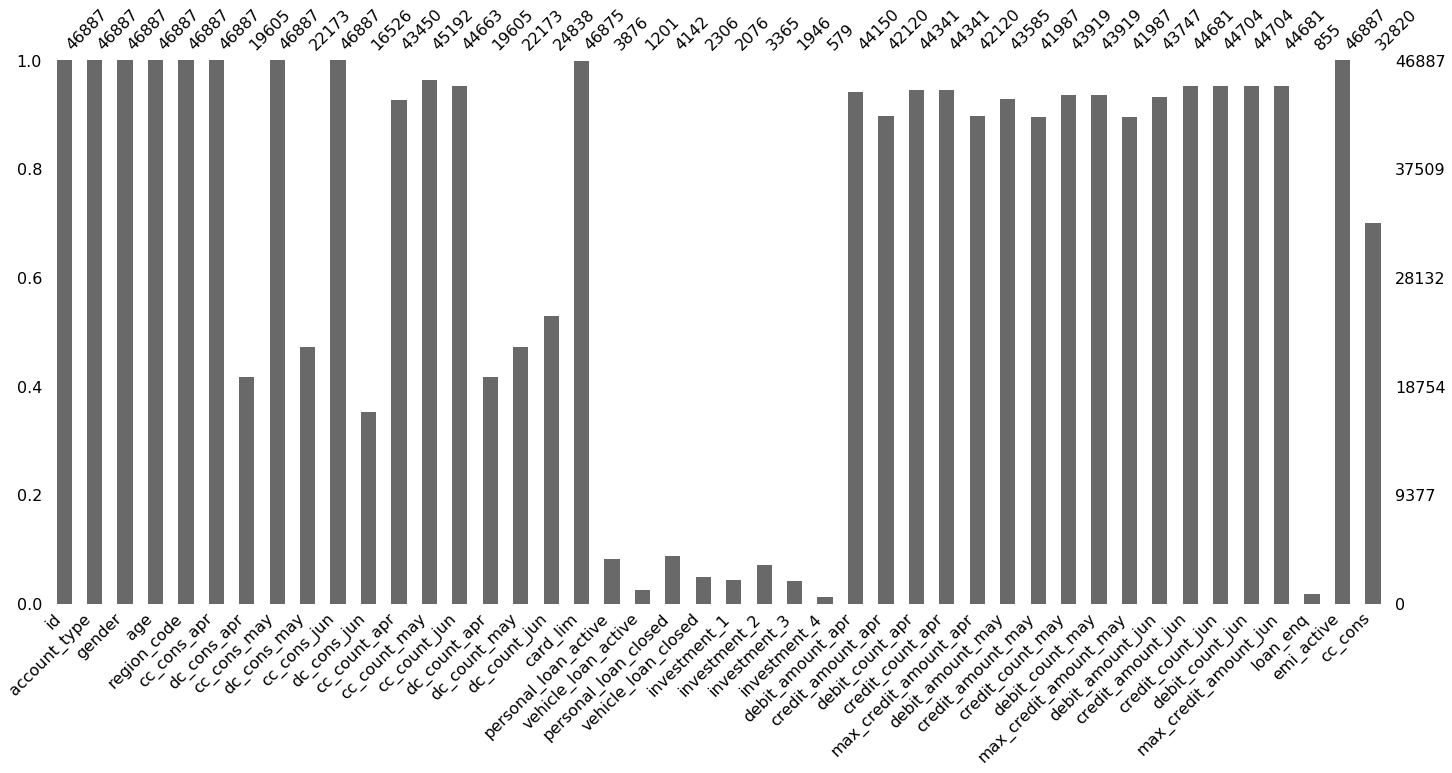

In [13]:
msno.bar(cc_spent)
plt.show()

Above graph symbolizes missing values in Debit_card spent / No of transactions / Amount spend in Debit and Credit card in the months of April, May and June. 
Credit Card limit has null values in it.The values for personal_loan and vehicle_loan with other banks are not captured properly so we need to either impute or delete the columns.
The features Demat_investment(investment_1), Fixed deposits (investment_2), Life insurance (investment_3) and General insurance (investment_4) also contain
missing values in it. Lastly, loan enquiry status also possess null values.


Seeing so many missing values, looks like we need to emphasize more on the data cleaning stage.

On observation of the above features we see the debit and credit amount spent, no of times amount debited/credited,
no of transactions done are being listed for each month namely April, May and June seperately. So , we can club
together all the months by using the average method. We will be performing this in the later part.

Let us check the feature importance of features having null values in them.The features possessing
null values and of less importance would be eliminated from the data. For, finding out the feature importance
we need a ML model such as Decision Tree, Random Forest for implementation of data. Here, we will be
using Decision Tree model to get the feature importances.

In [14]:
# Copying data 'cc_spent' to data 'credit_sp'
credit_sp = cc_spent.copy(deep=True)

When <i>deep=True</i> , a new object will be created with a copy of the calling object's data and indices. Modifications to the data
or indices of the copy will not be reflected in the original object.

In [15]:
# Splitting target from features while building model into X and Y variables where, X is features
# and Y is the Target
Y = credit_sp['cc_cons']
credit_sp = credit_sp.drop(['cc_cons'], axis=1)
X  = credit_sp

Let us now gather features which are numerical and categorical in nature to seperate list.

In [16]:
num_cols = []
for cols in X.select_dtypes(['int','float']):
    num_cols.append(cols)

In [17]:
cat_cols = []

for cols in X.select_dtypes("object"):
    cat_cols.append(cols)

We see that feature "loan_enq" is having numerical value in it. Let us try converting it from "object" to "int" data type.

In [18]:
# Imputing null values in the features with the mean imputation for numerical features
X[num_cols] = X[num_cols].fillna(X[num_cols].mean())

Checking for null values in categorical columns.

In [19]:
X[cat_cols].isnull().sum()

account_type        0
gender              0
loan_enq        46032
dtype: int64

We observe that feature "loan_enq" is having maximum missing value in it. Let's try to impute the missing values in "loan_enq".

In [20]:
X['loan_enq'] = X['loan_enq'].fillna('N')

In [21]:
X.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active
0,23334,saving,M,63,305,7695.00,5675.813594,479.00,5652.441187,622.0,4645.834573,2.0,1.0,3.0,5.263096,6.270013,7.885941,150000.0,1.0,1.0,1.0,1.0,978289.873958,118845.200000,50000.000000,4757.864336,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,N,0.00
1,20329,current,M,33,326,52702.00,988.720000,29873.00,5652.441187,1087.0,2806.240000,11.0,14.0,11.0,1.000000,6.270013,6.000000,176000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,41331.507562,4757.864336,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,4963.33
2,17679,current,M,44,264,10800.49,3215.520000,21659.64,1607.000000,1168.0,355.000000,6.0,9.0,6.0,3.000000,2.000000,14.000000,65000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,41331.507562,4757.864336,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,0.00
3,16428,saving,M,44,233,20936.00,5675.813594,2094.00,5652.441187,11778.5,4645.834573,9.0,6.0,6.0,5.263096,6.270013,7.885941,600000.0,1.0,1.0,1.0,1.0,978289.873958,132442.000000,41331.507562,4757.864336,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,1238.18
4,18721,saving,F,35,324,1183.83,5675.813594,3656.29,5652.441187,945.0,4645.834573,2.0,7.0,9.0,5.263096,6.270013,7.885941,100000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,41331.507562,4757.864336,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,0.00


Let us create dummy variables from the features

In [22]:
X = pd.get_dummies(X)
X.head()

,id,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,...,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,account_type_current,account_type_saving,gender_F,gender_M,loan_enq_N,loan_enq_Y
0,23334,63,305,7695.00,5675.813594,479.00,5652.441187,622.0,4645.834573,2.0,1.0,3.0,5.263096,6.270013,7.885941,150000.0,1.0,1.0,1.0,1.0,978289.873958,118845.200000,...,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,0.00,0,1,0,1,1,0
1,20329,33,326,52702.00,988.720000,29873.00,5652.441187,1087.0,2806.240000,11.0,14.0,11.0,1.000000,6.270013,6.000000,176000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,...,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,4963.33,1,0,0,1,1,0
2,17679,44,264,10800.49,3215.520000,21659.64,1607.000000,1168.0,355.000000,6.0,9.0,6.0,3.000000,2.000000,14.000000,65000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,...,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,0.00,1,0,0,1,1,0
3,16428,44,233,20936.00,5675.813594,2094.00,5652.441187,11778.5,4645.834573,9.0,6.0,6.0,5.263096,6.270013,7.885941,600000.0,1.0,1.0,1.0,1.0,978289.873958,132442.000000,...,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,1238.18,0,1,0,1,1,0
4,18721,35,324,1183.83,5675.813594,3656.29,5652.441187,945.0,4645.834573,2.0,7.0,9.0,5.263096,6.270013,7.885941,100000.0,1.0,1.0,1.0,1.0,978289.873958,167886.083649,...,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,0.00,0,1,1,0,1,0


Recipe to check for variable importance

For checking the variable importance we will be using <b>"yellowbrick.features"</b>

In [23]:
!pip install yellowbrick

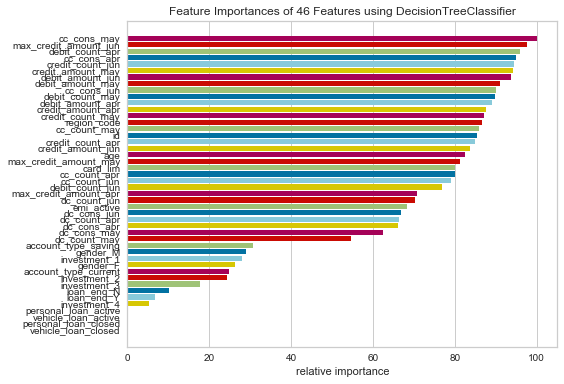

In [24]:
from sklearn.tree import DecisionTreeClassifier
from yellowbrick.features import FeatureImportances

clf = DecisionTreeClassifier()
viz = FeatureImportances(clf)
viz.fit(X[:5000],Y[:5000])
viz.poof()
plt.show()

Above graph says that features "vehicle_loan_closed", "personal_loan_closed", "vehicle_loan_active"
and "personal_loan_active" are least important features. Let's evaluate this by checking the value_counts()
in them.

In [25]:
impute_cols = ['loan_enq','personal_loan_active','vehicle_loan_active','personal_loan_closed','vehicle_loan_closed']

In [26]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
0,23334,saving,M,63,305,7695.00,NaN,479.00,NaN,622.0,NaN,2.0,1.0,3.0,NaN,NaN,NaN,150000.0,NaN,NaN,NaN,NaN,NaN,118845.2,50000.0,NaN,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,NaN,0.00,435.0
1,20329,current,M,33,326,52702.00,988.72,29873.00,NaN,1087.0,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,176000.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,NaN,4963.33,1921.0
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,65000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,NaN,0.00,1970.0
3,16428,saving,M,44,233,20936.00,NaN,2094.00,NaN,11778.5,NaN,9.0,6.0,6.0,NaN,NaN,NaN,600000.0,NaN,NaN,NaN,NaN,NaN,132442.0,NaN,NaN,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,NaN,1238.18,21579.0
4,18721,saving,F,35,324,1183.83,NaN,3656.29,NaN,945.0,NaN,2.0,7.0,9.0,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,NaN,0.00,1814.0


In [27]:
Unimp_features = cc_spent[impute_cols].apply(lambda x: x.value_counts().to_dict())

In [28]:
Unimp_features

loan_enq                 {'Y': 855}
personal_loan_active    {1.0: 3876}
vehicle_loan_active     {1.0: 1201}
personal_loan_closed    {1.0: 4142}
vehicle_loan_closed     {1.0: 2306}
dtype: object

From the above observation, we see that only values of one type are depicted. Hence, we need to impute values which are missing here. Also, such analysis arises having domain knowledge of data.

In [29]:
cc_spent['loan_enq'].fillna("N",inplace=True)
cc_spent['personal_loan_active'].fillna(0.0, inplace=True)
cc_spent['vehicle_loan_active'].fillna(0.0, inplace=True)
cc_spent['personal_loan_closed'].fillna(0.0, inplace=True)
cc_spent['vehicle_loan_closed'].fillna(0.0, inplace=True)

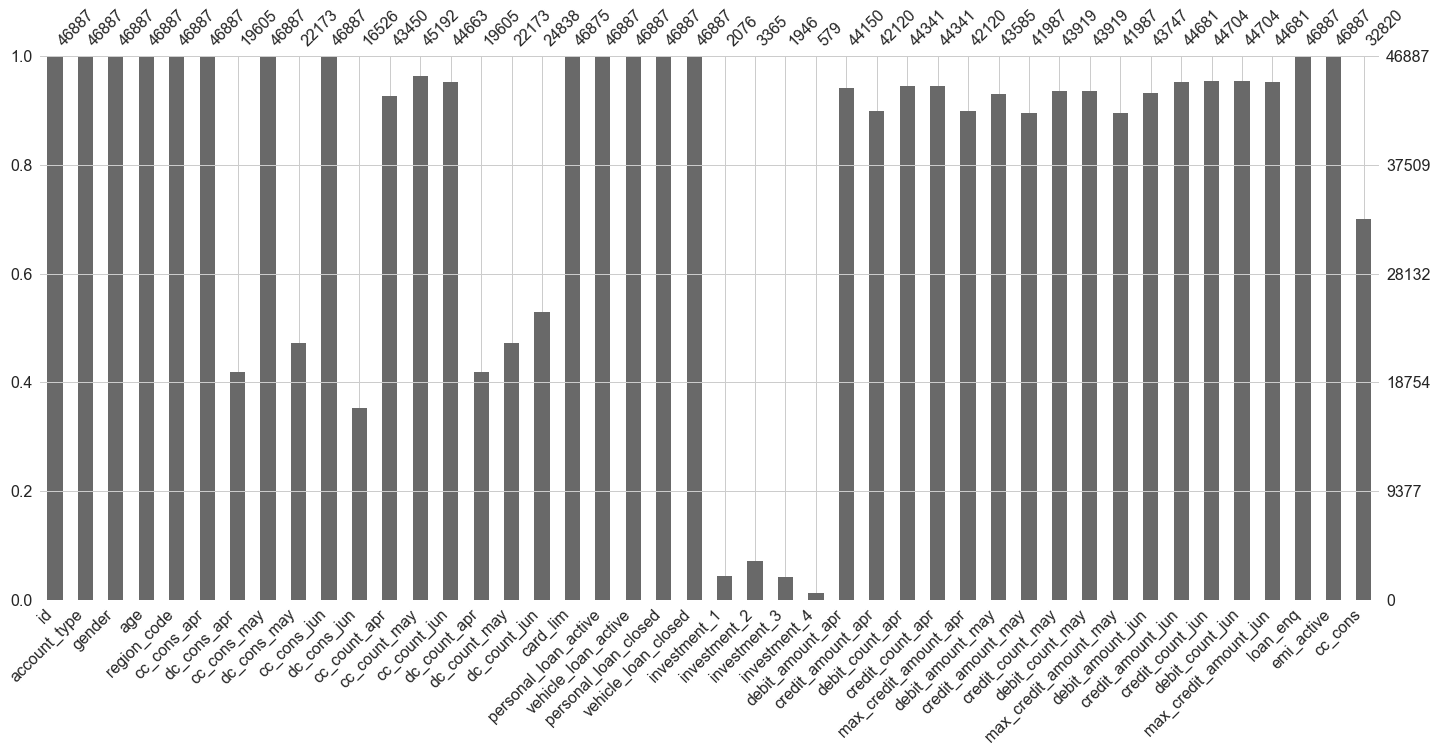

In [30]:
msno.bar(cc_spent)
plt.show()

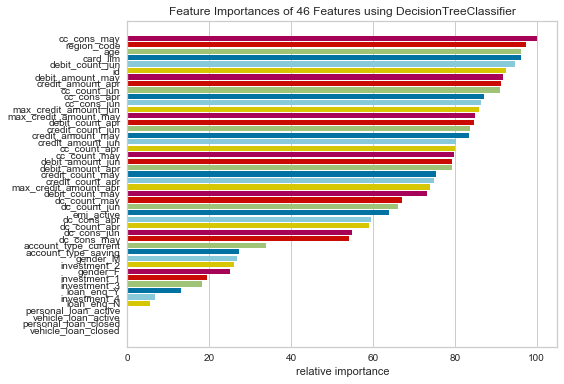

In [31]:
from sklearn.tree import DecisionTreeClassifier
from yellowbrick.features import FeatureImportances

clf = DecisionTreeClassifier()
viz = FeatureImportances(clf)
viz.fit(X[:5000],Y[:5000])
viz.poof()
plt.show()


On imputation , we see the same graph of feature_importance.

From the above observation, we see that features 'vehicle_loan_closed','personal_loan_closed','vehicle_loan_active' , 'personal_loan_active','investment_4'  are least important. At this stage, we also observe that columns 'investment_1','investment2','investment_3' are having missing values in them. They seem to be important features than the above mentioned. Hence, we need to retain them.

In [32]:
cc_spent= cc_spent.drop(['investment_4','vehicle_loan_closed','personal_loan_closed',
                         'vehicle_loan_active','personal_loan_active'], axis=1)

Let us see the null values still remaining in the dataframe 

In [33]:
cc_spent.isnull().sum()

id                           0
account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr              27282
cc_cons_may                  0
dc_cons_may              24714
cc_cons_jun                  0
dc_cons_jun              30361
cc_count_apr              3437
cc_count_may              1695
cc_count_jun              2224
dc_count_apr             27282
dc_count_may             24714
dc_count_jun             22049
card_lim                    12
investment_1             44811
investment_2             43522
investment_3             44941
debit_amount_apr          2737
credit_amount_apr         4767
debit_count_apr           2546
credit_count_apr          2546
max_credit_amount_apr     4767
debit_amount_may          3302
credit_amount_may         4900
credit_count_may          2968
debit_count_may           2968
max_credit_amount_may     4900
debit_amount_jun          3140
credit_a

We can make use of imputation methods instead of data-dropping methods.The simplest imputation method is replacing missing values with "mean" or "median" values of the dataset , or some summary statistic. This has advantage of being simple approach, as it doesn't create any bias in data. But, in case of missing values that are not strictly random , especially in the presence of great inequality in the number of missing values for the different variables , the mean substitution method may lead to inconsistent bias. Further, this doesn't add any new information and only increases sample size and leads to underestimate of errors. Hence, mean subsitution in case of missing values not random is generally not accepted.

### <font color='red'> Imputing missing values using Linear Regression technique</font>

We will be imputing missing values to feature "card_lim" using the regression imputation technique.
In this technique, using the correlation matrix we will be figuring out the features which are highly
correlated to the missing variable. Thereby, consider the correlated features as 'X'(inputs) and 'Y'(target)
as the missing variable 'card_lim' while building the model. Once, the model is built the predicted values a
are for the missing variable and later assign it to the original dataframe.

<b>Note</b>:- For running heatmap, check if you are using the latest version of matplotlib i.e. "3.1.2" using matplotlib.__version__ . Since, the earlier version truncates the top and bottom rows in heatmap.

In [34]:
matplotlib.__version__

'3.1.2'

<b> Correlation among Continuous Features </b>

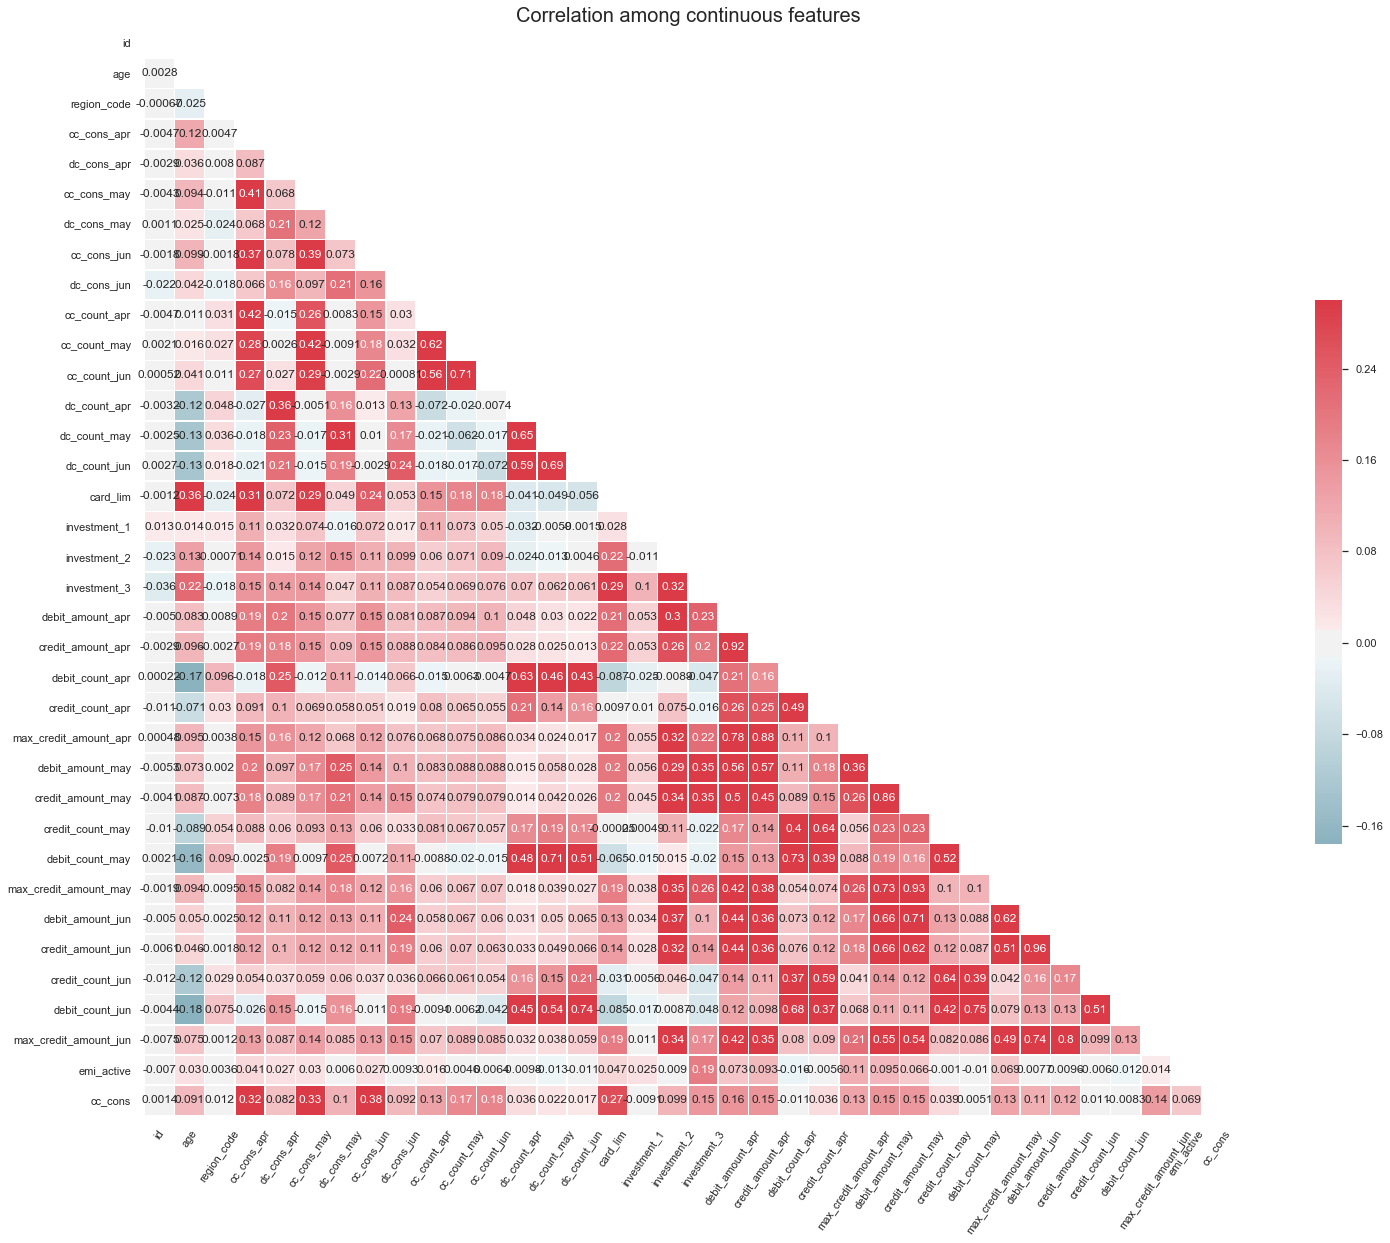

In [35]:
sns.set(style='white')

# Compute the correlation matrix
corr = cc_spent.corr()

# Generate a mask for the upper triangle
mask = np.zeros_like(corr, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(30,20))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(220,10,as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidth=.5, cbar_kws={"shrink":.5}, annot=True);
plt.xticks(rotation=55)
plt.title("Correlation among continuous features",fontsize=20)
plt.show()

We figured that for column "card_lim" the features"age" and "cc_cons_apr", "cc_cons_may"
and "cc_cons_jun","cc_cons" are correlated. Hence, these variables
will be considered in the model imputation along with the target variable as "card_lim".

In [36]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
data_cl = cc_spent[['age','cc_cons_apr','cc_cons_may','cc_cons_jun','card_lim']]


# Splitting the dataset that contains missing values and no-missing values into train and test respectively
x_cl_train = data_cl[data_cl['card_lim'].notnull()].drop(columns='card_lim')
y_cl_train = data_cl[data_cl['card_lim'].notnull()]['card_lim']
x_cl_test = data_cl[data_cl['card_lim'].isnull()].drop(columns='card_lim')
y_cl_test = data_cl[data_cl['card_lim'].isnull()]['card_lim']

# Train the ml algo
linreg.fit(x_cl_train[:32820], y_cl_train[:32820])

# Predict the missing values in the attribute of the test data
predicted_cl = linreg.predict(x_cl_test)

# Let us obtain the complete dataset by combining it with the target variable
cc_spent.card_lim[cc_spent.card_lim.isnull()] = predicted_cl
cc_spent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 46887 entries, 0 to 14066
Data columns (total 39 columns):
id                       46887 non-null int64
account_type             46887 non-null object
gender                   46887 non-null object
age                      46887 non-null int64
region_code              46887 non-null int64
cc_cons_apr              46887 non-null float64
dc_cons_apr              19605 non-null float64
cc_cons_may              46887 non-null float64
dc_cons_may              22173 non-null float64
cc_cons_jun              46887 non-null float64
dc_cons_jun              16526 non-null float64
cc_count_apr             43450 non-null float64
cc_count_may             45192 non-null float64
cc_count_jun             44663 non-null float64
dc_count_apr             19605 non-null float64
dc_count_may             22173 non-null float64
dc_count_jun             24838 non-null float64
card_lim                 46887 non-null float64
investment_1             2076 non-n

We now see that the null values for column 'card_lim' is imputed.

We see that inorder to impute missing values in other variables, we need to check coefficiency
of it and the features should have non-null values in them which is a bit complicated for rest features
through regression imputation. Hence, we will be using KNN imputation technique for the features which have null sum less than 5000 in them.

### <font color='red'> Usage of KNN imputation technique inorder to impute missing values</font>

Extracting the null valued features into a seperate dataframe "cc_null_values"

In [37]:
null_cols = cc_spent.columns[cc_spent.isnull().any()]

In [38]:
# Since, null values in target column "cc_cons" belong to test data. Hence, will be dropping the column
null_cols = null_cols.drop('cc_cons')

In [39]:
# We will be extracting only columns which have null value count less than 5000 from the list "null_cols"
cols_less_thn_5000 = null_cols[cc_spent[null_cols].isnull().sum() < 5000].to_list()

In [40]:
# Placing the null columns having count less than 5000 in another dataframe "null_data"
null_data = pd.DataFrame(cc_spent[cols_less_thn_5000])

In [41]:
null_data.head()

,cc_count_apr,cc_count_may,cc_count_jun,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun
0,2.0,1.0,3.0,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0
1,11.0,14.0,11.0,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0
2,6.0,9.0,6.0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0
3,9.0,6.0,6.0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0
4,2.0,7.0,9.0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0


#### Prerequisities to install "fancyimpute" library:-

1. Installation of Microsoft Visual Studio "https://visualstudio.microsoft.com/thank-you-downloading-visual-studio/?sku=BuildTools&rel=16"

2. Installation of tensorflow library,
!pip install tensorflow==2.0.0

3. Installation of keras
!pip install keras

4. Installation of six
!pip install six

5. Installation of np-utils
!pip install np-utils

6. Installation of knnimpute
!pip install knnimpute

7. The scikit-learn version should be >= 0.19.1 and numpy package.


In [42]:
# Inorder to install "fancyimpute" library, we need to download and install package
!pip install fancyimpute

In [43]:
# On extracting null columns for imputation , we will be applying KNN Imputation to it
from fancyimpute import KNN
# fancyimpute removes column names, storing columns in the form of a list for train and test
cols = list(null_data)

Using TensorFlow backend.


Splitting dataframe into 3 dataframes based on indexes, since it is causing a memory issue

In [44]:
# Use 5 nearest rows which have a feature to fill in each row's  missing features
cc_train_1 = pd.DataFrame(KNN(k=5).fit_transform(null_data[1:15001]))
cc_train_1.columns = cols

Imputing row 1/15000 with 0 missing, elapsed time: 102.111
Imputing row 101/15000 with 0 missing, elapsed time: 102.137
Imputing row 201/15000 with 0 missing, elapsed time: 102.149
Imputing row 301/15000 with 0 missing, elapsed time: 102.159
Imputing row 401/15000 with 0 missing, elapsed time: 102.180
Imputing row 501/15000 with 0 missing, elapsed time: 102.195
Imputing row 601/15000 with 2 missing, elapsed time: 102.231
Imputing row 701/15000 with 0 missing, elapsed time: 102.253
Imputing row 801/15000 with 2 missing, elapsed time: 102.269
Imputing row 901/15000 with 0 missing, elapsed time: 102.291
Imputing row 1001/15000 with 2 missing, elapsed time: 102.313
Imputing row 1101/15000 with 2 missing, elapsed time: 102.337
Imputing row 1201/15000 with 0 missing, elapsed time: 102.357
Imputing row 1301/15000 with 2 missing, elapsed time: 102.374
Imputing row 1401/15000 with 0 missing, elapsed time: 102.393
Imputing row 1501/15000 with 6 missing, elapsed time: 102.411
Imputing row 1601/15

Imputing row 14001/15000 with 2 missing, elapsed time: 104.900
Imputing row 14101/15000 with 0 missing, elapsed time: 104.926
Imputing row 14201/15000 with 0 missing, elapsed time: 104.949
Imputing row 14301/15000 with 0 missing, elapsed time: 104.967
Imputing row 14401/15000 with 0 missing, elapsed time: 104.988
Imputing row 14501/15000 with 5 missing, elapsed time: 105.001
Imputing row 14601/15000 with 0 missing, elapsed time: 105.017
Imputing row 14701/15000 with 0 missing, elapsed time: 105.034
Imputing row 14801/15000 with 0 missing, elapsed time: 105.048
Imputing row 14901/15000 with 0 missing, elapsed time: 105.068


In [45]:
cc_train_2 = pd.DataFrame(KNN(k=5).fit_transform(null_data[15000:32821]))
cc_train_2.columns = cols

Imputing row 1/17821 with 1 missing, elapsed time: 734.812
Imputing row 101/17821 with 0 missing, elapsed time: 734.821
Imputing row 201/17821 with 0 missing, elapsed time: 734.832
Imputing row 301/17821 with 0 missing, elapsed time: 734.845
Imputing row 401/17821 with 0 missing, elapsed time: 734.854
Imputing row 501/17821 with 16 missing, elapsed time: 734.861
Imputing row 601/17821 with 0 missing, elapsed time: 734.869
Imputing row 701/17821 with 1 missing, elapsed time: 734.878
Imputing row 801/17821 with 15 missing, elapsed time: 734.888
Imputing row 901/17821 with 2 missing, elapsed time: 734.900
Imputing row 1001/17821 with 0 missing, elapsed time: 734.908
Imputing row 1101/17821 with 15 missing, elapsed time: 734.914
Imputing row 1201/17821 with 0 missing, elapsed time: 734.920
Imputing row 1301/17821 with 0 missing, elapsed time: 734.927
Imputing row 1401/17821 with 0 missing, elapsed time: 734.937
Imputing row 1501/17821 with 0 missing, elapsed time: 734.943
Imputing row 1601

Imputing row 13501/17821 with 0 missing, elapsed time: 735.935
Imputing row 13601/17821 with 0 missing, elapsed time: 735.941
Imputing row 13701/17821 with 0 missing, elapsed time: 735.949
Imputing row 13801/17821 with 1 missing, elapsed time: 735.958
Imputing row 13901/17821 with 0 missing, elapsed time: 735.964
Imputing row 14001/17821 with 0 missing, elapsed time: 735.980
Imputing row 14101/17821 with 0 missing, elapsed time: 735.988
Imputing row 14201/17821 with 2 missing, elapsed time: 735.999
Imputing row 14301/17821 with 0 missing, elapsed time: 736.007
Imputing row 14401/17821 with 1 missing, elapsed time: 736.017
Imputing row 14501/17821 with 0 missing, elapsed time: 736.021
Imputing row 14601/17821 with 0 missing, elapsed time: 736.032
Imputing row 14701/17821 with 1 missing, elapsed time: 736.041
Imputing row 14801/17821 with 0 missing, elapsed time: 736.048
Imputing row 14901/17821 with 0 missing, elapsed time: 736.053
Imputing row 15001/17821 with 0 missing, elapsed time: 

In [46]:
cc_train_3 = pd.DataFrame(KNN(k=5).fit_transform(null_data[32820:46888]))
cc_train_3.columns = cols

Imputing row 1/14067 with 0 missing, elapsed time: 34.122
Imputing row 101/14067 with 0 missing, elapsed time: 34.130
Imputing row 201/14067 with 0 missing, elapsed time: 34.134
Imputing row 301/14067 with 1 missing, elapsed time: 34.140
Imputing row 401/14067 with 0 missing, elapsed time: 34.146
Imputing row 501/14067 with 0 missing, elapsed time: 34.152
Imputing row 601/14067 with 2 missing, elapsed time: 34.158
Imputing row 701/14067 with 0 missing, elapsed time: 34.168
Imputing row 801/14067 with 0 missing, elapsed time: 34.175
Imputing row 901/14067 with 1 missing, elapsed time: 34.180
Imputing row 1001/14067 with 1 missing, elapsed time: 34.187
Imputing row 1101/14067 with 15 missing, elapsed time: 34.191
Imputing row 1201/14067 with 1 missing, elapsed time: 34.202
Imputing row 1301/14067 with 0 missing, elapsed time: 34.208
Imputing row 1401/14067 with 0 missing, elapsed time: 34.214
Imputing row 1501/14067 with 0 missing, elapsed time: 34.224
Imputing row 1601/14067 with 1 miss

In [47]:
# Combining dataframes "cc_train_1", "cc_train_2" and "cc_train_3" into a single dataframe "cc_num_data" after
# imputation
cc_num_data = pd.concat([cc_train_1, cc_train_2, cc_train_3], ignore_index=True)

In [48]:
cc_num_data.shape

(46888, 18)

In [49]:
cc_num_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46888 entries, 0 to 46887
Data columns (total 18 columns):
cc_count_apr             46888 non-null float64
cc_count_may             46888 non-null float64
cc_count_jun             46888 non-null float64
debit_amount_apr         46888 non-null float64
credit_amount_apr        46888 non-null float64
debit_count_apr          46888 non-null float64
credit_count_apr         46888 non-null float64
max_credit_amount_apr    46888 non-null float64
debit_amount_may         46888 non-null float64
credit_amount_may        46888 non-null float64
credit_count_may         46888 non-null float64
debit_count_may          46888 non-null float64
max_credit_amount_may    46888 non-null float64
debit_amount_jun         46888 non-null float64
credit_amount_jun        46888 non-null float64
credit_count_jun         46888 non-null float64
debit_count_jun          46888 non-null float64
max_credit_amount_jun    46888 non-null float64
dtypes: float64(18)
memory 

In [50]:
cc_spent[cols_less_thn_5000] = cc_num_data

In [51]:
# Columns having null value sum greater than 5000 
cols_gt_thn_5000 = null_cols[cc_spent[null_cols].isnull().sum() > 5000].to_list()

In [52]:
cols_gt_thn_5000

['dc_cons_apr',
 'dc_cons_may',
 'dc_cons_jun',
 'dc_count_apr',
 'dc_count_may',
 'dc_count_jun',
 'investment_1',
 'investment_2',
 'investment_3']

In [53]:
cc_spent[cols_gt_thn_5000] = cc_spent[cols_gt_thn_5000].fillna(0,axis=0)

In [54]:
cc_spent.isnull().sum()

id                           0
account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr                  0
cc_cons_may                  0
dc_cons_may                  0
cc_cons_jun                  0
dc_cons_jun                  0
cc_count_apr                 0
cc_count_may                 0
cc_count_jun                 0
dc_count_apr                 0
dc_count_may                 0
dc_count_jun                 0
card_lim                     0
investment_1                 0
investment_2                 0
investment_3                 0
debit_amount_apr             0
credit_amount_apr            0
debit_count_apr              0
credit_count_apr             0
max_credit_amount_apr        0
debit_amount_may             0
credit_amount_may            0
credit_count_may             0
debit_count_may              0
max_credit_amount_may        0
debit_amount_jun             0
credit_a

### <font color='red'> Detecting and Removing Outliers</font>

In [55]:
num_cols = []
for column in cc_spent.select_dtypes(["int64","float64"]):
    num_cols.append(column)

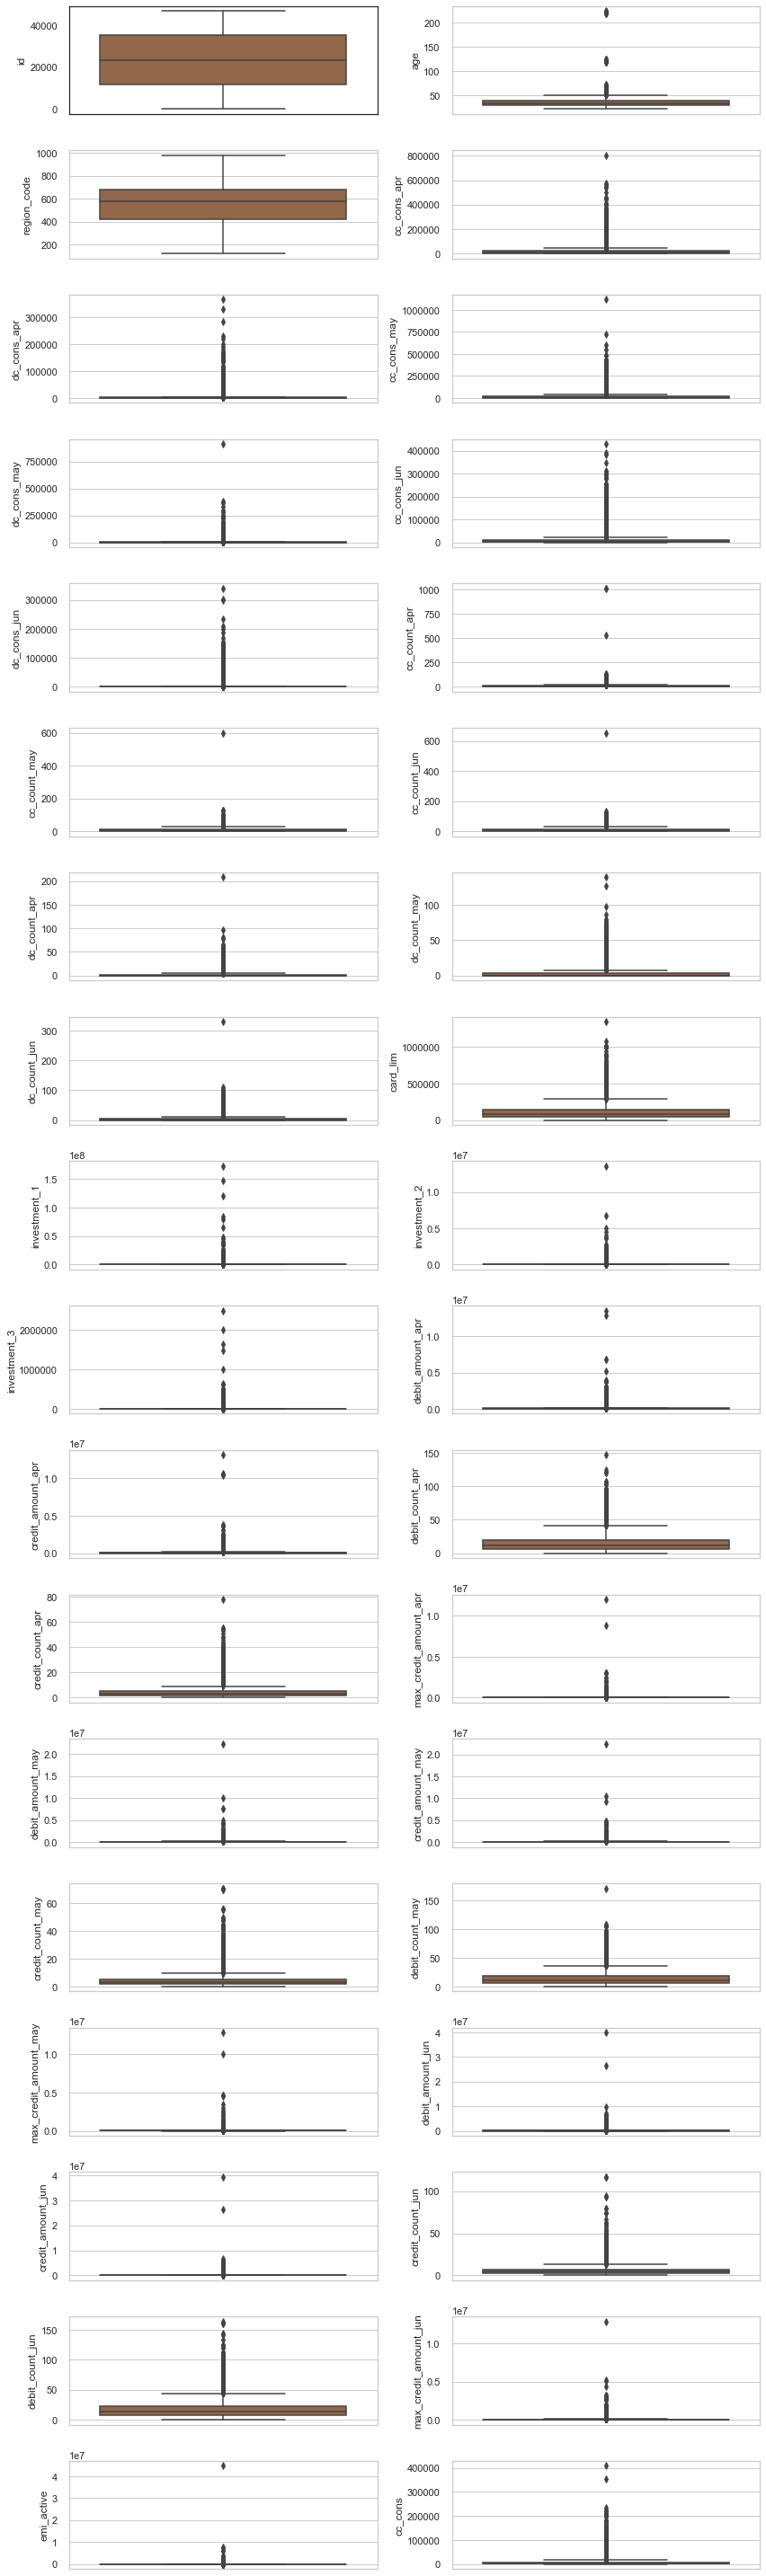

In [56]:
fig = plt.figure(figsize=(12,40))
i=1
for column in cc_spent.select_dtypes(["int64","float64"]):
    plt.subplot(18,2,i)
    sns.set_style("whitegrid")
    ax = sns.boxplot(cc_spent[column], palette="copper", orient='v')
    i = i + 1
    
plt.tight_layout()
plt.show()

    

The above graph shows the Outlier Analysis of various continuous variables, we see most of the data points
lying above the inter-quartile range. However, they cannot be termed as outliers. In this scenario, we will be gathering data points
which don't fall under the normal pattern, detect and remove such outliers.

In [57]:
Q1 = cc_spent.quantile(0.25)
Q3 = cc_spent.quantile(0.75)
IQR = Q3 - Q1
IQR

id                        23443.000000
age                           8.000000
region_code                 258.000000
cc_cons_apr               16230.945000
dc_cons_apr                1578.750000
cc_cons_may               13833.990000
dc_cons_may                1915.960000
cc_cons_jun                8386.242500
dc_cons_jun                 856.000000
cc_count_apr                  9.000000
cc_count_may                 10.000000
cc_count_jun                 12.000000
dc_count_apr                  2.000000
dc_count_may                  3.000000
dc_count_jun                  5.000000
card_lim                 100000.000000
investment_1                  0.000000
investment_2                  0.000000
investment_3                  0.000000
debit_amount_apr          52481.440000
credit_amount_apr         53207.980000
debit_count_apr              14.000000
credit_count_apr              3.000000
max_credit_amount_apr     29470.000000
debit_amount_may          52893.340000
credit_amount_may        

### <font color='red'>Figuring out outliers in data by setting up various upper extremes in features </font> 

<b><i> Cutoff for column "age" </i></b>

In [58]:
age_ctoff = IQR['age'] * 4
upper = Q3 + age_ctoff

In [59]:
cc_spent[cc_spent['age'] > upper['age']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
1121,12756,saving,M,119,123,12862.350,0.00,892.01,0.00,6950.680,0.0,12.0,17.0,21.0,0.0,0.0,0.0,280000.0,0.00,0.00,0.0,190787.820000,196532.000000,34.000000,14.000000,44350.000000,225599.180000,221219.570000,15.000000,29.000000,60000.000000,121365.650000,120660.500000,15.000000,29.000000,43650.000000,N,579.95,3392.0
2496,41928,current,M,221,723,3801.500,4369.00,5440.00,0.00,652.000,0.0,10.0,7.0,16.0,2.0,0.0,0.0,130000.0,0.00,0.00,0.0,28614.880000,45168.000000,10.000000,3.000000,20000.000000,35926.360000,25253.000000,1.000000,6.000000,25000.000000,41975.940000,38403.000000,4.000000,7.000000,20000.000000,N,0.00,3971.0
2914,23122,current,M,119,683,31769.000,17776.00,19290.50,11242.00,6098.000,1327.0,4.0,8.0,16.0,10.0,10.0,12.0,46000.0,0.00,0.00,0.0,58.250000,746.940334,1.000000,0.000000,543.641203,4893.865693,3314.348849,1.345186,1.850753,3076.112854,512.769618,359.000000,1.000000,0.000000,80.000000,N,0.00,5192.0
3205,35592,current,M,222,526,30425.880,27123.00,321.00,5537.14,10991.000,3454.0,2.0,7.0,6.0,5.0,6.0,13.0,75000.0,0.00,0.00,0.0,51359.310000,63129.000000,13.000000,2.000000,40000.000000,30624.500000,23160.000000,1.000000,7.000000,23111.000000,25834.240000,43815.000000,4.000000,17.000000,23111.000000,N,0.00,4430.0
7071,1479,saving,F,223,523,21008.440,0.00,9910.25,0.00,9559.000,0.0,13.0,7.0,19.0,0.0,0.0,0.0,300000.0,296802.58,0.00,0.0,42728.000000,90358.000000,10.000000,5.000000,45542.000000,47099.000000,255516.000000,2.000000,10.000000,250000.000000,26508.930000,51462.000000,4.000000,4.000000,35972.000000,N,0.00,6059.0
7823,10230,current,M,223,723,2975.000,0.00,555.00,0.00,2920.000,947.0,13.0,12.0,17.0,0.0,0.0,5.0,78000.0,0.00,0.00,0.0,69034.200000,76582.000000,13.000000,5.000000,30000.000000,70462.390000,65678.500000,4.000000,12.000000,35500.000000,191686.370000,216003.000000,7.000000,16.000000,100000.000000,N,0.00,250.0
9541,13849,current,M,123,723,4738.000,0.00,28221.00,0.00,1116.000,0.0,4.0,10.0,23.0,0.0,0.0,0.0,50000.0,0.00,0.00,0.0,36559.200000,36207.000000,10.000000,11.000000,13500.000000,99514.720000,99401.000000,5.000000,14.000000,49000.000000,152917.870000,180863.250000,23.000000,24.000000,48500.000000,N,1168.83,26936.0
11455,34081,saving,M,118,513,220507.810,0.00,19692.50,0.00,12559.000,0.0,4.0,6.0,5.0,0.0,0.0,0.0,200000.0,0.00,0.00,0.0,55925.250000,57552.000000,26.000000,4.000000,20383.000000,22909.310000,21982.000000,3.000000,29.000000,20000.000000,45808.270000,47741.000000,10.000000,47.000000,25000.000000,N,0.00,1434.0
13862,18776,saving,M,219,623,40445.715,0.00,3726.00,0.00,74896.430,0.0,24.0,11.0,20.0,0.0,0.0,0.0,250000.0,225823.80,0.00,0.0,23759.840000,23653.000000,16.000000,2.000000,18606.000000,41214.960000,56896.000000,5.000000,6.000000,19683.000000,45805.810000,99984.000000,6.000000,15.000000,40000.000000,Y,156.64,18241.0
14967,15619,current,M,121,248,42635.240,1187.03,3647.00,2744.92,2957.000,0.0,12.0,10.0,16.0,3.0,4.0,1.0,390000.0,0.00,0.00,0.0,38289.000000,20395.000000,4.000000,3.000000,9770.000000,30943.750000,38500.250000,3.000000,6.000000,20000.000000,43190.000000,22687.000000,5.000000,3.000000,14000.000000,N,0.00,4947.0


Some of the ages are above 100. Which shouldn't be the case in real scenario, the data might be entered wrongly . It is advisable to drop such rows.

In [60]:
cc_spent = cc_spent.drop(cc_spent[cc_spent['age'] > 100].index)

In [61]:
cc_spent.shape

(46839, 39)

<b><i> Cutoff for "cc_cons" columns for April, May and June months </i></b>

In [62]:
cc_cons_ctoff = IQR['cc_cons_apr'] * 25
upper = Q3 + cc_cons_ctoff

In [63]:
cc_spent[cc_spent['cc_cons_apr'] > upper['cc_cons_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
2938,5504,current,F,46,523,441031.33,8229.02,551374.36,15063.00,107568.00,0.00,1.0,6.0,5.0,2.0,2.0,3.0,500000.0,0.00,0.00,0.0,385.75,5.176579e+02,2.0,0.0,3.041024e+02,9081.000000,20187.000000,1.000000,3.000000,20000.000000,2513.000000,208.00,1.0,1.0,133.0,N,0.00,53731.0
3413,24479,saving,M,27,233,537837.76,0.00,32650.90,20.00,1540.00,0.00,1.0,3.0,2.0,0.0,1.0,0.0,336000.0,0.00,0.00,0.0,20167.22,1.157500e+04,18.0,1.0,1.152300e+04,16378.000000,13704.000000,1.000000,11.000000,13482.000000,21759.530000,16731.00,4.0,21.0,13127.0,N,12867.92,5638.0
4025,23885,saving,M,60,683,503197.54,0.00,33188.80,0.00,11930.00,0.00,1.0,3.0,6.0,0.0,0.0,0.0,600000.0,0.00,1604485.04,0.0,19761.91,2.456100e+04,12.0,3.0,1.740000e+04,39809.000000,17538.000000,1.000000,13.000000,17400.000000,2038.380000,23847.00,3.0,3.0,17400.0,N,0.00,5000.0
11594,21069,saving,M,41,545,565784.55,0.00,271724.89,0.00,8855.00,0.00,11.0,2.0,1.0,0.0,0.0,0.0,780000.0,0.00,0.00,0.0,124948.17,1.508230e+05,36.0,7.0,6.000000e+04,76900.970000,73754.500000,8.000000,37.000000,40223.000000,49868.920000,76460.50,10.0,36.0,40073.0,N,19665.01,110103.0
23080,10083,saving,M,39,523,804712.58,0.00,384099.42,17823.99,99433.22,2868.83,60.0,52.0,58.0,0.0,11.0,13.0,280000.0,0.00,0.00,0.0,537009.00,5.000150e+05,9.0,1.0,5.000000e+05,491283.610000,500039.000000,1.000000,21.000000,500000.000000,589069.840000,502173.00,3.0,15.0,500000.0,N,0.00,198197.0
27501,18084,current,M,64,876,450413.00,0.00,531.00,0.00,450.00,0.00,5.0,2.0,2.0,0.0,0.0,0.0,500000.0,0.00,0.00,0.0,1051288.35,1.051552e+06,2.0,2.0,9.711343e+05,6272.382646,9424.056272,1.342578,1.301794,7712.037941,11719.141229,41.00,1.0,0.0,2.0,N,7447125.13,300.0
30575,31187,current,M,42,523,456645.33,25908.00,3240.00,13819.50,2073.00,2281.00,9.0,3.0,8.0,7.0,13.0,4.0,374000.0,0.00,0.00,0.0,1789922.21,2.343193e+06,63.0,54.0,1.038422e+06,648314.600000,406833.050000,11.000000,58.000000,186850.000000,193999.880000,21152.45,5.0,30.0,14000.0,N,6336.66,1218.0
788,5404,current,M,40,683,574451.82,0.00,63343.73,0.00,11679.71,0.00,10.0,5.0,10.0,0.0,0.0,0.0,1000000.0,0.00,0.00,500000.0,41245.90,5.709100e+04,16.0,3.0,3.929300e+04,55875.130000,38875.000000,3.000000,19.000000,24193.000000,400416.640000,440001.00,3.0,21.0,415280.0,N,0.00,NaN
5179,22068,current,M,47,683,454498.62,0.00,9892.00,311.00,849.00,0.00,18.0,19.0,9.0,0.0,1.0,0.0,500000.0,85930.35,0.00,6000.0,53032.73,4.033800e+04,20.0,2.0,3.805700e+04,51241.020000,186776.370000,11.000000,24.000000,100000.000000,440099.730000,320972.50,9.0,58.0,245387.0,N,251.18,NaN
7575,33529,saving,M,27,503,554150.61,0.00,75228.72,0.00,8061.00,0.00,17.0,24.0,17.0,0.0,0.0,0.0,100000.0,0.00,0.00,0.0,392151.00,3.779501e+05,21.0,4.0,3.061610e+05,71800.540000,6636.319986,0.000000,14.000000,6127.076326,289210.470000,320079.00,5.0,12.0,300000.0,N,0.00,NaN


In [64]:
cc_spent[cc_spent['cc_cons_may'] > upper['cc_cons_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
2938,5504,current,F,46,523,441031.33,8229.02,551374.36,15063.00,107568.00,0.00,1.00,6.0,5.0,2.0,2.0,3.0,500000.0,0.0,0.0,0.0,385.75,517.657861,2.0,0.0,304.102419,9081.00,20187.00,1.0,3.0,20000.0,2513.000000,208.00,1.0,1.0,133.0,N,0.00,53731.0
5104,21938,current,M,45,683,8323.52,0.00,600699.73,0.00,52601.04,778.00,6.25,4.0,16.0,0.0,0.0,1.0,1000000.0,0.0,0.0,610000.0,138918.75,68271.000000,25.0,2.0,34117.000000,14144.75,5247.00,1.0,8.0,5000.0,40943.420000,40531.00,3.0,7.0,35502.0,N,0.00,13261.0
13837,40706,saving,M,34,245,225936.42,0.00,482474.20,0.00,163955.37,0.00,2.00,4.0,10.0,0.0,0.0,0.0,365000.0,0.0,0.0,0.0,19929.00,17089.000000,9.0,3.0,15950.000000,30646.00,31051.00,5.0,5.0,15950.0,47579.450000,47499.00,7.0,13.0,24000.0,N,19139.28,219858.0
17530,23211,current,F,44,523,122265.90,774.00,1117246.31,0.00,128140.57,2704.88,33.00,39.0,54.0,1.0,0.0,5.0,800000.0,0.0,0.0,0.0,448415.95,382613.000000,21.0,3.0,337428.000000,844686.50,842702.00,5.0,26.0,500000.0,976208.640000,1021136.45,6.0,31.0,500000.0,N,11185.96,65782.0
22825,13127,current,F,25,683,926.00,11025.24,441339.52,20372.58,302751.41,0.00,1.00,6.0,3.0,14.0,14.0,0.0,600000.0,0.0,0.0,0.0,29060.24,18103.000000,24.0,1.0,17905.000000,21419.58,19185.00,3.0,15.0,17905.0,215.849347,18391.00,2.0,0.0,17905.0,N,0.00,131731.0
3291,28787,saving,M,39,544,26890.61,0.00,719249.30,0.00,4305.00,0.00,32.00,32.0,24.0,0.0,0.0,0.0,600000.0,0.0,0.0,0.0,36016.09,39499.000000,11.0,2.0,28605.000000,92691.60,89735.00,2.0,12.0,61073.0,27241.260000,38628.00,3.0,16.0,28397.0,N,7291.64,NaN
10011,24189,saving,M,37,233,46328.59,0.00,427855.09,0.00,27022.00,0.00,1.00,1.0,11.2,0.0,0.0,0.0,1000000.0,0.0,0.0,0.0,35157.00,17449.000000,2.0,1.0,17216.000000,16200.00,126799.91,3.0,7.0,109500.0,33287.000000,38131.93,5.0,9.0,17299.0,N,658491.51,NaN
13079,38077,current,M,36,683,58729.49,0.00,426569.30,0.00,429522.43,0.00,19.00,10.0,16.0,0.0,0.0,0.0,800000.0,0.0,0.0,0.0,65183.43,61316.020000,14.0,5.0,36600.000000,18741.59,38922.74,3.0,12.0,36600.0,51803.980000,36783.00,2.0,8.0,36600.0,N,5305.34,NaN
14056,40368,current,M,39,524,249435.43,14974.10,487458.86,366212.11,10211.00,0.00,5.00,14.0,10.0,9.0,8.0,4.0,85000.0,0.0,0.0,500.0,50283.05,92736.000000,14.0,3.0,36800.000000,26466.86,271.00,1.0,8.0,200.0,53813.790000,74672.55,11.0,50.0,36200.0,N,10284.13,NaN


In [65]:
cc_spent[cc_spent['cc_cons_jun'] > upper['cc_cons_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
13079,38077,current,M,36,683,58729.49,0.0,426569.3,0.0,429522.43,0.0,19.0,10.0,16.0,0.0,0.0,0.0,800000.0,0.0,0.0,0.0,65183.43,61316.02,14.0,5.0,36600.0,18741.59,38922.74,3.0,12.0,36600.0,51803.98,36783.0,2.0,8.0,36600.0,N,5305.34,NaN


Id "38077" is spending more amount from credit card for months of "May" and "June". Hence, it can be termed an outlier.

<b><i> Cutoff for columns "cc_count" for months (April, May and June) respectively </i></b>

In [66]:
cc_count_ctoff = IQR['cc_count_apr'] * 25
upper = Q3 + cc_count_ctoff

In [67]:
cc_spent[cc_spent['cc_count_apr'] > upper['cc_count_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
3412,41043,current,M,32,523,3031.00,0.0,1254.00,0.0,3502.00,0.0,1012.0,17.0,28.0,0.0,0.0,0.0,101000.0,0.0,0.0,0.0,603266.230000,876516.300000,23.000000,16.0,330000.000000,641816.640000,402243.160000,17.000000,13.000000,242209.3000,184154.21,141537.0,19.0,19.0,20000.0,N,6292.51,40720.0
22323,8365,current,M,34,245,18208.18,0.0,37353.05,0.0,57170.00,0.0,531.0,601.0,653.0,0.0,0.0,0.0,225000.0,0.0,0.0,0.0,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.00,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0
3412,15351,current,M,28,764,16556.50,0.0,1148.00,0.0,9302.75,0.0,1012.0,17.0,28.0,0.0,0.0,0.0,25000.0,0.0,0.0,0.0,603266.230000,876516.300000,23.000000,16.0,330000.000000,641816.640000,402243.160000,17.000000,13.000000,242209.3000,184154.21,141537.0,19.0,19.0,20000.0,N,2678.97,NaN


In [68]:
cc_spent[cc_spent['cc_count_may'] > upper['cc_count_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
22323,8365,current,M,34,245,18208.18,0.0,37353.05,0.0,57170.0,0.0,531.0,601.0,653.0,0.0,0.0,0.0,225000.0,0.0,0.0,0.0,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0


In [69]:
cc_spent[cc_spent['cc_count_jun'] > upper['cc_count_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
22323,8365,current,M,34,245,18208.18,0.0,37353.05,0.0,57170.0,0.0,531.0,601.0,653.0,0.0,0.0,0.0,225000.0,0.0,0.0,0.0,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0


We observe for id "8365" the number of transactions carried out are > 500 for April, May and June. However, the credit card
spent is less than 100000. That means the person is spending small amounts through many transactions while using credit card.

<b><i> Cutoff for columns "dc_cons" (April, May and June) months respectively </i></b>

In [70]:
dc_cons_ctoff = IQR * 200
upper = Q3 + dc_cons_ctoff

In [71]:
cc_spent[cc_spent['dc_cons_apr'] > upper['dc_cons_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
1674,19535,saving,M,45,266,43316.87,366223.16,41195.510,10940.00,42329.69,0.0,13.0,8.0,25.0,30.0,5.0,3.0,45000.0,0.0,0.0,0.0,43674.25,42994.73,5.0,9.0,19574.0,66207.40,59979.0,7.0,9.0,30000.0,55843.0,50515.69,14.0,9.0,16006.0,N,0.00,2299.0
13736,25832,current,M,33,623,2035.53,331756.40,2180.265,3024.44,1611.00,0.0,2.0,10.0,7.0,4.0,2.0,0.0,20000.0,0.0,0.0,0.0,18164.00,16329.00,13.0,3.0,13636.0,15879.62,16478.0,4.0,13.0,13499.0,28533.1,28093.35,15.0,22.0,20235.0,N,48561.87,NaN


In [72]:
cc_spent[cc_spent['dc_cons_may'] > upper['dc_cons_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
7814,13585,current,M,39,233,63190.34,11555.0,23211.54,911223.49,32804.0,0.0,2.0,1.0,5.0,1.0,11.0,1.0,300000.0,0.0,0.0,0.0,24764.0,15340.0,21.0,1.0,15269.0,6628.97,15923.0,2.0,8.0,15803.0,47904.9,64645.0,9.0,19.0,15254.0,N,5935.83,132976.0


In [73]:
cc_spent[cc_spent['dc_cons_jun'] > upper['dc_cons_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
6395,45118,current,M,30,683,12132.90,0.0,55003.30,0.00,212075.00,200112.00,11.0,22.0,17.0,0.0,0.0,2.0,115000.0,0.0,0.0,0.0,53147.590000,48762.200000,19.000000,2.000000,46691.200000,192482.510000,167681.100000,7.000000,16.000000,62316.100000,54153.500000,47069.000000,8.000000,14.000000,20467.000000,N,13531.81,47438.0
15526,43266,saving,M,34,623,46529.14,0.0,31967.81,0.00,51152.00,233384.00,13.0,8.0,41.0,0.0,0.0,8.0,97000.0,0.0,0.0,0.0,66239.980000,53226.000000,10.000000,3.000000,40000.000000,26359.950000,595887.000000,4.000000,10.000000,558000.000000,777991.360000,193730.700000,11.000000,38.000000,70000.000000,N,137.23,4068.0
26857,3140,current,F,27,683,10123.50,0.0,33783.50,0.00,889.00,301991.94,5.0,14.0,7.0,0.0,0.0,17.0,155000.0,0.0,0.0,0.0,43131.260000,26040.000000,17.000000,4.000000,20000.000000,44256.000000,300195.000000,2.000000,10.000000,280000.000000,324231.440000,185175.760000,5.000000,19.000000,155000.000000,N,0.00,2582.0
31661,19143,current,F,38,526,4707.00,170.0,5120.70,376.00,5417.85,188395.00,2.0,3.0,1.0,1.0,2.0,5.0,96000.0,0.0,0.0,0.0,42346.380000,74747.000000,15.000000,4.000000,26944.000000,34871.450000,426.000000,1.000000,13.000000,200.000000,253654.070000,259861.000000,8.000000,19.000000,100000.000000,N,0.00,6581.0
5821,18379,current,F,27,683,10567.51,12417.4,6530.00,4590.50,47180.00,298763.00,10.0,7.0,8.0,35.0,27.0,36.0,58000.0,0.0,0.0,0.0,15087.305689,44408.940055,13.333328,5.333331,26879.999898,34322.201832,51820.878542,2.333333,8.666669,44276.559947,39630.359699,12957.023408,4.333333,12.333334,11416.162372,N,0.00,NaN
7379,2136,saving,M,57,623,145336.28,15799.5,114402.80,15522.48,49370.04,339763.00,1.0,5.0,1.0,3.0,2.0,13.0,390000.0,0.0,0.0,100000.0,110194.560000,113694.800000,47.000000,14.000000,20629.800000,27925.560000,30034.800000,3.000000,52.000000,20629.800000,37478.910000,37397.800000,4.000000,26.000000,20619.800000,N,62788.56,NaN
12562,2711,saving,M,35,396,15911.00,0.0,1746.00,0.00,9346.00,210067.00,1.0,4.0,1.0,0.0,0.0,3.0,58000.0,4.0,0.0,24125.0,18012.840000,23029.000000,34.000000,1.000000,22734.000000,25523.400000,29811.000000,3.000000,39.000000,25169.000000,30167.000000,25752.000000,3.000000,33.000000,20669.000000,N,11490.91,NaN


We aren't observing any pattern of id's in debit card spending for months of April, May and June.

<b><i> Cutoff for columns "dc_count" (April, May and June) months respectively</i></b>

In [74]:
dc_count_ctoff = IQR['dc_count_apr'] * 65
upper = Q3 + dc_count_ctoff

In [75]:
cc_spent[cc_spent['dc_count_apr'] > upper['dc_count_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
10615,5452,saving,M,33,534,11080.28,29704.47,2758.0,29821.52,4390.0,3882.72,11.0,7.0,24.0,208.0,139.0,330.0,100000.0,0.0,0.0,0.0,47012.0,50202.0,13.0,1.0,50000.0,253870.81,252729.0,4.0,27.0,150000.0,91489.0,149393.0,5.0,16.0,70000.0,N,0.0,NaN


In [76]:
cc_spent[cc_spent['dc_count_may'] > upper['dc_count_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
10615,5452,saving,M,33,534,11080.28,29704.47,2758.0,29821.52,4390.0,3882.72,11.0,7.0,24.0,208.0,139.0,330.0,100000.0,0.0,0.0,0.0,47012.0,50202.0,13.0,1.0,50000.0,253870.81,252729.0,4.0,27.0,150000.0,91489.0,149393.0,5.0,16.0,70000.0,N,0.0,NaN


In [77]:
cc_spent[cc_spent['dc_count_jun'] > upper['dc_count_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
10615,5452,saving,M,33,534,11080.28,29704.47,2758.0,29821.52,4390.0,3882.72,11.0,7.0,24.0,208.0,139.0,330.0,100000.0,0.0,0.0,0.0,47012.0,50202.0,13.0,1.0,50000.0,253870.81,252729.0,4.0,27.0,150000.0,91489.0,149393.0,5.0,16.0,70000.0,N,0.0,NaN


We see that id "5452" is performing lot of debit card transactions for the month of April, May and June though his spend amount is less for the respective months.

<b><i> Cutoff for column "Card_lim" </i></b>

In [78]:
card_lim_ctoff = IQR['card_lim'] * 9
upper = Q3 + card_lim_ctoff

In [79]:
cc_spent[cc_spent['card_lim'] > upper['card_lim']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
10765,26957,current,M,44,683,238354.79,0.0,145351.18,0.0,165347.04,0.0,18.0,21.0,10.0,0.0,0.0,0.0,1350000.0,0.0,0.0,0.0,12844.46,12828.0,13.0,5.0,9000.0,17589.32,17656.0,3.0,9.0,14000.0,16981.00,17175.00,4.0,5.0,12000.0,N,20110.99,NaN
12459,27843,current,M,58,629,67018.08,0.0,29797.45,0.0,1515.00,0.0,6.8,6.0,6.0,0.0,0.0,0.0,1075000.0,0.0,0.0,0.0,20901.93,31078.0,17.0,11.0,28825.0,32502.42,75372.0,13.0,29.0,28825.0,69933.34,35246.25,9.0,29.0,28825.0,N,11199.68,NaN


Id's "26957" and "27843" are having card limits > 1000000. Interestingly, they don't have debit card being spent for months of April, May and June respectively
and nil investments either.

<b>Note:-</b> Investments are mostly nil for most of the id's. So, IQR for most id's is almost zero. Carrying out outlier analysis for such features is a tedious task.

<b><i> Cutoff for columns "credit_amount" for months (April, May and June) respectively </i></b>

In [80]:
cr_amt_ctoff = IQR['credit_amount_apr'] * 60
upper = Q3 + cr_amt_ctoff

In [81]:
cc_spent[cc_spent['credit_amount_apr'] > upper['credit_amount_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,19938,current,M,27,503,3574.00,2001.0,2415.90,6146.30,3256.450,754.0,5.0,10.0,12.0,10.0,10.0,7.0,50000.0,0.0,0.00,519.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
6052,15489,current,M,30,330,1790.00,0.0,2446.00,0.00,6407.740,0.0,7.0,12.0,28.0,0.0,0.0,0.0,120000.0,0.0,0.00,0.0,3682293.25,3710293.38,21.0,10.0,3000000.00,395986.38,461174.00,10.0,18.0,150000.00,814390.76,681429.93,9.0,29.0,500000.00,N,235.29,21743.0
14184,34468,current,M,34,535,5461.84,0.0,3716.27,0.00,4921.055,0.0,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.00,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4089310.00,11.0,13.0,1400000.00,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
17432,40994,saving,M,41,683,51561.65,0.0,105402.18,2193.00,28457.000,0.0,42.0,43.0,73.0,0.0,2.0,1.0,200000.0,0.0,6803111.71,0.0,3954222.00,3819581.00,12.0,9.0,2500000.00,234543.50,261789.00,12.0,12.0,98592.00,152301.87,70229.00,4.0,15.0,40000.00,N,2988.67,27048.0
22926,25915,current,M,48,683,176584.68,0.0,128717.00,0.00,78539.060,0.0,14.0,32.0,50.0,0.0,0.0,0.0,800000.0,0.0,0.00,0.0,5156863.79,10592125.00,23.0,7.0,8900000.00,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26323,32292,saving,M,58,245,139159.42,0.0,179209.30,0.00,164816.650,0.0,18.0,15.0,21.0,0.0,0.0,0.0,1000000.0,0.0,0.00,0.0,13535711.75,10434625.89,19.0,24.0,2000000.00,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30409,38994,current,M,62,523,20912.00,0.0,10058.00,2286.45,99037.000,0.0,2.0,2.0,10.0,0.0,1.0,6.0,300000.0,0.0,0.00,0.0,12897875.00,13100583.00,11.0,5.0,12029154.00,115095.20,1054267.00,3.0,12.0,910559.00,71359.11,1173923.66,9.0,18.0,964372.00,N,87567.67,73281.0
373,26849,saving,F,35,723,62630.00,50608.0,34868.50,546.00,4525.000,648.0,5.0,10.0,12.0,2.0,1.0,1.0,75000.0,0.0,0.00,0.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,NaN
6052,29423,current,F,39,372,103325.96,6818.0,31942.71,1959.60,1023.000,0.0,7.0,12.0,28.0,3.0,4.0,2.0,189000.0,0.0,0.00,0.0,3682293.25,3710293.38,21.0,10.0,3000000.00,395986.38,461174.00,10.0,18.0,150000.00,814390.76,681429.93,9.0,29.0,500000.00,N,404.37,NaN


In [82]:
cc_spent[cc_spent['credit_amount_may'] > upper['credit_amount_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,19938,current,M,27,503,3574.00,2001.0,2415.90,6146.3,3256.450,754.0,5.0,10.0,12.0,10.0,10.0,7.0,50000.0,0.0,0.0,519.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
9937,19318,current,M,35,523,2118.00,0.0,9741.23,145.0,1564.000,0.0,2.8,1.0,7.0,0.0,1.0,2.0,25000.0,0.0,0.0,0.0,70375.90,90534.36,18.0,5.0,68985.00,81411.80,4683929.00,7.0,18.0,4600000.00,4660986.00,90185.00,6.0,21.0,53982.00,N,3931.29,2032.0
13868,26159,saving,M,27,628,3833.70,0.0,10198.23,0.0,4755.260,0.0,17.0,12.0,7.0,0.0,0.0,0.0,85000.0,0.0,0.0,0.0,152287.25,152242.00,10.0,5.0,80000.00,3136403.00,4148625.00,10.0,14.0,1000000.00,6539809.92,5628968.13,13.0,35.0,1000000.00,N,673.48,1780.0
14184,34468,current,M,34,535,5461.84,0.0,3716.27,0.0,4921.055,0.0,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.0,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4089310.00,11.0,13.0,1400000.00,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
15471,42435,current,M,37,523,7152.80,0.0,79792.50,0.0,1863.000,0.0,5.0,12.0,10.0,0.0,0.0,0.0,600000.0,0.0,4550727.2,0.0,886216.00,859688.00,21.0,14.0,350000.00,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
16828,20086,saving,M,27,623,126573.95,0.0,57698.44,0.0,3916.000,0.0,40.0,32.0,25.0,0.0,0.0,0.0,75000.0,0.0,0.0,0.0,92530.10,91098.78,10.0,8.0,50000.00,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,N,60480.59,600.0
18808,1037,current,F,38,683,24684.71,0.0,25906.70,0.0,36289.000,0.0,13.0,17.0,32.0,0.0,0.0,0.0,280000.0,0.0,3651000.0,0.0,1140016.09,428313.00,19.0,18.0,90000.00,2659294.75,3438898.00,10.0,12.0,2412000.00,3745167.47,2808991.00,14.0,31.0,2600000.00,N,0.00,53864.0
22926,25915,current,M,48,683,176584.68,0.0,128717.00,0.0,78539.060,0.0,14.0,32.0,50.0,0.0,0.0,0.0,800000.0,0.0,0.0,0.0,5156863.79,10592125.00,23.0,7.0,8900000.00,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26323,32292,saving,M,58,245,139159.42,0.0,179209.30,0.0,164816.650,0.0,18.0,15.0,21.0,0.0,0.0,0.0,1000000.0,0.0,0.0,0.0,13535711.75,10434625.89,19.0,24.0,2000000.00,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
27116,28520,saving,M,66,233,61944.72,0.0,8332.40,0.0,35898.560,0.0,3.0,2.0,2.0,0.0,0.0,0.0,200000.0,0.0,0.0,29542.0,402792.75,198745.00,6.0,3.0,101640.00,64779.72,10601749.00,3.0,2.0,10000000.00,5009763.78,138130.00,2.0,2.0,101640.00,N,0.00,15249.0


In [83]:
cc_spent[cc_spent['credit_amount_jun'] > upper['credit_amount_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
12875,35234,saving,M,52,823,7929.00,488.00,3583.00,459.00,806.000,0.00,33.0,25.0,39.0,1.0,1.0,0.0,115000.0,0.0,0.00,49975.0,669470.00,514107.00,11.0,4.0,250000.00,559641.00,842406.50,3.0,9.0,500000.00,597006.50,3635946.00,5.0,15.0,3227400.00,N,9226.60,3291.0
13868,26159,saving,M,27,628,3833.70,0.00,10198.23,0.00,4755.260,0.00,17.0,12.0,7.0,0.0,0.0,0.0,85000.0,0.0,0.00,0.0,152287.25,152242.00,10.0,5.0,80000.00,3136403.00,4148625.00,10.0,14.0,1000000.00,6539809.92,5628968.13,13.0,35.0,1000000.00,N,673.48,1780.0
14184,34468,current,M,34,535,5461.84,0.00,3716.27,0.00,4921.055,0.00,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.00,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4089310.00,11.0,13.0,1400000.00,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
15077,15606,current,M,58,523,101836.54,0.00,45762.00,0.00,12499.000,0.00,16.0,19.0,6.0,0.0,0.0,0.0,420000.0,0.0,0.00,0.0,69268.19,109533.00,5.0,2.0,100000.00,79331.56,329058.00,3.0,3.0,219500.00,6095958.44,6042707.00,5.0,14.0,3000000.00,N,81306.29,5028.0
15120,31186,current,M,59,245,126943.95,48138.00,329842.58,0.00,85181.660,0.00,36.0,56.0,29.0,4.0,0.0,0.0,1000000.0,0.0,153570.16,0.0,1563448.00,1929494.47,39.0,9.0,919592.00,1009562.00,971380.00,3.0,27.0,919593.00,3422566.75,4228019.00,6.0,31.0,3000000.00,N,200858.63,38217.0
15471,42435,current,M,37,523,7152.80,0.00,79792.50,0.00,1863.000,0.00,5.0,12.0,10.0,0.0,0.0,0.0,600000.0,0.0,4550727.20,0.0,886216.00,859688.00,21.0,14.0,350000.00,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
16520,8888,current,F,39,523,3849.00,0.00,3215.00,0.00,4750.000,0.00,6.0,6.0,8.0,0.0,0.0,0.0,292000.0,0.0,0.00,0.0,181762.74,182811.00,19.0,3.0,131842.00,151077.56,192447.00,7.0,27.0,131843.00,5205393.78,5354974.00,8.0,24.0,5100000.00,N,0.00,6785.0
16828,20086,saving,M,27,623,126573.95,0.00,57698.44,0.00,3916.000,0.00,40.0,32.0,25.0,0.0,0.0,0.0,75000.0,0.0,0.00,0.0,92530.10,91098.78,10.0,8.0,50000.00,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,N,60480.59,600.0
17222,453,current,M,61,623,21951.04,0.00,51148.41,0.00,42073.000,0.00,17.0,24.0,29.0,0.0,0.0,0.0,455000.0,0.0,0.00,0.0,929051.04,919178.39,14.0,12.0,300000.00,845466.38,755175.35,7.0,12.0,500000.00,7131177.65,6611953.00,19.0,22.0,2000000.00,N,0.00,30301.0
20637,11615,saving,M,34,233,29611.48,0.00,43053.02,5032.00,36109.600,28285.00,31.0,33.0,41.0,0.0,3.0,7.0,140000.0,0.0,0.00,0.0,439381.05,69175.00,14.0,2.0,35000.00,7650.00,72291.00,2.0,7.0,50000.00,3444138.08,3421358.00,8.0,15.0,3177897.00,N,0.00,32280.0


We observe from above data that id's which have credit amount higher belong to "current" account type and belong to middle ages. While few id's
nearing to retirement ages have huge credit amount and they hold an account type of "savings".

<b><i> Cutoff for columns "debit_amount" for months (April, May and June) respectively </i></b>

In [84]:
dt_amt_ctoff = IQR['debit_amount_apr'] * 50
upper = Q3 + dt_amt_ctoff

In [85]:
cc_spent[cc_spent['debit_amount_apr'] > upper['debit_amount_apr']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,19938,current,M,27,503,3574.000,2001.0,2415.90,6146.30,3256.450,754.0,5.0,10.0,12.0,10.0,10.0,7.0,50000.0,0.0,0.00,519.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3.934262e+06,15.0,27.0,1.000000e+06,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
2326,28860,current,M,38,582,1658.300,0.0,1741.00,210.00,507.000,2802.3,3.2,1.0,4.0,0.0,1.0,12.0,100000.0,0.0,0.00,0.0,3058297.55,3131876.33,12.0,4.0,3005330.00,56952.00,7.958004e+04,0.0,3.0,6.701041e+04,95378.96,102045.00,5.0,7.0,49000.00,Y,0.00,2030.0
6052,15489,current,M,30,330,1790.000,0.0,2446.00,0.00,6407.740,0.0,7.0,12.0,28.0,0.0,0.0,0.0,120000.0,0.0,0.00,0.0,3682293.25,3710293.38,21.0,10.0,3000000.00,395986.38,4.611740e+05,10.0,18.0,1.500000e+05,814390.76,681429.93,9.0,29.0,500000.00,N,235.29,21743.0
8746,24717,saving,M,39,823,28036.700,0.0,58657.55,3161.00,1189.000,0.0,9.0,13.0,10.0,0.0,1.0,0.0,75000.0,0.0,0.00,0.0,2749105.14,2460340.70,12.0,10.0,1037600.00,161197.28,3.561754e+05,3.0,14.0,1.757050e+05,105015.59,231085.62,4.0,8.0,152216.00,N,5784.55,5022.0
14184,34468,current,M,34,535,5461.840,0.0,3716.27,0.00,4921.055,0.0,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.00,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4.089310e+06,11.0,13.0,1.400000e+06,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
17432,40994,saving,M,41,683,51561.650,0.0,105402.18,2193.00,28457.000,0.0,42.0,43.0,73.0,0.0,2.0,1.0,200000.0,0.0,6803111.71,0.0,3954222.00,3819581.00,12.0,9.0,2500000.00,234543.50,2.617890e+05,12.0,12.0,9.859200e+04,152301.87,70229.00,4.0,15.0,40000.00,N,2988.67,27048.0
22926,25915,current,M,48,683,176584.680,0.0,128717.00,0.00,78539.060,0.0,14.0,32.0,50.0,0.0,0.0,0.0,800000.0,0.0,0.00,0.0,5156863.79,10592125.00,23.0,7.0,8900000.00,10027004.73,4.333895e+06,7.0,19.0,3.480000e+06,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26323,32292,saving,M,58,245,139159.420,0.0,179209.30,0.00,164816.650,0.0,18.0,15.0,21.0,0.0,0.0,0.0,1000000.0,0.0,0.00,0.0,13535711.75,10434625.89,19.0,24.0,2000000.00,22301215.19,2.246350e+07,22.0,20.0,1.285103e+07,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30409,38994,current,M,62,523,20912.000,0.0,10058.00,2286.45,99037.000,0.0,2.0,2.0,10.0,0.0,1.0,6.0,300000.0,0.0,0.00,0.0,12897875.00,13100583.00,11.0,5.0,12029154.00,115095.20,1.054267e+06,3.0,12.0,9.105590e+05,71359.11,1173923.66,9.0,18.0,964372.00,N,87567.67,73281.0
373,26849,saving,F,35,723,62630.000,50608.0,34868.50,546.00,4525.000,648.0,5.0,10.0,12.0,2.0,1.0,1.0,75000.0,0.0,0.00,0.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3.934262e+06,15.0,27.0,1.000000e+06,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,NaN


In [86]:
cc_spent[cc_spent['debit_amount_may'] > upper['debit_amount_may']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,19938,current,M,27,503,3574.00,2001.0,2415.90,6146.3,3256.450,754.0,5.0,10.0,12.0,10.0,10.0,7.0,50000.0,0.0,0.0,519.0,6751644.75,10546937.00,10.0,13.0,2000000.00,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
13868,26159,saving,M,27,628,3833.70,0.0,10198.23,0.0,4755.260,0.0,17.0,12.0,7.0,0.0,0.0,0.0,85000.0,0.0,0.0,0.0,152287.25,152242.00,10.0,5.0,80000.00,3136403.00,4148625.00,10.0,14.0,1000000.00,6539809.92,5628968.13,13.0,35.0,1000000.00,N,673.48,1780.0
14184,34468,current,M,34,535,5461.84,0.0,3716.27,0.0,4921.055,0.0,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.0,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4089310.00,11.0,13.0,1400000.00,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
15471,42435,current,M,37,523,7152.80,0.0,79792.50,0.0,1863.000,0.0,5.0,12.0,10.0,0.0,0.0,0.0,600000.0,0.0,4550727.2,0.0,886216.00,859688.00,21.0,14.0,350000.00,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
16828,20086,saving,M,27,623,126573.95,0.0,57698.44,0.0,3916.000,0.0,40.0,32.0,25.0,0.0,0.0,0.0,75000.0,0.0,0.0,0.0,92530.10,91098.78,10.0,8.0,50000.00,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,N,60480.59,600.0
22926,25915,current,M,48,683,176584.68,0.0,128717.00,0.0,78539.060,0.0,14.0,32.0,50.0,0.0,0.0,0.0,800000.0,0.0,0.0,0.0,5156863.79,10592125.00,23.0,7.0,8900000.00,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26046,13525,saving,M,48,523,54886.30,0.0,35874.68,0.0,46850.770,0.0,18.0,22.0,33.0,0.0,0.0,0.0,400000.0,3618670.8,822659.0,0.0,282340.42,557173.14,21.0,17.0,251930.00,2886313.53,2811921.00,2.0,26.0,2600000.00,1418576.24,1352731.79,11.0,41.0,1000000.00,N,56993.61,32080.0
26323,32292,saving,M,58,245,139159.42,0.0,179209.30,0.0,164816.650,0.0,18.0,15.0,21.0,0.0,0.0,0.0,1000000.0,0.0,0.0,0.0,13535711.75,10434625.89,19.0,24.0,2000000.00,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30780,11003,saving,M,36,523,24801.78,0.0,24582.01,0.0,40934.000,0.0,12.0,17.0,18.0,0.0,0.0,0.0,600000.0,0.0,455873.9,0.0,2219565.98,2123631.89,24.0,38.0,500000.00,3811296.77,3861481.11,17.0,18.0,1000000.00,4337822.86,4388383.43,21.0,18.0,1000000.00,N,5929.08,25547.0
31364,40804,current,M,57,723,150994.98,1067.6,49677.28,11589.8,31718.000,21132.6,31.0,39.0,46.0,2.0,3.0,4.0,800000.0,0.0,0.0,400000.0,502889.94,313001.61,30.0,5.0,301088.00,3358687.05,3446400.92,4.0,33.0,3000000.00,893717.43,776018.04,5.0,34.0,416366.00,N,13201.01,70345.0


In [87]:
cc_spent[cc_spent['debit_amount_jun'] > upper['debit_amount_jun']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
4886,5140,current,M,30,655,14492.00,7714.3,16754.37,14328.16,17371.740,6836.0,6.0,3.8,5.0,12.0,14.0,31.0,75000.0,0.0,0.00,0.0,38866.10,108812.00,21.0,5.0,93350.00,78978.63,127072.84,7.0,42.0,93350.00,2823409.50,2151933.60,10.0,34.0,1500000.00,N,195.86,4239.0
9937,19318,current,M,35,523,2118.00,0.0,9741.23,145.00,1564.000,0.0,2.8,1.0,7.0,0.0,1.0,2.0,25000.0,0.0,0.00,0.0,70375.90,90534.36,18.0,5.0,68985.00,81411.80,4683929.00,7.0,18.0,4600000.00,4660986.00,90185.00,6.0,21.0,53982.00,N,3931.29,2032.0
11185,10919,current,M,31,233,118133.79,0.0,15278.57,0.00,25903.000,0.0,4.0,4.0,3.0,0.0,0.0,0.0,126000.0,0.0,0.00,0.0,85614.30,48460.00,28.0,6.0,25282.00,33649.16,25573.00,1.0,11.0,25282.00,3098564.68,3100908.00,7.0,19.0,2750000.00,N,0.00,10902.0
12794,28522,current,M,43,486,18465.61,0.0,36966.27,14550.00,3344.000,2674.0,17.0,13.0,18.0,0.0,1.0,3.0,280000.0,0.0,0.00,25000.0,196201.98,202440.69,24.0,12.0,50552.00,1295538.75,1315405.00,4.0,13.0,1254000.00,3035812.04,3017777.00,6.0,11.0,2952325.00,N,0.00,9072.0
13868,26159,saving,M,27,628,3833.70,0.0,10198.23,0.00,4755.260,0.0,17.0,12.0,7.0,0.0,0.0,0.0,85000.0,0.0,0.00,0.0,152287.25,152242.00,10.0,5.0,80000.00,3136403.00,4148625.00,10.0,14.0,1000000.00,6539809.92,5628968.13,13.0,35.0,1000000.00,N,673.48,1780.0
14184,34468,current,M,34,535,5461.84,0.0,3716.27,0.00,4921.055,0.0,3.0,3.0,6.0,0.0,0.0,4.0,36000.0,0.0,0.00,0.0,2831121.00,3565671.39,8.0,14.0,1035431.79,4252567.00,4089310.00,11.0,13.0,1400000.00,3642287.00,4663717.00,18.0,12.0,1075000.00,N,0.00,450.0
15077,15606,current,M,58,523,101836.54,0.0,45762.00,0.00,12499.000,0.0,16.0,19.0,6.0,0.0,0.0,0.0,420000.0,0.0,0.00,0.0,69268.19,109533.00,5.0,2.0,100000.00,79331.56,329058.00,3.0,3.0,219500.00,6095958.44,6042707.00,5.0,14.0,3000000.00,N,81306.29,5028.0
15120,31186,current,M,59,245,126943.95,48138.0,329842.58,0.00,85181.660,0.0,36.0,56.0,29.0,4.0,0.0,0.0,1000000.0,0.0,153570.16,0.0,1563448.00,1929494.47,39.0,9.0,919592.00,1009562.00,971380.00,3.0,27.0,919593.00,3422566.75,4228019.00,6.0,31.0,3000000.00,N,200858.63,38217.0
15471,42435,current,M,37,523,7152.80,0.0,79792.50,0.00,1863.000,0.0,5.0,12.0,10.0,0.0,0.0,0.0,600000.0,0.0,4550727.20,0.0,886216.00,859688.00,21.0,14.0,350000.00,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
16520,8888,current,F,39,523,3849.00,0.0,3215.00,0.00,4750.000,0.0,6.0,6.0,8.0,0.0,0.0,0.0,292000.0,0.0,0.00,0.0,181762.74,182811.00,19.0,3.0,131842.00,151077.56,192447.00,7.0,27.0,131843.00,5205393.78,5354974.00,8.0,24.0,5100000.00,N,0.00,6785.0


We observe that id's 19938, 34468, 26159, 25915, 32292, 42435, 20086, 32292 are having huge amounts debited and credited for April , May and June months.
One thing common we can find is they mostly belong to "current" account type. Overall finding common pattern in them we can term
them as outlier and drop such rows.

In [88]:
id_lst = [19938,34468,26159,25915,32292,42435,20086]

In [89]:
cc_spent = cc_spent[~cc_spent.id.isin(id_lst)]

In [90]:
cc_spent.shape

(46832, 39)

<b><i> Cutoff based on column "Loan Enquiry" </i></b>

In [91]:
emi_act_ctoff = IQR['emi_active'] * 400
upper = Q3 + emi_act_ctoff

In [92]:
cc_spent[cc_spent['emi_active'] > upper['emi_active']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
2117,25096,saving,M,44,700,138088.000,0.00,3101.00,0.00,70974.000,0.0,7.0,7.0,15.0,0.0,0.0,0.0,75000.0,0.00,0.0,0.0,6.047567e+04,6.067400e+04,43.0,17.0,37341.000000,202490.970000,203592.700000,21.000000,68.000000,47351.000000,152142.260000,162421.00,14.0,71.0,63725.0,N,2406306.66,41910.0
2239,1703,current,M,39,233,23133.000,4326.91,17547.94,5119.00,20434.970,0.0,19.0,19.0,16.0,4.0,5.0,6.0,162000.0,0.00,0.0,0.0,9.316311e+04,7.934600e+04,19.0,1.0,79082.000000,79740.220000,79209.000000,1.000000,23.000000,79028.000000,55874.850000,79861.44,3.0,11.0,79174.0,N,3128421.19,402.0
4535,38737,current,M,46,324,54113.000,0.00,75626.03,0.00,166835.100,0.0,8.0,16.0,29.0,0.0,0.0,0.0,200000.0,0.00,0.0,0.0,1.168000e+04,9.122000e+03,8.0,2.0,5000.000000,25706.000000,26083.000000,6.000000,9.000000,11000.000000,24141.370000,25155.00,9.0,10.0,5000.0,N,2659771.43,7717.0
8102,2663,current,M,42,523,112161.540,0.00,99231.41,0.00,195695.240,0.0,5.0,4.0,1.0,0.0,0.0,0.0,600000.0,0.00,0.0,0.0,4.290765e+04,4.303900e+04,9.0,2.0,35000.000000,15927.750000,93156.000000,2.000000,5.000000,48000.000000,4575.510000,777.00,1.0,6.0,525.0,N,2872191.30,103960.0
9824,27790,current,M,40,683,3624.000,0.00,7804.00,0.00,6236.000,0.0,3.0,3.6,6.0,0.0,0.0,0.0,75000.0,0.00,0.0,0.0,1.062677e+02,5.511300e+04,0.0,1.0,55000.000000,25285.000000,43663.534659,0.000000,2.000000,43540.915884,16387.000000,681.00,1.0,2.0,466.0,N,5887203.75,319.0
12073,39628,saving,F,44,683,20336.500,0.00,41890.68,0.00,5538.000,0.0,2.0,12.0,8.0,0.0,0.0,0.0,300000.0,0.00,58000.0,0.0,1.509013e+04,1.509200e+04,6.0,1.0,15000.000000,3124.000000,4673.000000,3.000000,1.000000,3000.000000,5171.820000,258.00,1.0,2.0,95.0,N,2716627.83,14065.0
15349,11593,current,M,38,723,36721.240,20258.00,257.00,12016.02,11146.000,4530.0,5.0,1.0,8.0,8.0,13.0,15.0,50000.0,0.00,0.0,0.0,1.613571e+05,1.501835e+05,58.0,10.0,112500.000000,214966.330000,213513.040000,13.000000,51.000000,112500.000000,157549.100000,186487.75,11.0,42.0,112500.0,N,2263537.26,395.0
15795,27467,current,M,47,683,46945.250,0.00,46851.78,0.00,7353.000,0.0,25.0,19.0,26.0,0.0,0.0,0.0,547000.0,0.00,0.0,0.0,1.086994e+05,2.044920e+05,3.0,2.0,150381.000000,365224.750000,266673.750000,2.000000,6.000000,251364.000000,106672.070000,149663.00,2.0,4.0,148380.0,N,5885627.50,748.0
19399,9380,saving,F,34,367,21377.590,987.00,1856.92,893.00,22903.000,1542.0,5.0,3.0,7.0,1.0,1.0,1.0,125000.0,0.00,0.0,1143.0,3.766410e+05,3.963929e+05,20.0,4.0,262550.000000,27013.990000,34629.000000,4.000000,7.000000,27950.000000,67876.020000,41099.80,4.0,12.0,32950.0,N,2777108.71,15055.0
19415,26872,current,M,41,533,26001.000,0.00,14818.00,4866.00,7956.000,7974.0,5.0,4.0,3.0,0.0,4.0,4.0,600000.0,21941.00,0.0,0.0,6.239094e+05,3.002226e+05,23.0,9.0,104609.000000,128089.500000,22200.000000,2.000000,20.000000,16610.000000,273207.880000,292081.63,16.0,31.0,87307.0,N,1860168.62,7706.0


We also observe that id "4918" has huge amount of emi_active amounting to more than 4,00,00,000+ at the age of around 55. He his
likely to become bankruptcy as it is nearing his retirement phase. This particular row can be termed as an outlier, as retaining
it can only create noise in the data. Hence, we will be dropping this row from the dataframe.

In [93]:
cc_spent = cc_spent[cc_spent['id'] != 4918]

In [94]:
cc_spent.shape

(46831, 39)

<b><i> Cutoff in target column "cc_cons" </i></b>

In [95]:
cc_cons_ctoff = IQR['cc_cons'] * 40
upper = Q3 + cc_cons_ctoff

In [96]:
cc_spent[cc_spent['cc_cons'] > upper['cc_cons']]

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
690,17812,current,M,43,683,283406.61,0.0,146831.88,1090.0,7819.0,0.0,5.0,2.0,6.0,0.0,1.0,4.0,595000.0,0.0,0.0,0.0,35627.21,33287.0,10.0,3.0,20974.0,101018.75,100861.50,10.0,19.0,30000.0,52558.5,53187.0,6.0,11.0,21032.0,N,9741.39,352580.0
6337,7856,current,M,39,263,335251.49,0.0,402086.00,0.0,382914.1,0.0,9.0,4.0,5.2,0.0,0.0,0.0,243000.0,0.0,0.0,0.0,64441.57,50495.0,17.0,4.0,40000.0,46680.32,78536.84,4.0,18.0,40000.0,60786.8,40256.0,2.0,16.0,40000.0,N,4014.99,408630.0


id "7856" has the present cc_cons amounting upto 3,70,000+ so there can be prob. of the avg cc_cons amounting upto 400000+ for consective months. On the contrary, id "17812" has average cc_cons for april , may and june upto 1,40,000 + and the target average cc_cons for next 3 months 
shows upto 3,00,000+ is not feasible . Hence, we will be dropping this id. Hence, it is an outlier.

In [97]:
cc_spent = cc_spent[cc_spent['id'] != 17812]

In [98]:
cc_spent.shape

(46830, 39)

Hence, we have dropped matched patterns from the data which has the possibility of creating noise in the model performance.

## <font color='red'> Exploratory Data Analysis(EDA) </font>

### <font color='red'>Distribution of categorical features</font>

In [99]:
cat_cols = []
for col in cc_spent.select_dtypes("object"):
    cat_cols.append(col)
    

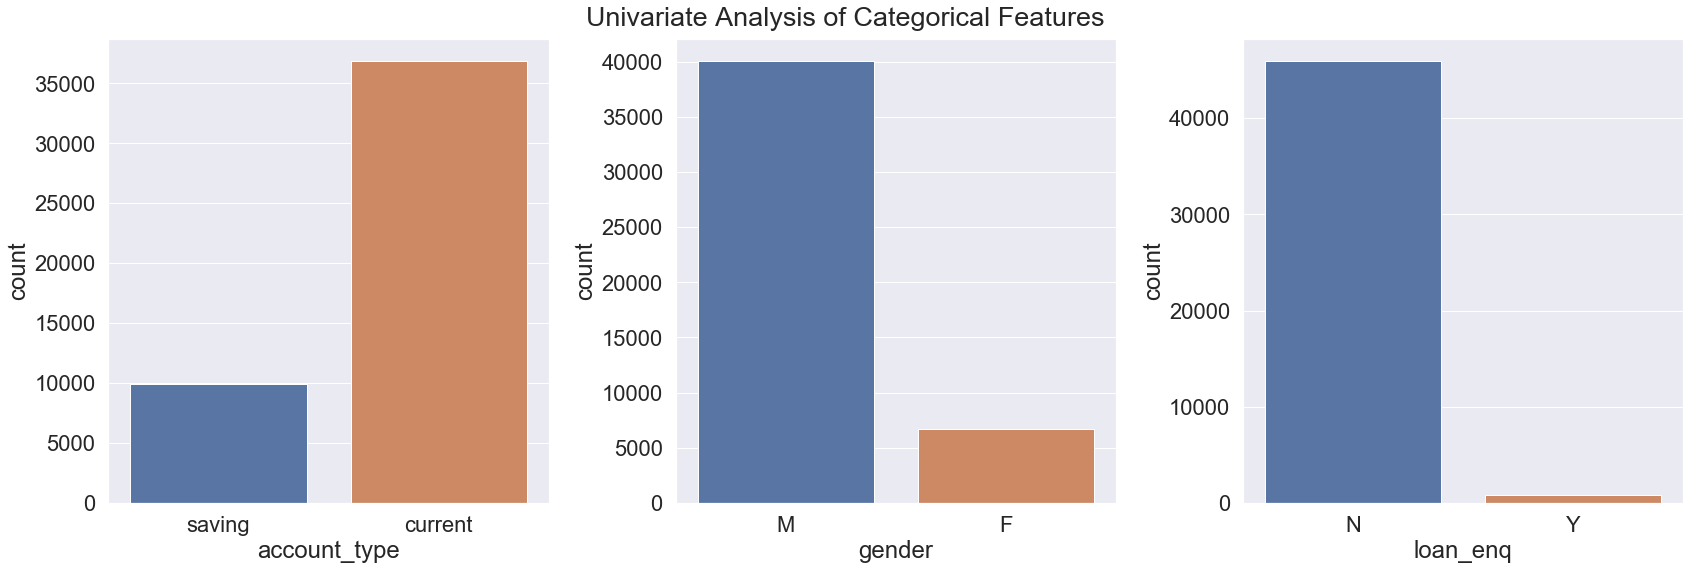

In [100]:
sns.set(font_scale=2.0)
fig = plt.figure(figsize=(24,8))
plt.suptitle("Univariate Analysis of Categorical Features", fontsize=27,y=1.01)
n = 1
for col in cc_spent[cat_cols]:
    plt.subplot(1,3,n)
    sns.countplot(cc_spent[col])
    n += 1
plt.tight_layout()
plt.show()
    

- Account type is of 'savings' and 'current'. 'current' account is mostly held by customers than savings account.

- Males are mostly spending credit/debit cards then Females.

- Loan_enquiry is carried out by 0.01% customers

We can also create categorical features from existing numerical features like debit cards consumption, investments_done or not
and emi's being active or not which have lot of sparsity in them.

### <font color='red'> Creating categorical features from existing Numerical features </font></b>

<b><i>Converting feature "dc_cons" to categorical type "dc_cons_avg" </b></i>

In [101]:
cc_spent['dc_cons_avg'] = (cc_spent['dc_cons_apr'] + cc_spent['dc_cons_may'] + cc_spent['dc_cons_jun']) / 3

In [102]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0.0,118845.2,50000.0,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,0.000000
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0.0,0.0,0.0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,1264.986667
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0.0,0.0,0.0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,1725.840000
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0.0,132442.0,0.0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,0.000000
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0.0,0.0,0.0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,0.000000


<b><i>Creating new column "emi_active_bins" from column "emi_active" </b></i>

In [103]:
cc_spent['emi_active_bins'] = cc_spent['emi_active'].copy(deep=True)

In [104]:
def num_to_obj(df,col):
    df[col] = df[col].astype('int')
    df.loc[df[col] != 0, col] = 1
    return df[col]

<b><i> Converting values present in columns "investment"[1, 2 and 3], "dc_cons_avg" and "emi_active_bins" into 0's and 1's </i></b>

In [105]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0.0,118845.2,50000.0,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,0.000000,0.00
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0.0,0.0,0.0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,1264.986667,4963.33
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0.0,0.0,0.0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,1725.840000,0.00
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0.0,132442.0,0.0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,0.000000,1238.18
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0.0,0.0,0.0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,0.000000,0.00


In [106]:
cc_spent['investment_1_bins'] = num_to_obj(cc_spent,'investment_1')
cc_spent['investment_2_bins'] = num_to_obj(cc_spent,'investment_2')
cc_spent['investment_3_bins'] = num_to_obj(cc_spent,'investment_3')
cc_spent['dc_cons_avg'] = num_to_obj(cc_spent,'dc_cons_avg')
cc_spent['emi_active_bins'] = num_to_obj(cc_spent,'emi_active_bins')

In [107]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,0,0,0,1,1
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,1,1,0,0,0
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,1,0,0,0,0
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,0,1,0,1,0
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,0,0,0,0,0


In [108]:
num_to_cat_cols = ['investment_1_bins','investment_2_bins','investment_3_bins','dc_cons_avg','emi_active_bins']

In [109]:
cc_spent[num_to_cat_cols] = cc_spent[num_to_cat_cols].astype('object')

In [110]:
cc_spent['investment_1_bins'] = cc_spent['investment_1'].replace({0:'No_Demat acct', 1:'Demat acct'})
cc_spent['investment_2_bins'] = cc_spent['investment_2'].replace({0:'No_FixedDeposit',1:'FixedDeposit'})
cc_spent['investment_3_bins'] = cc_spent['investment_3'].replace({0:'No_LifeInsurance',1:'LifeInsurance'})
cc_spent['dc_cons_avg'] = cc_spent['dc_cons_avg'].replace({0:'DC_notconsumed',1:'DC_consumed'})
cc_spent['emi_active_bins'] = cc_spent['emi_active_bins'].replace({0:'No_active_emi',1 : 'active_emi'})

In [111]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance


In [112]:
cat_feat = []

for col in cc_spent.select_dtypes("object"):
    cc_spent[col] = cc_spent[col].astype('category')
    cat_feat.append(col)

In [113]:
cat_feat

['account_type',
 'gender',
 'loan_enq',
 'dc_cons_avg',
 'emi_active_bins',
 'investment_1_bins',
 'investment_2_bins',
 'investment_3_bins']

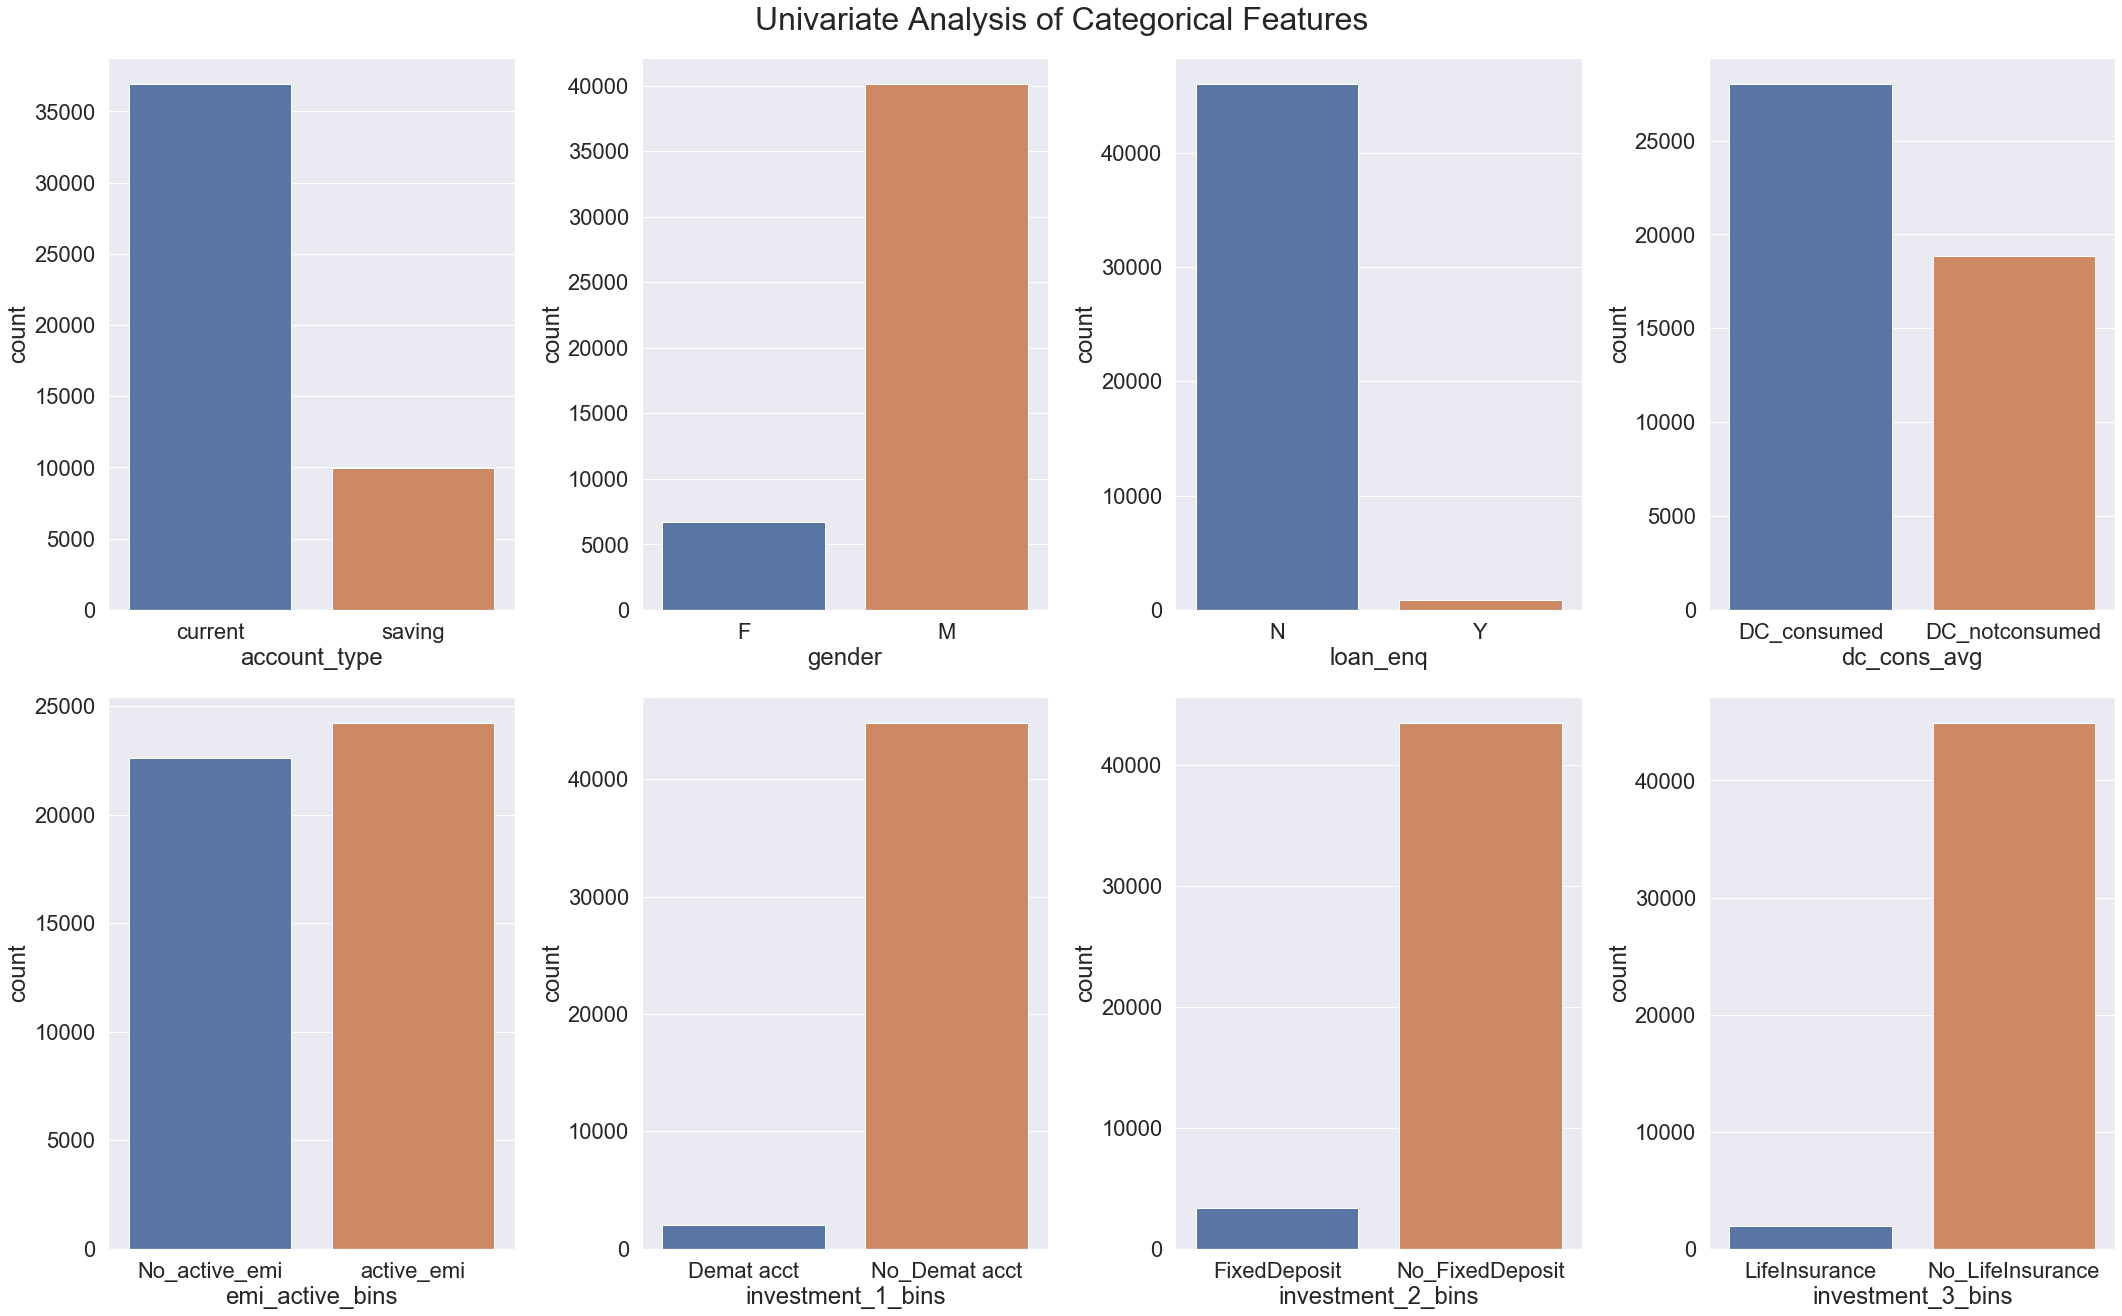

In [114]:
sns.set(font_scale=2.0)
fig = plt.figure(figsize=(30,35))
n = 1
for col in cc_spent[cat_feat]:
    plt.subplot(4,4,n)
    sns.countplot(cc_spent[col])
    n += 1
plt.suptitle("Univariate Analysis of Categorical Features",fontsize=32,y=1.01)
plt.tight_layout()
plt.show()
    

<b><i> Inferences from the above categorical features:- </i></b>

* Account type is of 'savings' and 'current'. 'current' account is mostly held by customers than savings account.

* Males are mostly spending credit/debit cards then Females.

* Loan_enquiry is carried out by 0.01% customers

* Only 0.04% of the customers have invested in Demat and Life Insurance while in Fixed Deposit Account only 0.07% of customers have invested in it.



### <font color='red'> Distribution of continuous features</font></b>

In [115]:
cont_cols = []
for col in cc_spent.select_dtypes(["int64","float64"]):
    cont_cols.append(col)

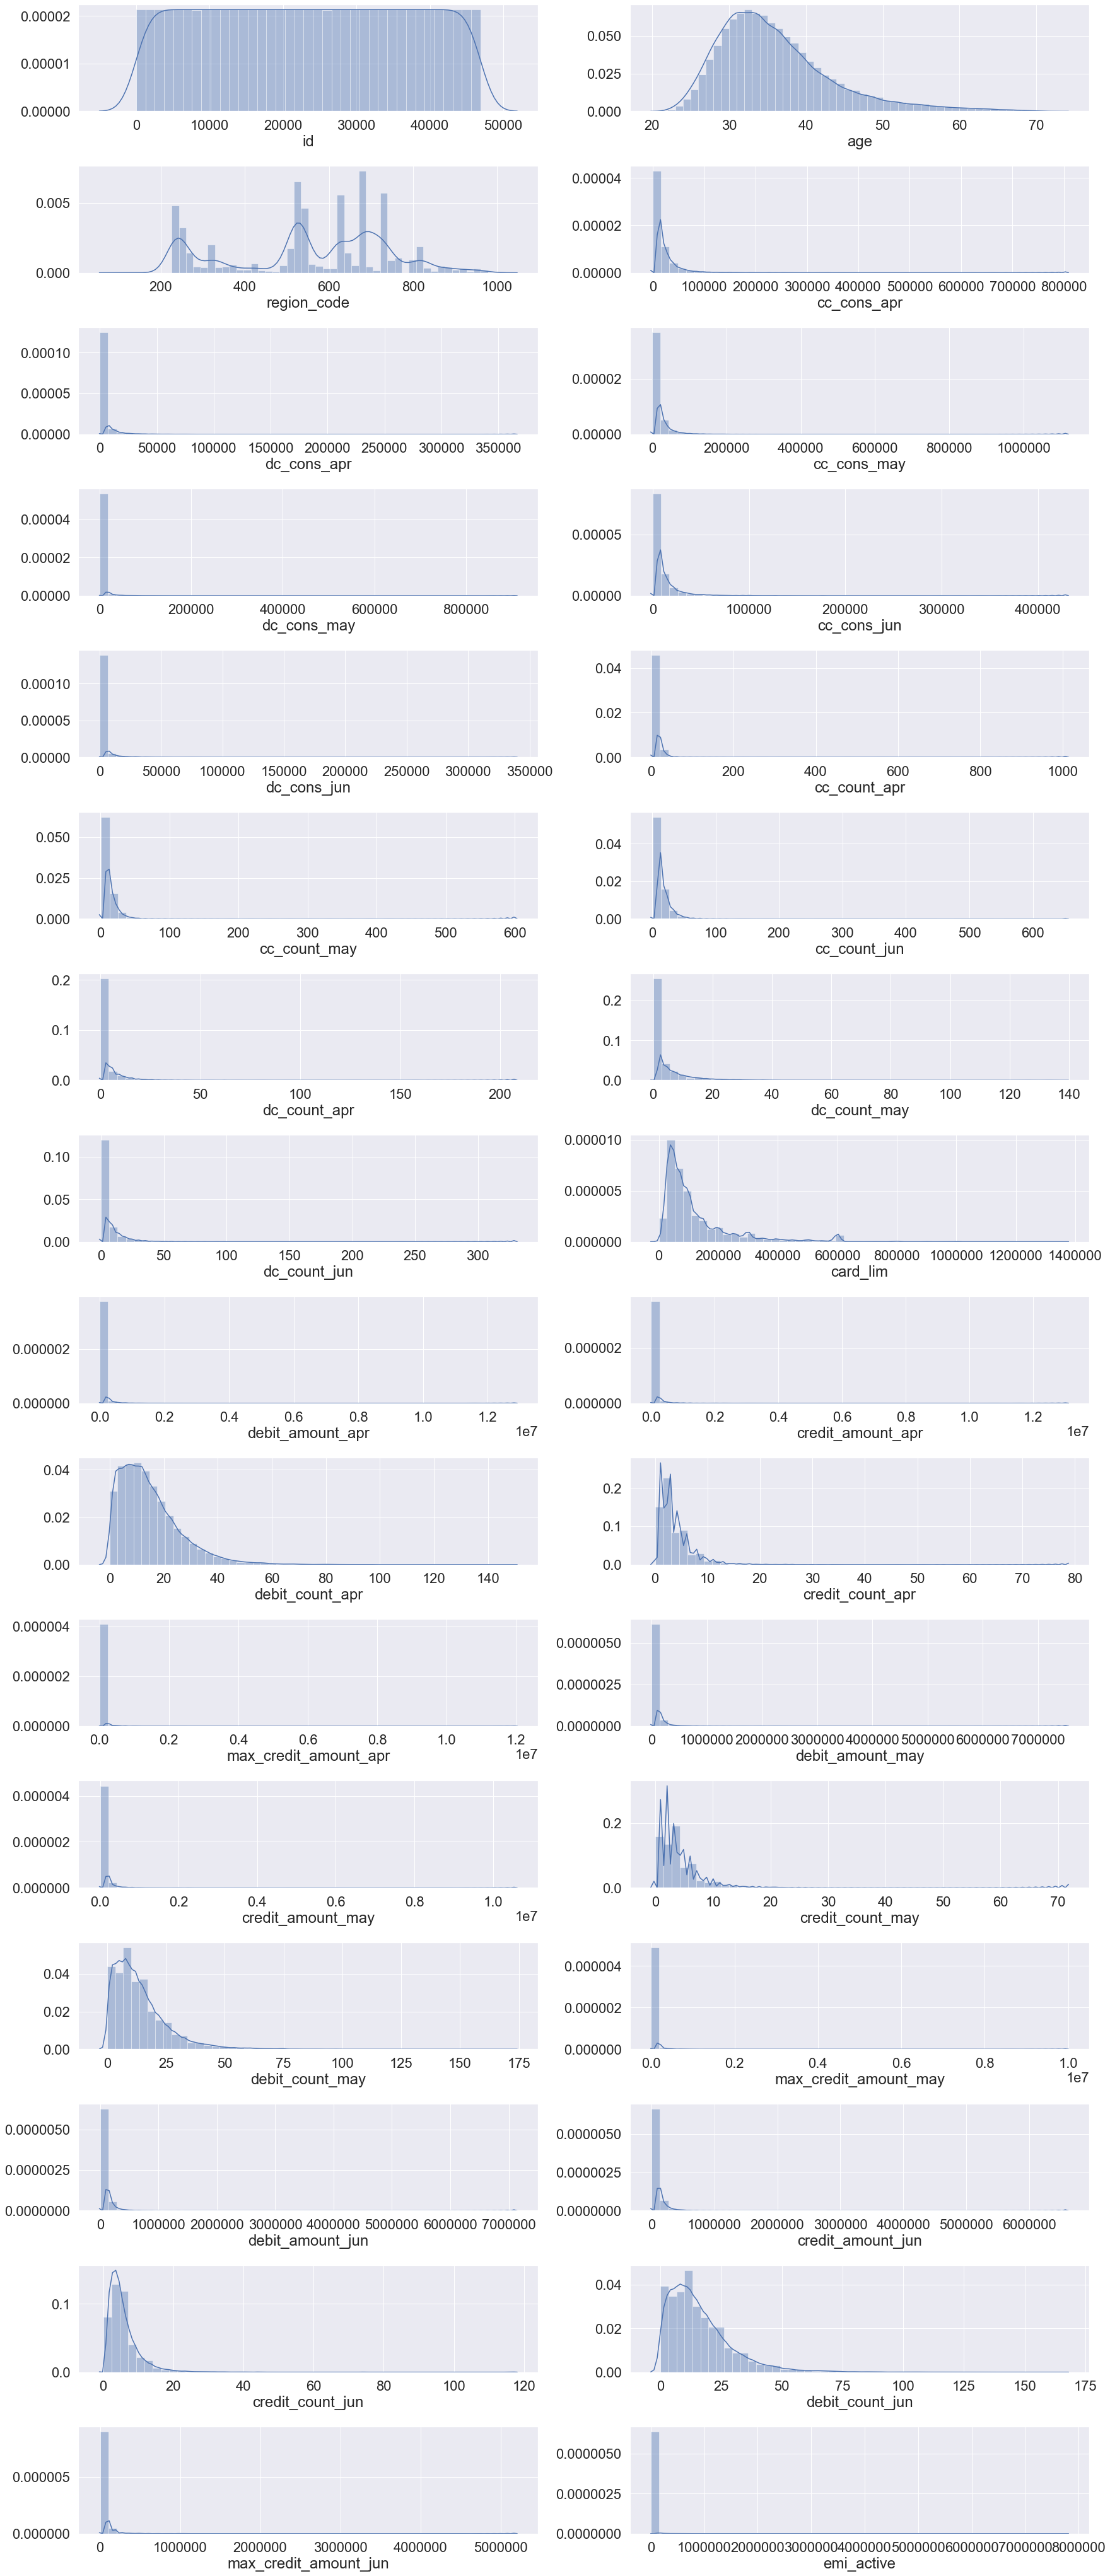

In [116]:
n=1
fig=plt.figure(figsize=(25,60))
for col in cc_spent_train[cont_cols]:
    if col !='cc_cons':
        plt.subplot(17,2,n)
        sns.distplot(cc_spent[col])
        n += 1

plt.tight_layout()
plt.show()

As we seen above mostly of the data was being highly skewed and we weren't able to visualize it properly. Hence, we will be considering out the 90% percentile data which has the maximum population lying in it and visualize it once again.

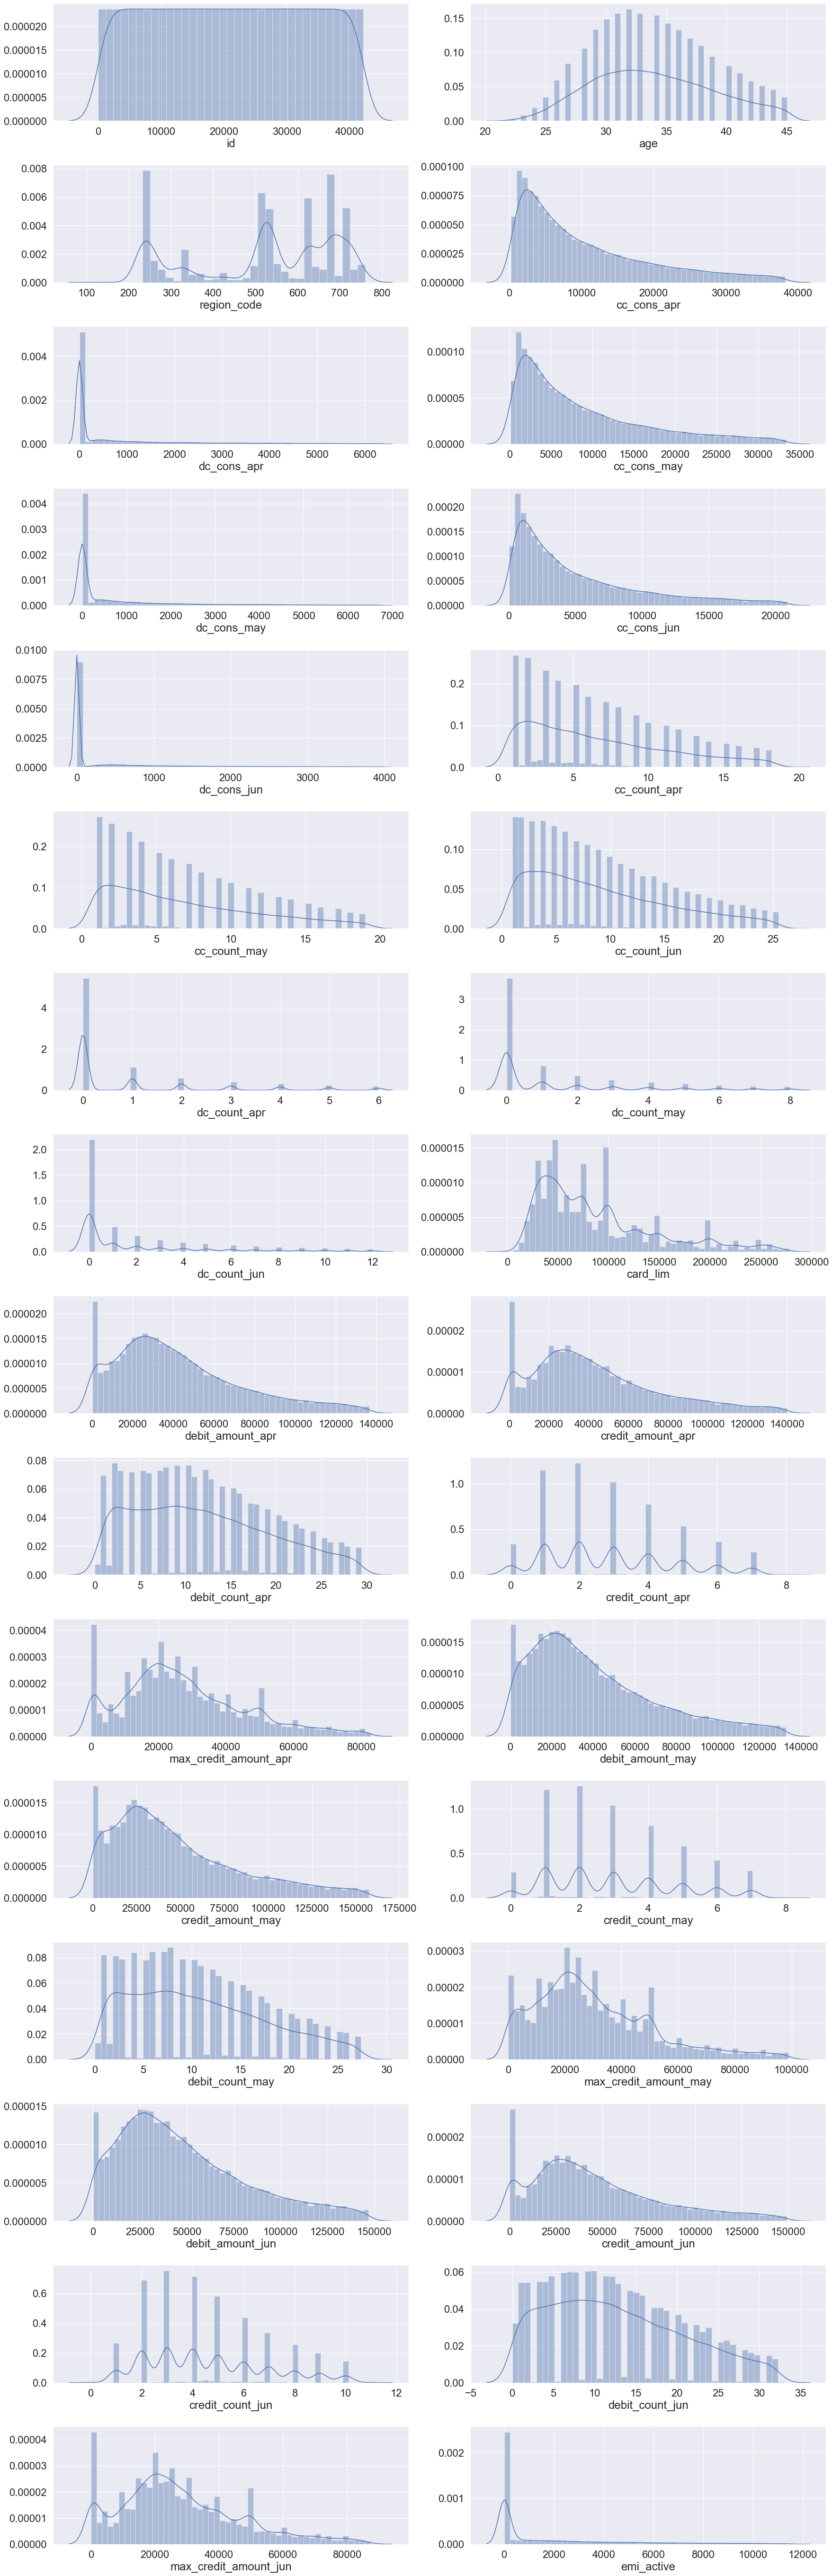

In [117]:
n=1
fig=plt.figure(figsize=(25,80))
for col in cc_spent[cont_cols]:
    if col !='cc_cons':
        plt.subplot(17,2,n)
        new_ccspent = cc_spent[cc_spent[col] < np.percentile(cc_spent[col], 90)]
        sns.distplot(new_ccspent[col])
        n += 1

plt.tight_layout()
plt.show()

### <font color='red'> Knowing the Skewness and Kurtosis of features</font>

<b><i> Skewness</i></b> : Skewness is a measure of the symmetry in a distribution.  A symmetrical dataset will have a skewness equal to 0.  So, a normal distribution will have a skewness of 0.   Skewness essentially measures the relative size of the two tails. 
    
<b><i> Kurtosis</i></b> : Kurtosis is a measure of the combined sizes of the two tails.
It measures the amount of probability in the tails. The value is often compared to the kurtosis
of the normal distribution , which is equal to 3. If the kurtosis is greater than 3, then the dataset
has heavier tails than a normal distribution.

Let us plot the skewed value and kurtosis value associated with each feature and get the inferences.

In [118]:
skew_dict = {}
kurtosis_dict = {}
for cols in cc_spent[cont_cols]:
    skew_dict[cols] = cc_spent[cols].skew()
    kurtosis_dict[cols] = cc_spent[cols].kurt()

In [119]:
skew_dict

{'id': -0.00013308900891054832,
 'age': 1.2257990993184622,
 'region_code': -0.34615050772966544,
 'cc_cons_apr': 6.314908101056371,
 'dc_cons_apr': 12.694377074313703,
 'cc_cons_may': 8.531194441976096,
 'dc_cons_may': 25.78928940817664,
 'cc_cons_jun': 6.892141074755219,
 'dc_cons_jun': 16.425717993288547,
 'cc_count_apr': 36.64022212557575,
 'cc_count_may': 7.58243166718234,
 'cc_count_jun': 5.80209676264183,
 'dc_count_apr': 5.6626292552813755,
 'dc_count_may': 4.151524398342336,
 'dc_count_jun': 4.772701114968136,
 'card_lim': 2.4417157775093643,
 'debit_amount_apr': 29.621395598559694,
 'credit_amount_apr': 32.278562540334285,
 'debit_count_apr': 1.6198144673100456,
 'credit_count_apr': 3.2893137151255987,
 'max_credit_amount_apr': 49.561751891515314,
 'debit_amount_may': 15.285586529723902,
 'credit_amount_may': 20.877636049419223,
 'credit_count_may': 3.4629227770935556,
 'debit_count_may': 1.8258283679034706,
 'max_credit_amount_may': 39.278231952824925,
 'debit_amount_jun': 1

In [120]:
skew_df = pd.DataFrame([skew_dict])
skew_trans_df = skew_df.T

In [121]:
skew_trans_df.columns = ['skewed_value']

In [122]:
skew_trans_df = skew_trans_df.sort_values(ascending=False,by=['skewed_value'])

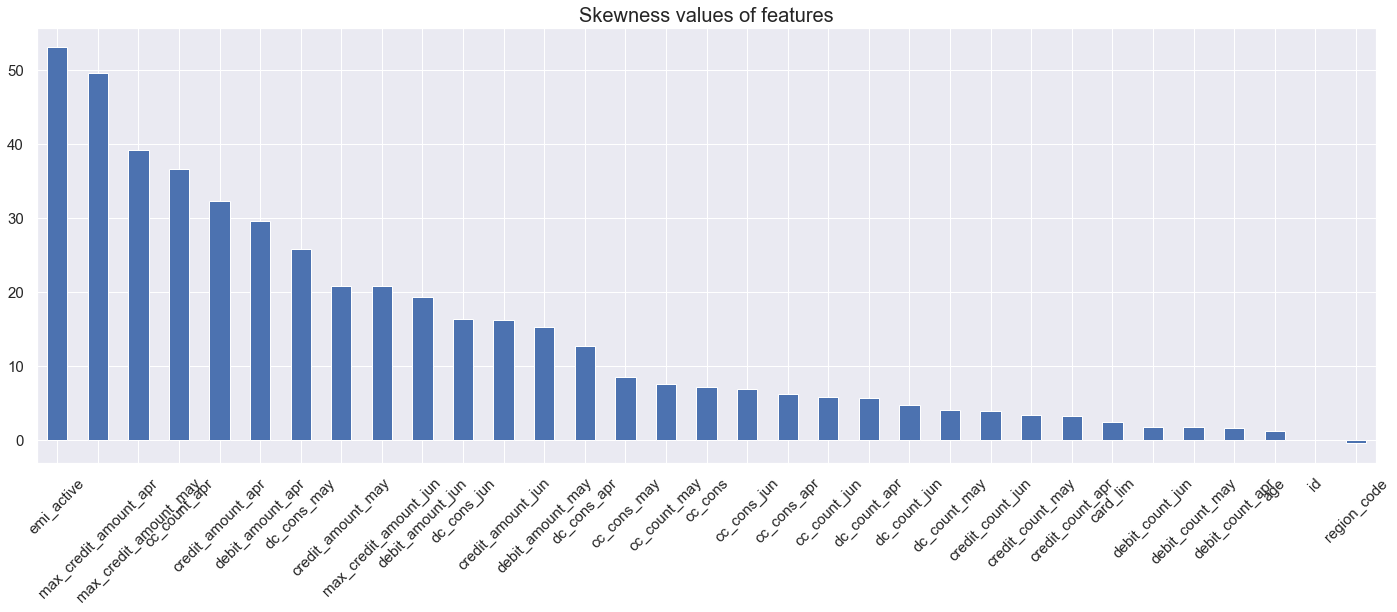

In [123]:
skew_trans_df.plot(kind='bar',figsize=(24,8),fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Skewness values of features",fontsize=20)
plt.show()

#####  Inferences from above Skewness Plot

* If skew value for features is < 0.5 it means it is symmetric. The above distplot also
depicts the columns 'age' and 'region_code' being symmetric. 
* While the other features have high skewness in them , column "emi_active" and "debit_amount_jun" are having highest skewness among them .If skew value > 1 , then feature is highly skewed towards right.
* Basic way to calculate skewness mathematically, is to use variance formula but the power needs to be changed to 3 from 2.

In [124]:
# Converting Kurtosis_dict to Kurtosis dataframe
kurtosis_df = pd.DataFrame([kurtosis_dict])
kurtosis_trans_df = kurtosis_df.T


In [125]:
kurtosis_trans_df.columns = ['kurtosis_value']

In [126]:
# Sorting values in descending order
kurtosis_trans_df = kurtosis_trans_df.sort_values(ascending=False, by=['kurtosis_value'])

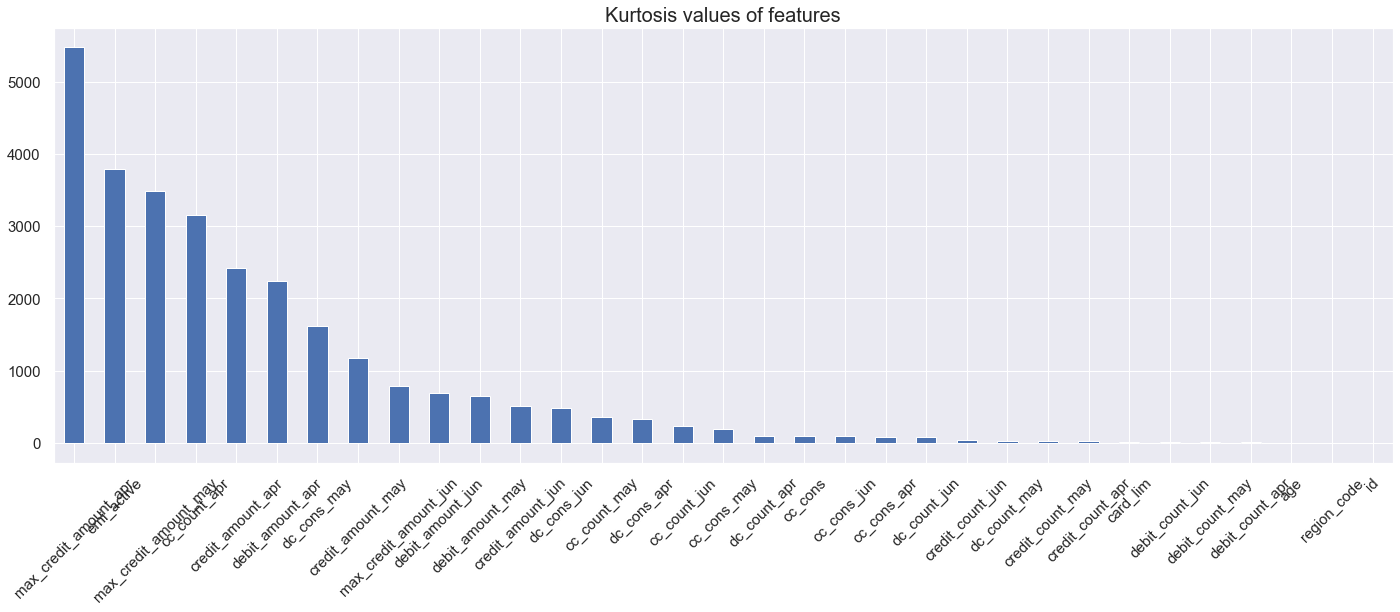

In [127]:
kurtosis_trans_df.plot(kind='bar',figsize=(24,8), fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Kurtosis values of features",fontsize=20)
plt.show()

#####  Inferences from Kurtosis plot

* The one which is having sharp peak has high kurtosis. One such feature is "emi_active".
* We cannot see any perfect normal distributions from graphs except age. Hence, the kurtosis values for those 
will be 0.
* The curve gets flattened for some features, they follow negative kurtosis. Features "region_code" and "age"
have negative kurtosis value.
* Basic way to calculate kurtosis mathematically, is to use variance formula but the power needs to be changed to 4 from 2.


Even though we have shown the skewness and kurtosis of various features for your understanding. We usually don't recommend it if the 
distribution is not normally distributed. 

##### Another way to analyze skewness would be :-
    
Visualize using PMF(Probability Mass Function) and see it again

### <font color='red'>Analysis on the categorical features with the target (cc_cons) </font>

##### <font color='red'> Relationship between account types and the credit card spent for next 3 months

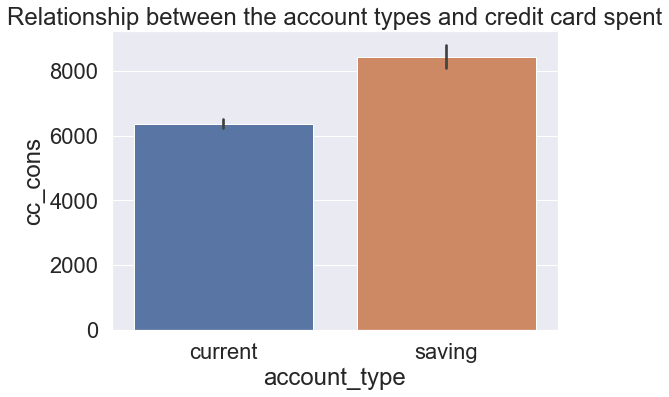

In [128]:
sns.barplot('account_type','cc_cons',data=cc_spent[:32820])
plt.title("Relationship between the account types and credit card spent")
plt.show()

Customers who are spending credit cards mainly hold Savings account. The "Current" accounts are mostly held by customers to carry out business transactions.

Feature "Gender" would not help us in predicting the spending pattern of credit card. Hence, we won't be doing
analysis on it.

##### <font color='red'> How age is a factor in knowning the credit card spend pattern??</font>

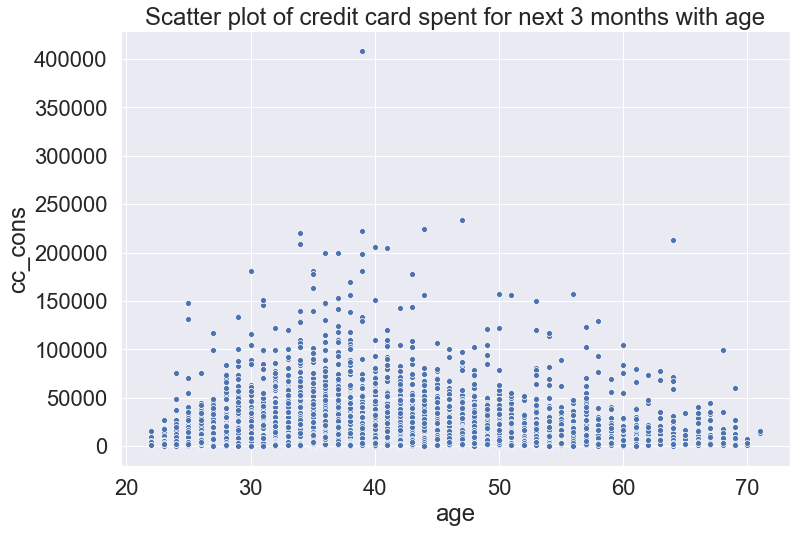

In [129]:
plt.figure(figsize=(12,8))
sns.scatterplot(x='age',y='cc_cons', data=cc_spent[:32820])
plt.title("Scatter plot of credit card spent for next 3 months with age")
plt.show()

As we can see from the figure, the plot is pretty messy with a clear distinction for the age groups 20-45 indicating a person in this range has more possibility for credit card spendings. However, the most common spend range is up to 100000. 

Let's bin the age column for easy understanding and visualization.

In [130]:
print("Min Age of consumers' :",min(cc_spent['age']))
print("Max Age of consumers' :",max(cc_spent['age']))

Min Age of consumers' : 22
Max Age of consumers' : 72


<b><i>Age bins</i></b>

In [131]:
cc_spent['age_bins'] = pd.cut(cc_spent.age,bins=[21,31,41,51,61,72],labels=['Adult','Middle-Aged-I','Middle-Aged-II','Middle-Aged-III','Old Aged'])

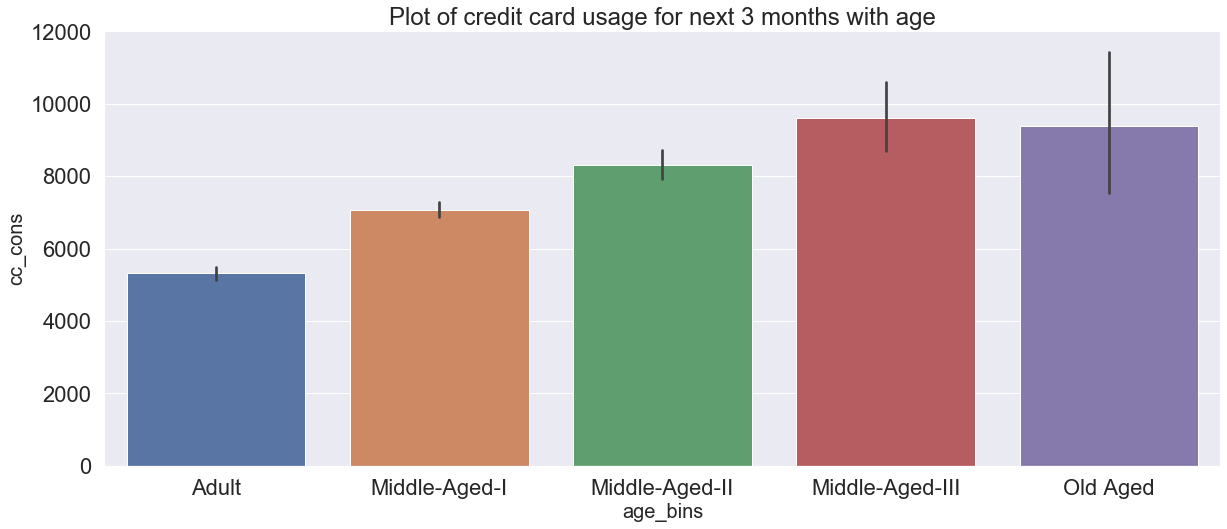

In [132]:
fig, ax = plt.subplots(figsize=(20,8))
sns.barplot('age_bins','cc_cons',data=cc_spent[:32820], ax=ax)
ax.set_xlabel('age_bins',fontsize=20)
ax.set_ylabel('cc_cons',fontsize=20)
plt.title("Plot of credit card usage for next 3 months with age",fontsize=24)
plt.show()

We observe that consumers who belong to Middle-Aged-III group comprising of ages 51-61 are the ones who will be spending a lot of credit amount in next few months. This could make sense because people in this age group are more likely to retire and they have necessity for extra money/credit. However, this might also be one of the riskiest groups to give credit since they might not have a stable income source following retirement.

##### <font color='red'> How does customer investment in Demat Acct, Fixed Deposit or Life Insurance and their spending pattern would rate them ? </font>

##### <font color='red'>What is the sole purpose of using Demat Account ? </font>

Demat Account provides facility of holding shares and securities in electronic format. During online trading, shares are brought 
and held in Demat Account, thus facilitating easy trade for the users. 

C:\Users\ashwi\Anaconda3\lib\site-packages\seaborn\categorical.py:1324: RuntimeWarning: invalid value encountered in less
  off_low = points < low_gutter
C:\Users\ashwi\Anaconda3\lib\site-packages\seaborn\categorical.py:1328: RuntimeWarning: invalid value encountered in greater
  off_high = points > high_gutter


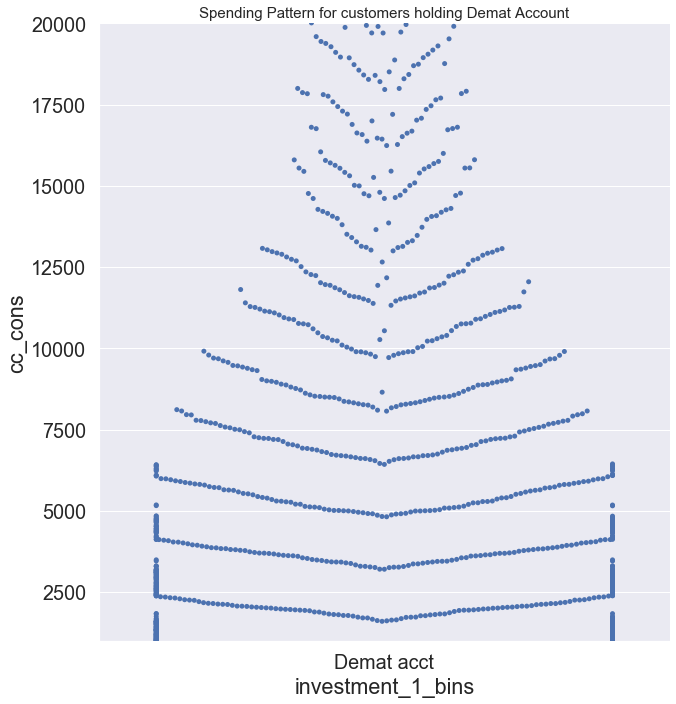

In [133]:
sns.set(font_scale=1.8)
sns.catplot(x='investment_1_bins',y='cc_cons',order=['Demat acct'],kind='swarm',data=cc_spent[:32820],height=10);
plt.ylim(1000,20000)
plt.title("Spending Pattern for customers holding Demat Account",fontsize=15)
plt.show()

Customers investing in the <b>Demat account</b> have to undergo lot of risks as they usually hold shares and securities in electronic format. Usually, during online trading shares are brought 
and held in Demat account, thus facilitating easy trade for the users. From above graph we see that customers who hold demat account
mostly have less credit spending pattern ranging from 4000 to 17000 on an average for next 3 months.

##### <font color='red'> What is a Fixed Deposit?? </font>

Fixed deposit is an investment offered by banks and non-banking financial companies , where you can deposit money for a higher
rate of interest than saving accounts. Here you can deposit a lump sum of money in fixed deposit for a specific period, which varies 
for every financier.

Once the money is deposited we cannot withdraw the money before maturity, but you may withdraw them after paying a penalty.

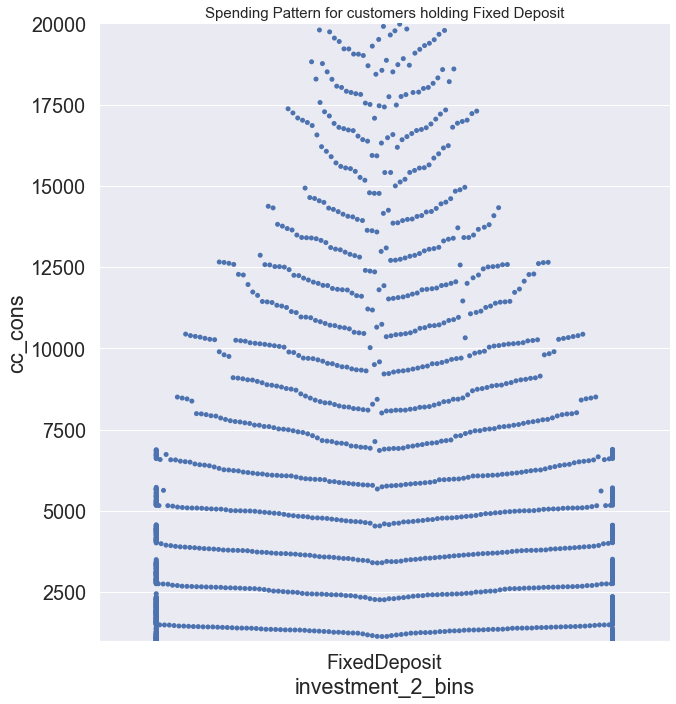

In [134]:
sns.set(font_scale=1.8)
sns.catplot(x='investment_2_bins',y='cc_cons',order=['FixedDeposit'],kind='swarm',data=cc_spent[:32820],height=10);
plt.ylim(1000,20000)
plt.title("Spending Pattern for customers holding Fixed Deposit",fontsize=15)
plt.show()

Customers who invest in "Fixed Deposit" have credit spending pattern ranging from 1000 to 17500 on an average for next 3 months. So, we can say that customers who spend money in investment spend less of credit card.

##### <font color='red'> What it is like investing in Life Insurance? </font>

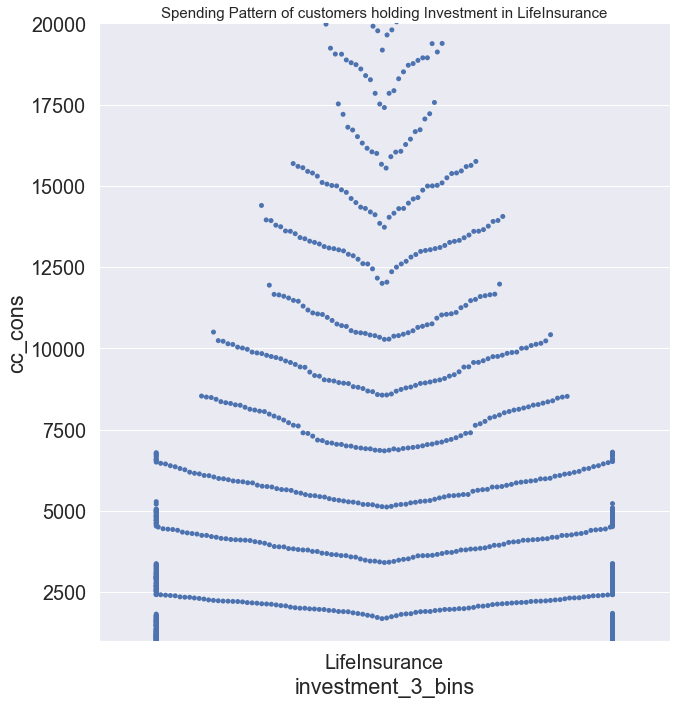

In [135]:
sns.set(font_scale=1.8)
sns.catplot(x='investment_3_bins',y='cc_cons',order=['LifeInsurance'],kind='swarm',data=cc_spent[:32820],height=10);
plt.ylim(1000,20000)
plt.title("Spending Pattern of customers holding Investment in LifeInsurance",fontsize=15)
plt.show()

Life Insurance is a contract between an insurer and a policyholder in which the insurer guarantees payment of a death benefit
to named beneficiaries upon the death of the insured. Investing in a Life Insurance is a risk factor as you can expect the benefit
only while via matures mostly the term for it would be more than 2 decades and so on. From the plot, we also see that the credit spent by customers
investing in Life Insurance ranges from 3750 to around 14000 range mostly for an average of 3 months.

Thus,we can say that consumers investing in various accounts have credit spending pattern ranging from 3000+ to 17000+ for an average of 3 months.

##### <font color='red'> How maximum card limit allocated is categorised for different age groups?</font>

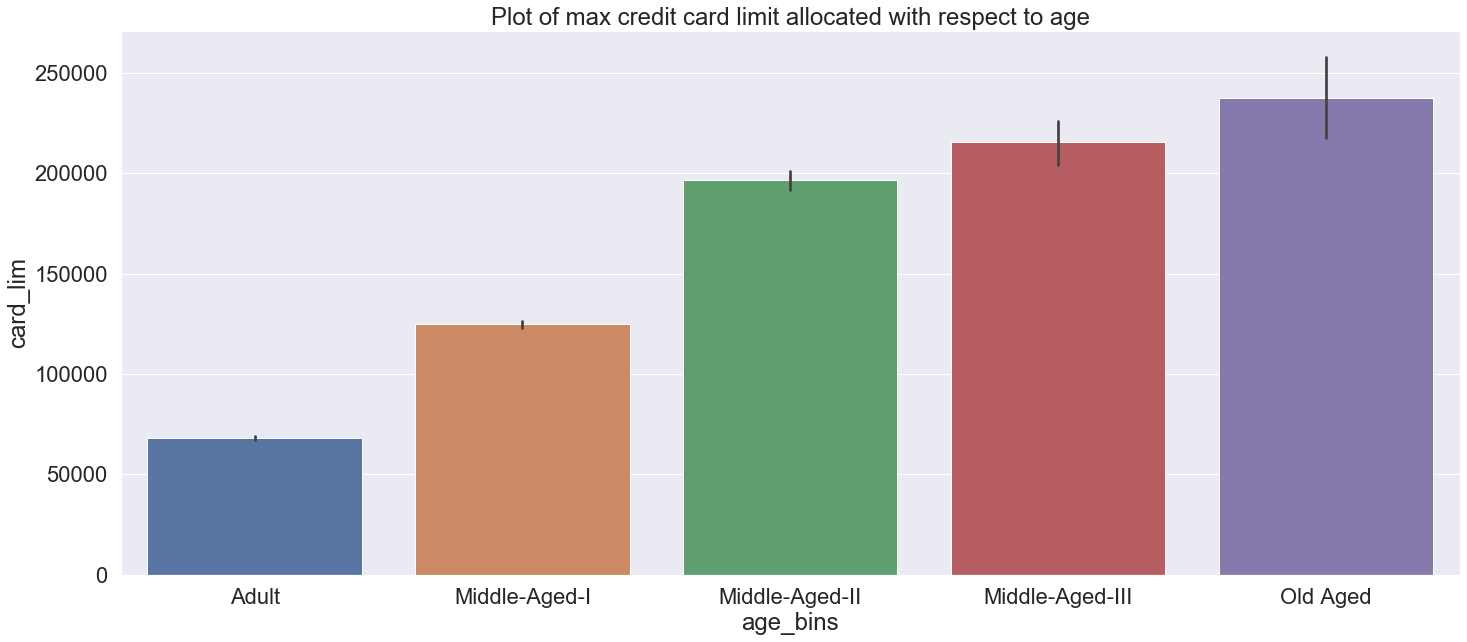

In [136]:
sns.set(font_scale=2)
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','card_lim',data=cc_spent[:32820], ax=ax)
ax.set_xlabel('age_bins')
ax.set_ylabel('card_lim')
plt.title("Plot of max credit card limit allocated with respect to age")
plt.show()

We see that as the age increases the credit limit for consumers is also increasing. Also, it can be
that the older people are maintaining good track record of holding credit cards. But, chances are older people will not spend as much as the younger counter-parts so allocating higher credit limit is only going to keep the amount locked which otherwise can be distributed for other loyal younger customers.

##### <font color='red'> Analysing the debt increase with age</font>

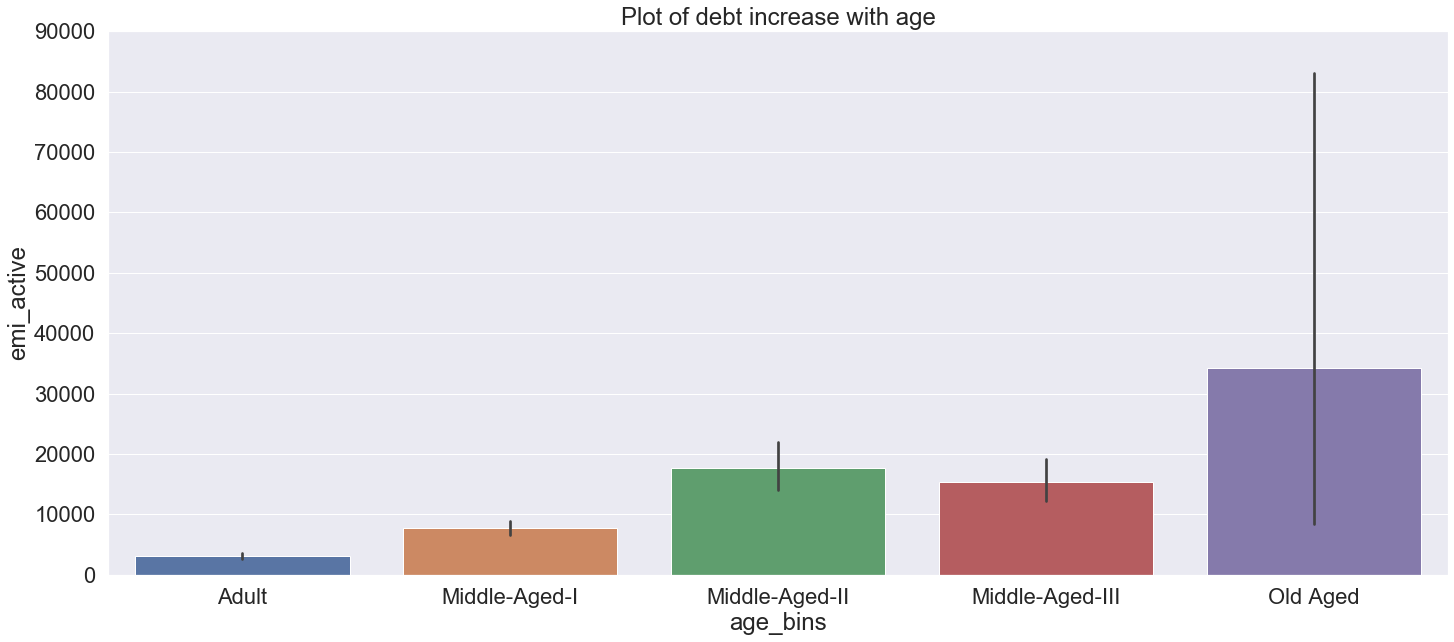

In [137]:
sns.set(font_scale=2)
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','emi_active',data=cc_spent[:32820], ax=ax)
ax.set_ylim(0,90000)
ax.set_xlabel('age_bins')
ax.set_ylabel('emi_active')
plt.title("Plot of debt increase with age")
plt.show()

In this scenario, the debts are nothing but the emi's which the consumers owe to other banks. The debt's 
increase over age and is following a left-skewed distribution, where it reaches at peak for the Middle-Aged-II age group
and gradually increases for Old Aged group.

##### <font color='red'> Why are such changes of credit card usage and debts occuring drastically??</font>

1. Credit cards help users to smooth over shocks.
2. By revolving debt over short and long terms, credit cards are a way of allocating life-cycle
consumption.
3. As a means of payment, spending on credit cards forms part of consumer expenditures.

##### <font color='red'> Which regions contribute most to spending of credit cards?</font>

Glimpse of the "region_code" column

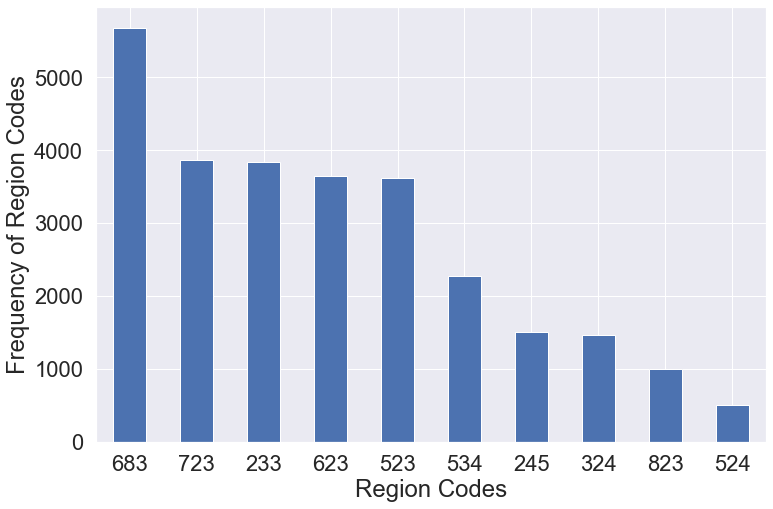

In [138]:
plt.figure(figsize=(12,8))
cc_spent['region_code'].value_counts()[:10].plot.bar()
plt.xticks(rotation=0)
plt.xlabel('Region Codes')
plt.ylabel('Frequency of Region Codes')
plt.show()

We see that cardholders/consumers are mostly from 683 region code followed by 723,233,623 and 523.

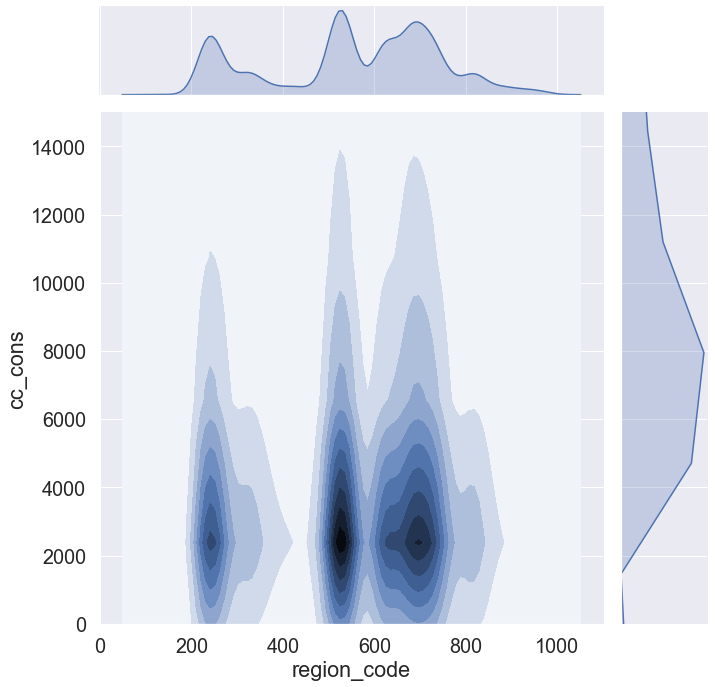

In [139]:
sns.set(font_scale=1.8)
sns.jointplot(x="region_code", y="cc_cons", data=cc_spent[:32820], n_levels=10, kind="kde",height=10);
plt.ylim(0,15000)
plt.show()

From above figure, we can infer that for region_code between 500-600, the spaces between lines are quite dense which 
means many cardholders belong to these region who spend the most. While for regions between 600-800,
the lines are apart when less carholders spend in this region. Also, near 150-200 you again see some
dense region where the usage of credit cards is more.

##### <font color='red'> How the debit consumption shows the credit spending pattern for average of next 3 months ? </font>

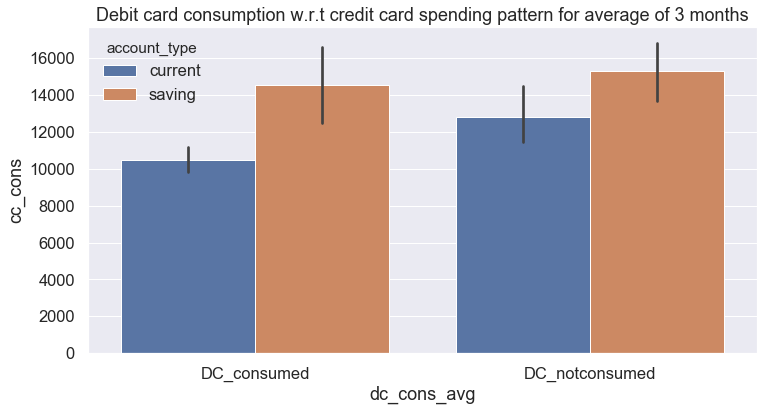

In [140]:
sns.set(rc={'figure.figsize':(12,6)},font_scale=1.5)
sns.barplot(x='dc_cons_avg',y='cc_cons',data = cc_spent[:32820],estimator=np.std,hue='account_type')
plt.title("Debit card consumption w.r.t credit card spending pattern for average of 3 months")
plt.show()

Above plot conveys the debit card consumed mostly by the "Savings" account type holders and their credit card consumption ranges from 12000 to 16000 for next 3 months. The Savings are mostly held by Salaried people and also retirement age people. They might be spending credit cards in buying products within affordable range and clearing it through EMI's , that is why you can see that credit spent is also not too huge.

##### <font color='red'> Understanding the pattern of credit card spent across April, May and June </font>

In [141]:
def cc_dc_pattern(df,col1,col2,col3,col4,col5,col6,low_xl,high_xl):
    sns.set()
    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True,figsize=(12,8))
    ax1 = plt.subplot(2, 1, 1)
    ax1 = sns.distplot(df[col1], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col1)
    ax1= sns.distplot(df[col2],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col2)
    ax1= sns.distplot(df[col3],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col3)
    ax1.set_xlabel("")
    ax1.set_title("Credit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    print("")
    
    ax2 = plt.subplot(2, 1, 2)
    ax2 = sns.distplot(df[col4], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col4)
    ax2= sns.distplot(df[col5],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col5)
    ax2= sns.distplot(df[col6],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col6)
    ax2.set_xlabel("")
    ax2.set_title("Debit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    plt.tight_layout()
    plt.show()
    
    
    
    

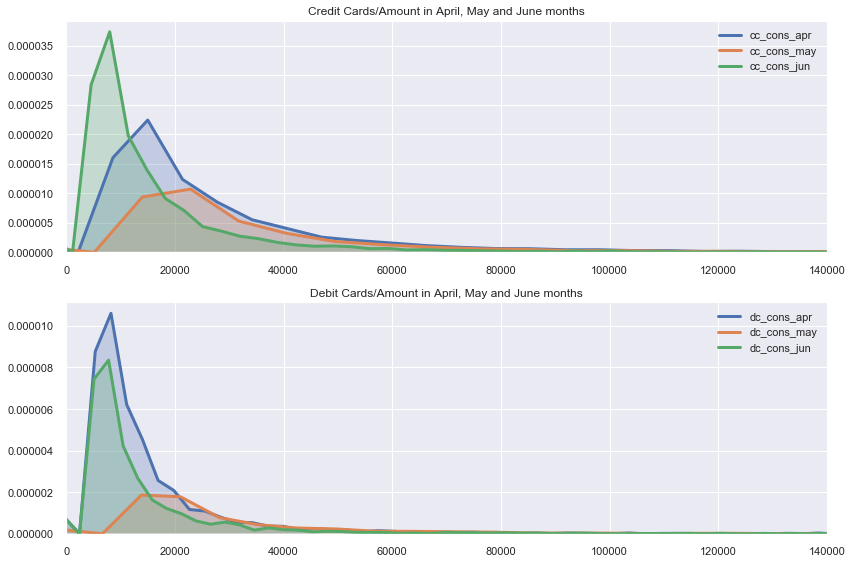

In [142]:
cc_dc_pattern(cc_spent,'cc_cons_apr','cc_cons_may','cc_cons_jun','dc_cons_apr','dc_cons_may',
              'dc_cons_jun',0,140000)

In [143]:
cc_cons_lst = ['cc_cons_apr','cc_cons_may','cc_cons_jun']


In [144]:
cc_spent[cc_cons_lst].describe()


,cc_cons_apr,cc_cons_may,cc_cons_jun
count,46830.000000,4.683000e+04,46830.000000
mean,16569.463572,1.432323e+04,8934.487735
std,24856.733152,2.321540e+04,15598.839844
min,233.970000,1.030000e+02,51.000000
25%,3689.832500,2.969883e+03,1625.195000
50%,8893.640000,7.336085e+03,4107.500000
75%,19892.715000,1.679275e+04,10010.000000
max,804712.580000,1.117246e+06,429522.430000


<b><i>Credit Card spending pattern(April, May and June)</i></b>
1. We see that deviation for month of June is around 15000+ compared to May and April months which have deviations of 25000+.
2. So, we see a narrow curve in June in comparison to May and April months.
3. Also, IQR values for June Month is about 8000+ and for May and April it's about 13000+ and 16000+ respectively.


<b><i><font color='red'>Credit card usage pattern individually for 3 months through mean</font></i></b>

In [145]:
# Credit cards spent(mean and std)

cc_spent['cc_cons_monthly_average'] =(cc_spent['cc_cons_apr'] + cc_spent['cc_cons_may'] + cc_spent['cc_cons_jun']) / 3


In [146]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_cons_corr_lst= ['cc_cons_monthly_average','cc_cons']
cc_spent[cc_cons_corr_lst].corr()

,cc_cons_monthly_average,cc_cons
cc_cons_monthly_average,1.000000,0.429539
cc_cons,0.429539,1.000000


We see that 43% of consumers are likely to spend in the same way for next 3 months . However, 28% of consumers
are a bit inconsistent in their spending pattern for avg of next 3 months.

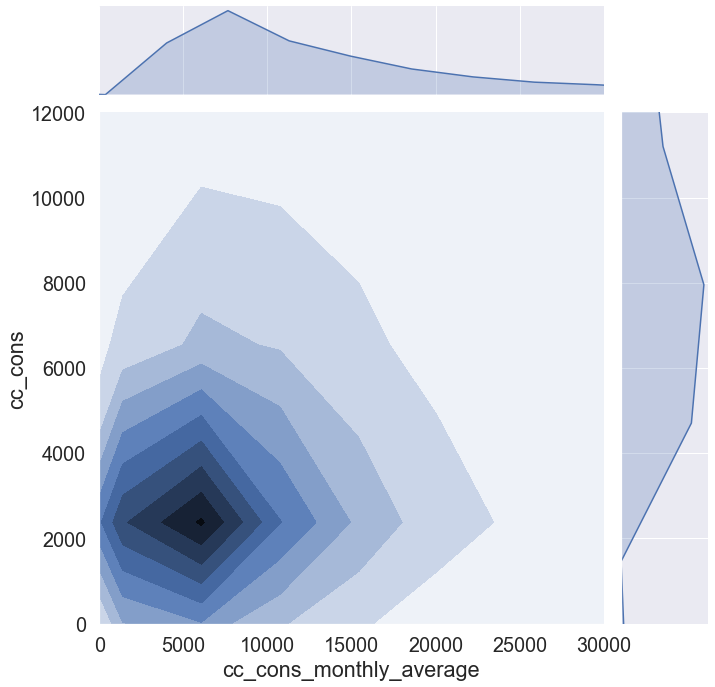

In [147]:
sns.set(font_scale=1.8)
plot = sns.jointplot(x='cc_cons_monthly_average',y='cc_cons',data=cc_spent[:32820], kind='kde',height=10);
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

The above graph shows a darker region around 0-10000, which is nothing but the credit amount being
spent on an average basis. However, the credit amount spent for next 3 months is around 1500-3000 range.
This indicates many consumers are spending credit card in this region. As the shape of the figure expands,
it becomes lighter and lighter which means there are few consumers spending credit amount in this region. 

Likewise, we can get the debit card spent for 3 months

In [148]:
cc_spent['dc_cons_monthly_average'] = (cc_spent['dc_cons_apr'] + cc_spent['dc_cons_may'] + cc_spent['dc_cons_jun']) / 3

##### <font color='red'> Ratio of Credit card and Debit card spent for all 3 months

Capturing ratio of credit to debit helps us know the spending pattern more better. Here, we will be getting the ratio across 3 months

In [149]:
cc_spent['ratio_cc_dc_cons'] = cc_spent['cc_cons_monthly_average'] / cc_spent['dc_cons_monthly_average']

In [150]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,...,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,...,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,inf
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,...,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,...,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,...,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,inf
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,...,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,inf


We now get a ratio of credit_card spent and debit_card spent for overall 3 months.

##### <font color='red'> Credit card spending ratio by checking the card limit</font>

The credit card spending ratio is calculated by dividing the average amount spent on credit card to the credit card limit allocated .

In [151]:
cc_spent['cc_cons_ratio'] = cc_spent['cc_cons_monthly_average'] / cc_spent['card_lim']

In [152]:
# Retaining the decimal places to only 4
cc_spent['cc_cons_ratio'] = cc_spent['cc_cons_ratio'].round(4) * 100

In [153]:
cc_spent['cc_cons_ratio'].head()

0     1.95
1    15.85
2    17.25
3     1.93
4     1.93
Name: cc_cons_ratio, dtype: float64

Let us now find out the relationship of the spent ratio with the credit card spent in next 3 months.

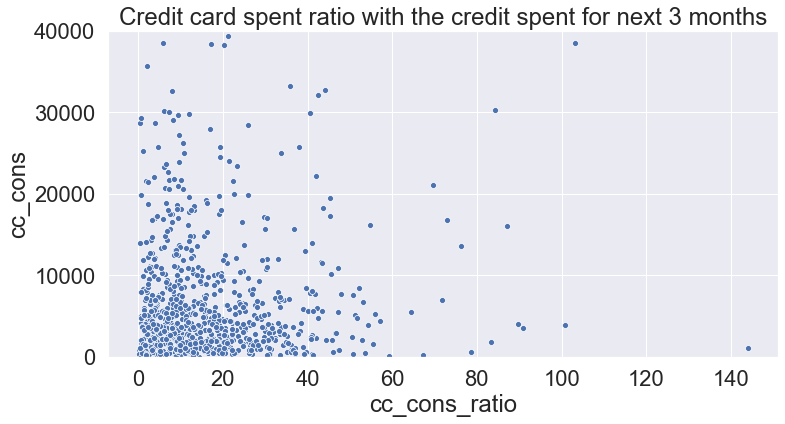

In [154]:
sns.set(font_scale=2)
ax = sns.scatterplot(x='cc_cons_ratio', y='cc_cons', data=cc_spent[:1000])
ax.set(ylim=(0,40000))
plt.title("Credit card spent ratio with the credit spent for next 3 months")
plt.show()

We see that there is more concentration in spent_ratio region i.e 0-20. We also observe that there is a direct
correlation of spent ratio with the credit amount being spent for next 3 months.

##### <font color='red'> How increase in credit spent causes increase in debt ?</font>

We often foresight that if the credit amount being spent increases, there might be chances that the
debt also increases. Let us understand this better through a graph.

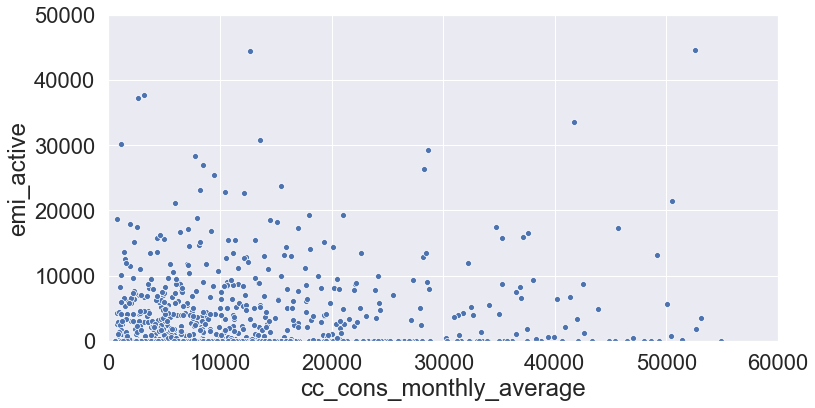

In [155]:
sns.set(font_scale=2)
ax = sns.scatterplot(x='cc_cons_monthly_average',y='emi_active',data=cc_spent[:1000])
ax.set_xlim(0,60000)
ax.set_ylim(0,50000)
plt.show()

Above graph says , even  though the rate of spending credit card is increasing across the scale
the active loans/debts being paid is not enormous , except few cases that may lead to bankruptcy.

##### <font color='red'>Understanding the credit card transactions for the month of April, May and June </font>

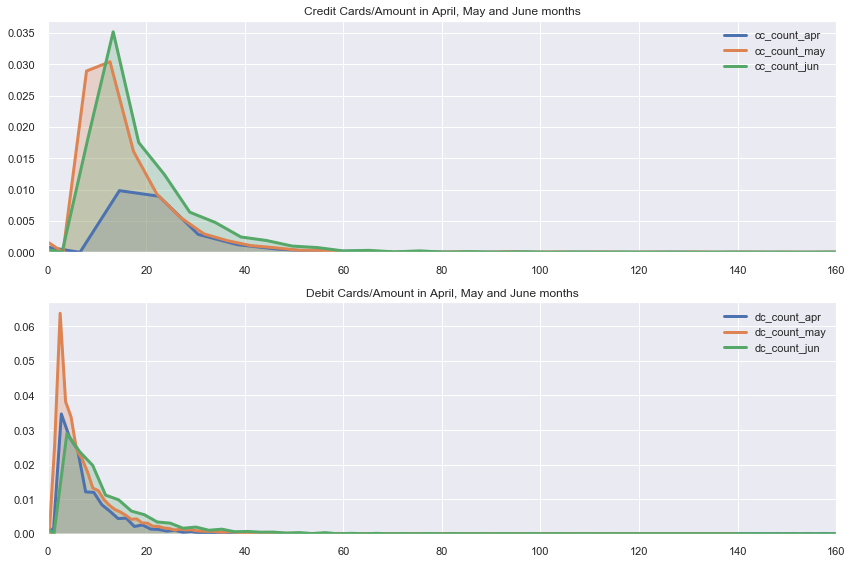

In [156]:
cc_dc_pattern(cc_spent,'cc_count_apr','cc_count_may','cc_count_jun','dc_count_apr',
             'dc_count_may','dc_count_jun',0,160)


In [157]:
cc_count_lst = ['cc_count_apr','cc_count_may','cc_count_jun']

In [158]:
cc_spent[cc_count_lst].describe()

,cc_count_apr,cc_count_may,cc_count_jun
count,46830.000000,46830.000000,46830.000000
mean,8.902868,9.309086,11.989417
std,10.913675,9.310588,11.297488
min,1.000000,1.000000,1.000000
25%,3.000000,3.000000,4.000000
50%,6.000000,7.000000,9.000000
75%,12.000000,12.764391,16.000000
max,1012.000000,601.000000,653.000000


##### <font color='red'> Number of Credit card transactions in April, May and June</font>

The transactions for May month is quite sharp , as there are less deviation in the pattern. That means most people are
doing transactions in the same range. For June month , also it follows the same pattern.When you see the April Month, the max value is quite large. So, it means there are
high transactions in this month.

##### <font color='red'> Debit/Card Transactions carried out on an individual level</font>

In [159]:
# Credit Transactions
cc_spent['cc_trans_monthly_avg'] =(cc_spent['cc_count_apr'] + cc_spent['cc_count_may'] + cc_spent['cc_count_jun']) / 3

In [160]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_count_corr_lst = ['cc_trans_monthly_avg','cc_cons']
cc_spent[cc_count_corr_lst].corr()

,cc_trans_monthly_avg,cc_cons
cc_trans_monthly_avg,1.000000,0.099252
cc_cons,0.099252,1.000000


We don't observe any relation with credit card transactions helping us predict the credit card spent for next 3 months.

On knowing the credit card transactions, let us calculate the weighted average of credit card amount
being spent , considering the transactions as the weights and get the insights.

In [161]:
# Let us get the weighted average of amount spent by considering weights of transactions
cc_spent['weighted_avg_cc_cons'] = ((cc_spent['cc_cons_apr'] * cc_spent['cc_count_apr'])
                                  + (cc_spent['cc_cons_may'] * cc_spent['cc_count_may'])
                                  + (cc_spent['cc_cons_jun'] * cc_spent['cc_count_jun'])) / (cc_spent['cc_count_apr'] + cc_spent['cc_count_may'] + cc_spent['cc_count_jun'])

In [162]:
weigh_avg_cc_lst = ['weighted_avg_cc_cons','cc_cons']
cc_spent[weigh_avg_cc_lst].corr()

,weighted_avg_cc_cons,cc_cons
weighted_avg_cc_cons,1.000000,0.418507
cc_cons,0.418507,1.000000


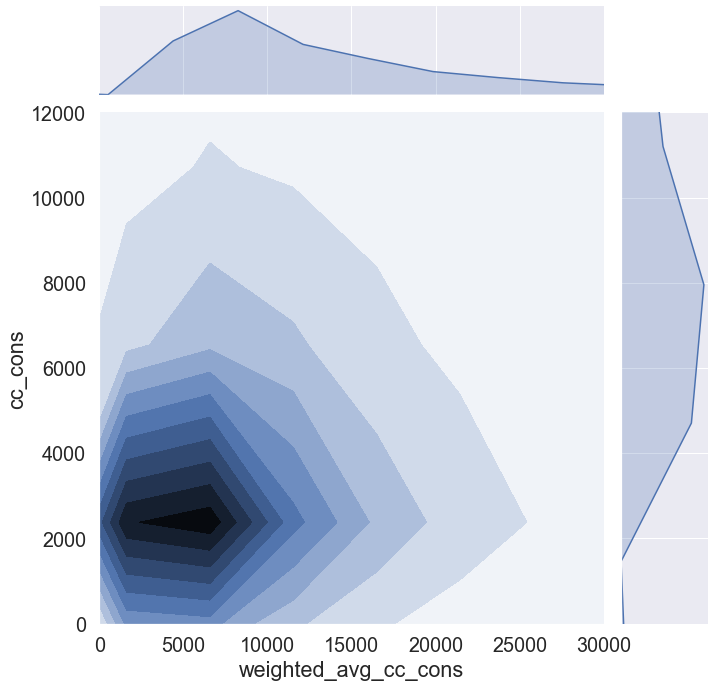

In [163]:
sns.set(rc={'figure.figsize':(12,10)},font_scale=1.8)
plot = sns.jointplot(x='weighted_avg_cc_cons',y='cc_cons',data=cc_spent[:32820], kind='kde',height=10);
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

However, we are observing the same kind of graph through the weighted average as well.

##### <font color='red'> Total amount credited/debited for the months of April, May and June</font>


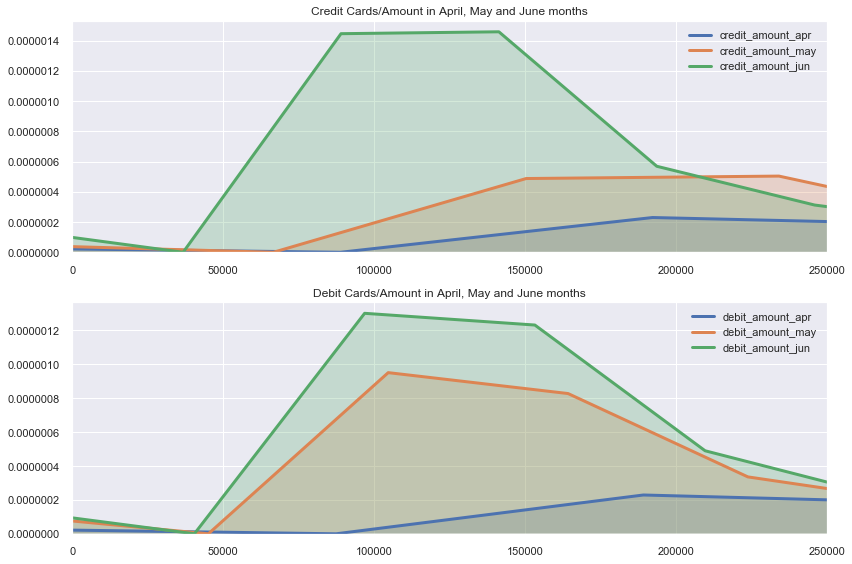

In [164]:
cc_dc_pattern(cc_spent,'credit_amount_apr','credit_amount_may','credit_amount_jun',
             'debit_amount_apr','debit_amount_may','debit_amount_jun',0,250000)



In [165]:
credit_amt_lst = ['credit_amount_apr','credit_amount_may','credit_amount_jun']
cc_spent[credit_amt_lst].describe()

,credit_amount_apr,credit_amount_may,credit_amount_jun
count,4.683000e+04,4.683000e+04,4.683000e+04
mean,6.976448e+04,7.374198e+04,7.266955e+04
std,1.390492e+05,1.277762e+05,1.349466e+05
min,3.432000e+01,1.061000e+01,1.188000e+01
25%,2.274750e+04,2.252600e+04,2.345950e+04
50%,4.159900e+04,4.340575e+04,4.349400e+04
75%,7.591893e+04,8.508550e+04,8.042315e+04
max,1.310058e+07,1.060175e+07,6.611953e+06


<b>< Observations from graph on Total number of credit amount in months of April, May and June</b>

1. June month is having wide fluctuation from the months of May and April .
2. When we look at the IQR's for June, May and April respectively we achieve about 56000+, 62000+ and
53000+ credit amounts respectively. But when it comes to the maximum value of credit amount it is upto 1000000+ for April month respectively
which is such a huge gap from 53000+ to 10000000+. Hence, you can see a wider curve for April.

##### <font color='red'> Knowing the Credit Amount spent individually for 3 months

In [166]:
# Credit Card
# Monthly Avg
cc_spent['cc_amount_monthly_avg'] = (cc_spent['credit_amount_apr'] + cc_spent['credit_amount_may'] +
                                               cc_spent['credit_amount_jun']) / 3

In [167]:
cc_amt_corr_lst = ['cc_amount_monthly_avg','cc_cons']
cc_spent[cc_amt_corr_lst].corr()

,cc_amount_monthly_avg,cc_cons
cc_amount_monthly_avg,1.000000,0.109377
cc_cons,0.109377,1.000000


Here, too the correlation between monthly avg . credit amount and std. deviation is ~9.5% and ~6.5%
respectively, which is very low. That means the total credit amount doesn't help us in determining the spending pattern.

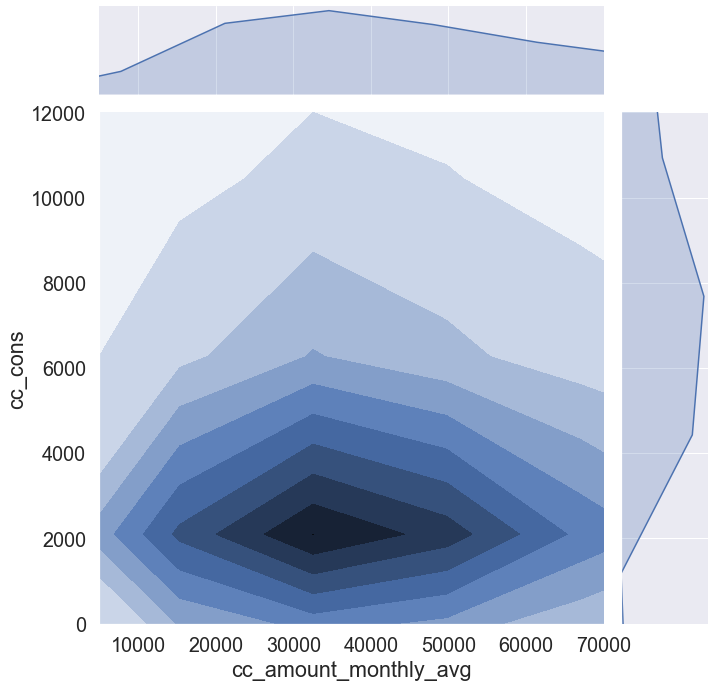

In [168]:
sns.set(font_scale=1.8)
plot = sns.jointplot(x='cc_amount_monthly_avg',y='cc_cons',data=cc_spent[:15000], kind='kde', height=10);
plot.ax_marg_x.set_xlim(5000,70000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

Credit amount being spent on a monthly basis is aroung 10000-70000 and the expected credit amount to
be spent for next 3 months is in the range (1500-6000).

Similarly, let us calculate the "debit_amount" spent overall for 3 months

In [169]:
cc_spent['dc_amount_monthly_avg'] = (cc_spent['debit_amount_apr'] + cc_spent['debit_amount_may'] + cc_spent['debit_amount_jun'])/3

##### <font color='red'> Ratio of credit and debit amount spent for overall 3 months</font>

In [170]:
cc_spent['ratio_cc_dc_amount'] = cc_spent['cc_amount_monthly_avg'] / cc_spent['dc_amount_monthly_avg']

In [171]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,...,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,...,55390.00,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,inf,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,...,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,...,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,...,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,inf,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,...,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,inf,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082


##### <font color='red'> Overall max credit amount for 3 months</font>

In [172]:
# Finding Mean of max credit amount
cc_spent['cc_max_amt_monthly_avg'] = (cc_spent['max_credit_amount_apr'] + cc_spent['max_credit_amount_may']
                                           + cc_spent['max_credit_amount_jun']) / 3


##### <font color='red'> How to get the bill paid by customer per transaction? </font>

In [173]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,...,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,...,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,inf,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,...,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656,15433.333333
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,...,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058,8866.666667
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,...,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,inf,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,...,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,inf,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000


##### <font color='red'> Ratio of Credit and Debit cons with every 2 months at a time <font>

##### Credit Card Transactions carried out for 2 consecutive months

In [174]:
First_cc_cons = (cc_spent['cc_cons_apr'] + cc_spent['cc_cons_may'])/2
Second_cc_cons = (cc_spent['cc_cons_may'] + cc_spent['cc_cons_jun'])/2
Third_cc_cons = (cc_spent['cc_cons_apr'] + cc_spent['cc_cons_jun'])/2

In [175]:
cc_spent['cc_cons_2month'] = First_cc_cons + Second_cc_cons + Third_cc_cons

##### Debit Card Transactions carried out for 2 consecutive months

In [176]:
First_dc_cons = (cc_spent['dc_cons_apr'] + cc_spent['dc_cons_may'])/2
Second_dc_cons = (cc_spent['dc_cons_may'] + cc_spent['dc_cons_jun'])/2
Third_dc_cons = (cc_spent['dc_cons_apr'] + cc_spent['dc_cons_jun'])/2

In [177]:
cc_spent['dc_cons_2month'] = First_dc_cons + Second_dc_cons + Third_dc_cons

In [178]:
cc_spent['ratio_cc_dc_cons_2month'] = cc_spent['cc_cons_2month'] / cc_spent['dc_cons_2month']

In [179]:
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,...,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg,cc_cons_2month,dc_cons_2month,ratio_cc_dc_cons_2month
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,...,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,inf,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333,8796.00,0.00,inf
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,...,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656,15433.333333,83662.00,3794.96,22.045555
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,...,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058,8866.666667,33628.13,5177.52,6.495027
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,...,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,inf,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333,34808.50,0.00,inf
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,...,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,inf,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000,5785.12,0.00,inf


##### Credit spent in April / Transaction in April 

In [180]:
cc_apr_trans = cc_spent['cc_cons_apr'] / cc_spent['cc_count_apr']

In [181]:
cc_spent['cc_apr_trans'] = cc_apr_trans

##### Credit spent in May / Transaction in May 

In [182]:
cc_may_trans = cc_spent['cc_cons_may'] / cc_spent['cc_count_may']

In [183]:
cc_spent['cc_may_trans'] = cc_may_trans

##### Credit spent in June / Transaction in June 

In [184]:
cc_jun_trans = cc_spent['cc_cons_jun'] / cc_spent['cc_count_jun']

In [185]:
cc_spent['cc_jun_trans'] = cc_jun_trans

(1000, 60000)

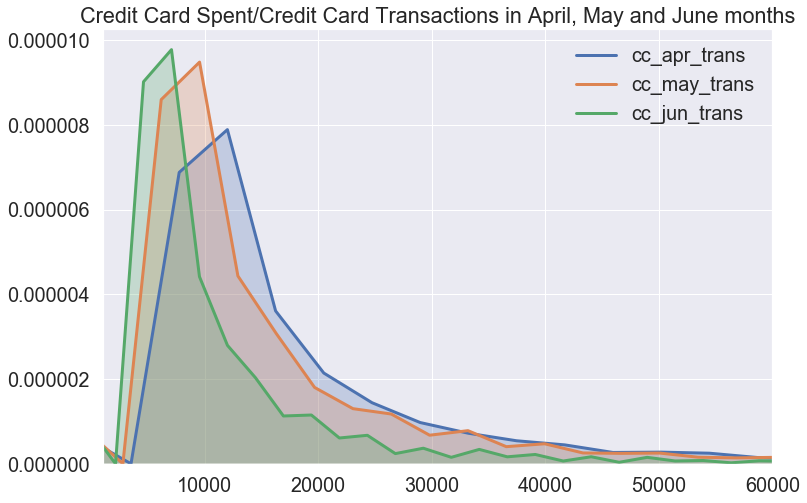

In [186]:
fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True,figsize=(12,8))
ax1 = plt.subplot(1, 1, 1)
ax1 = sns.distplot(cc_spent['cc_apr_trans'], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='cc_apr_trans')
ax1= sns.distplot(cc_spent['cc_may_trans'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='cc_may_trans')
ax1= sns.distplot(cc_spent['cc_jun_trans'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='cc_jun_trans')
ax1.set_xlabel("")
ax1.set_title("Credit Card Spent/Credit Card Transactions in April, May and June months")
plt.xlim(1000,60000)

From above graph, we observe for mostly of the bill paid is overlapping between 1000 to 2000 range for 3 respective months. That means
customers are paying 1000-2000 per transaction. However, looks like April month had more bills to be paid followed by May and June.

##### <font color='red'> Plotting of credit amount with age</font>

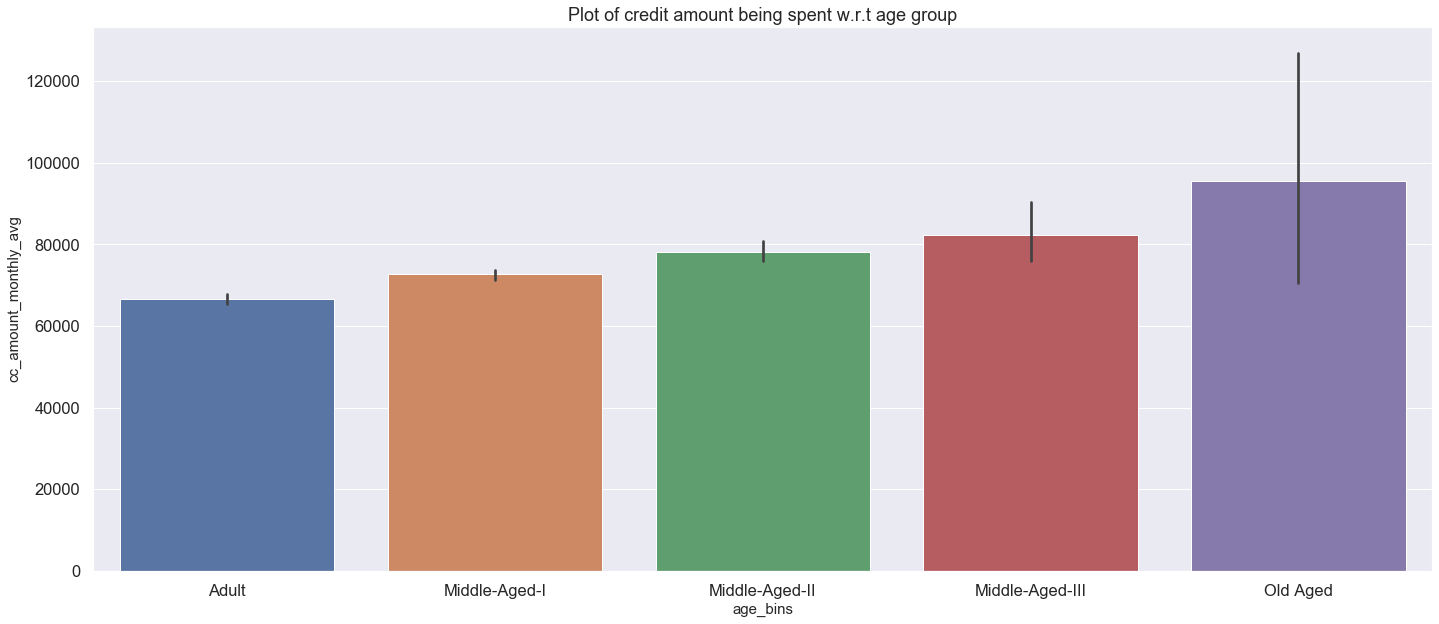

In [187]:
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','cc_amount_monthly_avg',data=cc_spent, ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('cc_amount_monthly_avg', fontsize=15)
plt.title("Plot of credit amount being spent w.r.t age group")
plt.show()



We see that the credit amount being spent is increasing with age . Since , these categories save a lot
so they might be finding best deals with prices and with cashback available spending credit amount.

##### <font color='red'> Plot of credit amount with age and loans active </font>

Let us further analyse the emi's active based on the credit amount being spent based on the age.

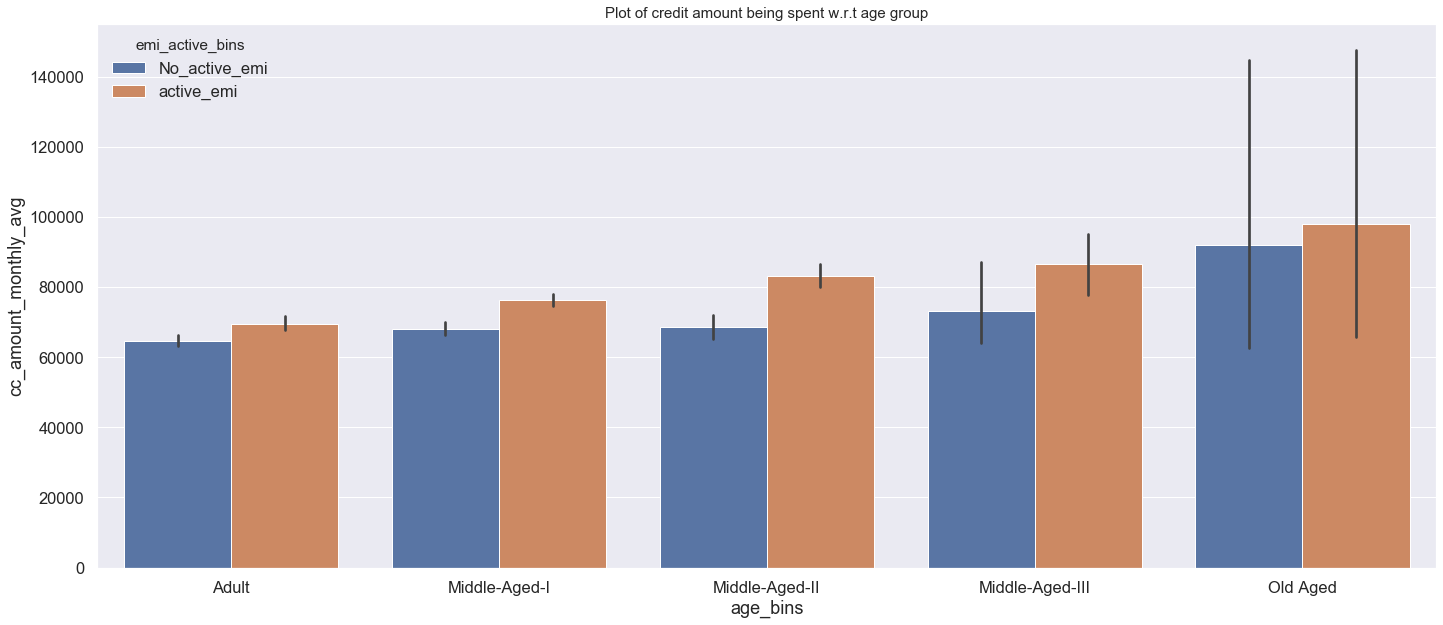

In [188]:
fig, ax = plt.subplots(figsize=(24,10))
ax = sns.barplot(x='age_bins',y='cc_amount_monthly_avg',hue='emi_active_bins',data=cc_spent)
plt.title("Plot of credit amount being spent w.r.t age group",fontsize=15)
plt.show()

Seeing the analysis question we feel that adults and middle-aged-I group are the ones hold emi's as they spend credit amount mostly. But data gives us a different picture, it shows us the vice-versa where "Old Aged" are having the max. average emi's and even credit spending pattern is more. If the cash inflow is not consistent to their accounts are are likely to become bankrupts in near future. Here, is the caution to them to wisely carry out the credit spent.

##### Total number of times amount debited/credited in April, May and June

In [189]:
cc_amt_nof_lst = ['credit_count_apr','credit_count_may','credit_count_jun']
dc_amt_nof_lst = ['debit_count_apr','debit_count_may','debit_count_jun']

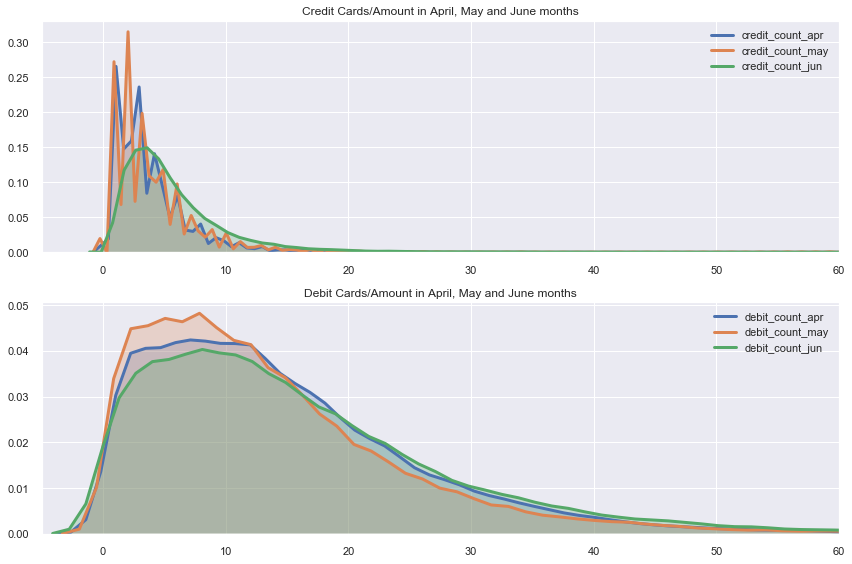

In [190]:
cc_dc_pattern(cc_spent,'credit_count_apr','credit_count_may','credit_count_jun',
              'debit_count_apr','debit_count_may','debit_count_jun',-5,60)

##### Total number of credit transactions in April , May and June months


In [191]:
cc_spent[cc_amt_nof_lst].describe()

,credit_count_apr,credit_count_may,credit_count_jun
count,46830.000000,46830.000000,46830.000000
mean,3.736874,4.017368,5.747259
std,3.412209,3.771537,4.638953
min,0.000000,0.000000,0.000000
25%,2.000000,2.000000,3.000000
50%,3.000000,3.000000,5.000000
75%,5.000000,5.000000,7.000000
max,78.000000,71.000000,117.000000


1. We see that the mean and median values almost being similar to each other.
2. The IQR range lies between 3-4 that means 3-4 credit transactions are carried out monthly
by most customers.
3. Also, for June month we see the difference between 3rd Quartile and maximum value being 117 . A 
difference of 110 amounting to. Which means there are few people who are carring out huge credit 
transactions.

<b><i> Note</i></b>:- Inorder to understand the features for credit amount transactions, max credit amount you can follow the steps mentioned in above analysis
    

Let us see the credit amount balance left on subtracting the maximum credit amount with total credit amount.

In [192]:
cc_spent['credit_amount_balance'] = cc_spent['cc_max_amt_monthly_avg'] - cc_spent['cc_amount_monthly_avg']

##### <font color='red'> Credit Card Limit over EMI Active / Debt  visualization</font>

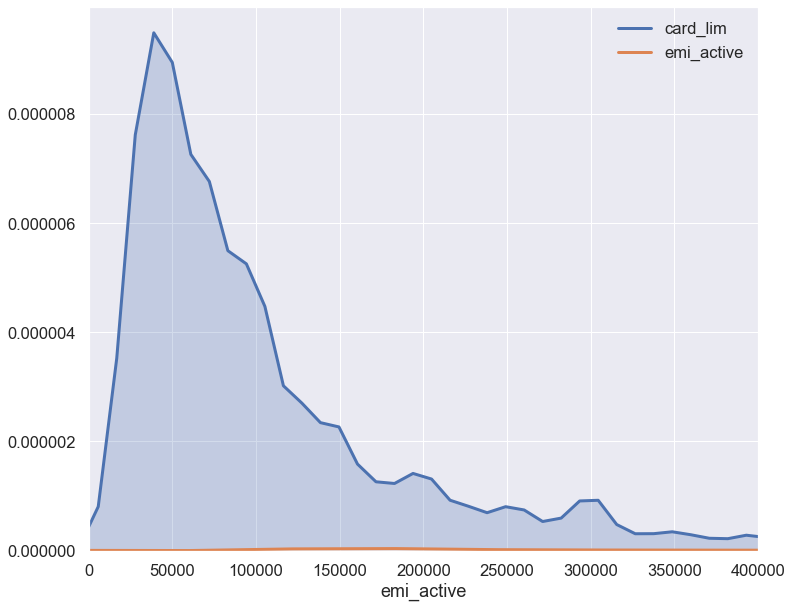

(400000, 1400000)

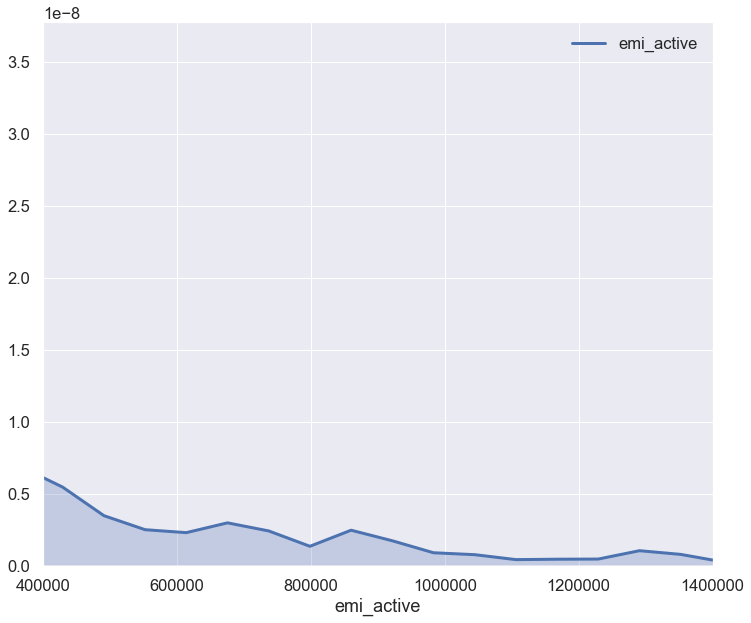

In [193]:
sns.set(font_scale=1.5)
ax1 = sns.distplot(cc_spent['card_lim'], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='card_lim')
ax1 = sns.distplot(cc_spent['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
ax1.set_xlim(0,400000)
plt.show()
   
ax2 = sns.distplot(cc_spent['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
plt.xlim(400000, 1400000)

Since, emi_active is present in the higher range,for better visualization created any subplot. 
Above graph gives us a comparison of credit card limit allocated to users and the debt 
being transferred as other banks. Majority of the users account for 50000 as the card limit.
When comes to credit debts, huge EMI's are active ranging from 400000 - 1400000. Will the help
of card_limit and emi_active, we can calcuate the credit_utilization.

<b> Credit_Utilization = EMI_active / Card_lim </b>

In [194]:
cc_spent['credit_utilization'] = cc_spent['emi_active'] / cc_spent['card_lim']

#### Checking for null values in the feature

In [195]:
cc_spent['credit_utilization'].isnull().sum()

1

We observe there is one null value will impute it using mean.

In [196]:
cc_spent['credit_utilization'] = cc_spent['credit_utilization'].fillna(cc_spent['credit_utilization'].mean())

Checking the null values upon imputation

In [197]:
cc_spent['credit_utilization'].isnull().sum()

0

##### <font color='red'> Plotting of credit_utilization with age</font>

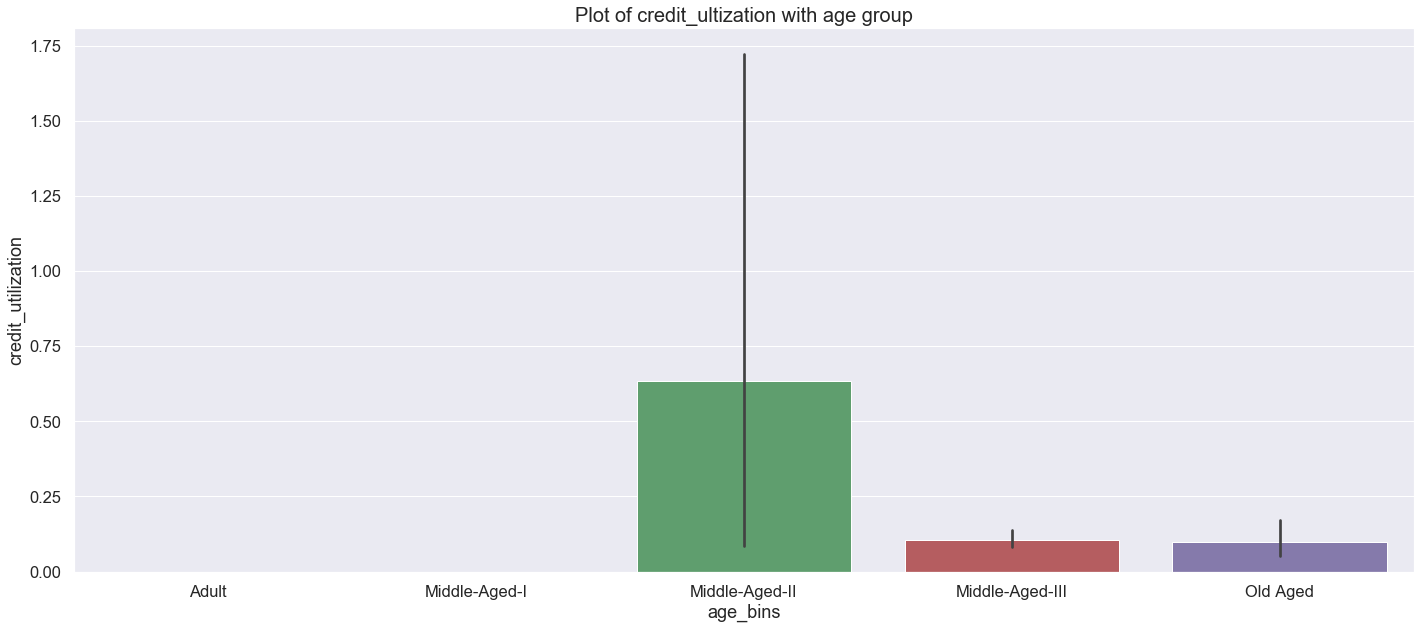

In [198]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','credit_utilization',data=cc_spent, ax=ax)
#ax.set_ylim(0,350000)
ax.set_xlabel('age_bins',fontsize=18)
ax.set_ylabel('credit_utilization', fontsize=18)
plt.title("Plot of credit_ultization with age group",fontsize=20)
plt.show()

Consumers with zero emi_active, have zero credit ultization. Credit Ultization increases from 
Middle-Aged-II i.e 41 and 51 and then again falls drastically from Middle-Aged-III and Old Aged groups
accordingly. This concludes that the middle aged-II spends maximum credit amount.

In [199]:
# Let us see the features
pd.set_option('display.max_columns',70)
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg,cc_cons_2month,dc_cons_2month,ratio_cc_dc_cons_2month,cc_apr_trans,cc_may_trans,cc_jun_trans,credit_amount_balance,credit_utilization
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,inf,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333,8796.00,0.00,inf,699.545455,34.214286,56.545455,-50936.000000,0.000000
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656,15433.333333,83662.00,3794.96,22.045555,8783.666667,3319.222222,181.166667,-14996.970000,0.028201
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058,8866.666667,33628.13,5177.52,6.495027,1200.054444,3609.940000,194.666667,-922.333333,0.000000
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,inf,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333,34808.50,0.00,inf,10468.000000,299.142857,1308.722222,-2982.666667,0.002064
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,inf,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000,5785.12,0.00,inf,84.559286,457.036250,85.909091,-7700.710000,0.000000


In [200]:
# Creating a copy of df "cc_spent" to df "credit_card_spent"
credit_card_spent = cc_spent.copy(deep=True)

We observe that the data now contains some infinite values in it. Let us convert that to 'NaN' first and then impute values by 0.

In [201]:
cc_spent = cc_spent.replace([np.inf, -np.inf],np.nan)

In [202]:
null_counts = cc_spent.isnull().sum()
print(null_counts[null_counts > 0])

cc_cons                    14051
ratio_cc_dc_cons           18844
cc_cons_ratio                  2
ratio_cc_dc_cons_2month    18844
credit_utilization             2
dtype: int64


In [203]:
fill_zeros_col = ['ratio_cc_dc_cons','cc_cons_ratio','ratio_cc_dc_cons_2month','credit_utilization']

In [204]:
cc_spent[fill_zeros_col] = cc_spent[fill_zeros_col].apply(lambda x: x.fillna(0), axis=0)

In [205]:
cc_spent.isnull().sum()

id                       0
account_type             0
gender                   0
age                      0
region_code              0
                        ..
cc_apr_trans             0
cc_may_trans             0
cc_jun_trans             0
credit_amount_balance    0
credit_utilization       0
Length: 63, dtype: int64

Let us remove the irrelevant columns from the dataframe.

In [206]:
pd.set_option('display.max_columns',70)
cc_spent.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,dc_cons_avg,emi_active_bins,investment_1_bins,investment_2_bins,investment_3_bins,age_bins,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg,cc_cons_2month,dc_cons_2month,ratio_cc_dc_cons_2month,cc_apr_trans,cc_may_trans,cc_jun_trans,credit_amount_balance,credit_utilization
0,23334,saving,M,63,305,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435.0,DC_notconsumed,No_active_emi,No_Demat acct,FixedDeposit,LifeInsurance,Old Aged,2932.000000,0.000000,0.000000,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333,8796.00,0.00,0.000000,699.545455,34.214286,56.545455,-50936.000000,0.000000
1,20329,current,M,33,326,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921.0,DC_consumed,active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656,15433.333333,83662.00,3794.96,22.045555,8783.666667,3319.222222,181.166667,-14996.970000,0.028201
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970.0,DC_consumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-II,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058,8866.666667,33628.13,5177.52,6.495027,1200.054444,3609.940000,194.666667,-922.333333,0.000000
3,16428,saving,M,44,233,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579.0,DC_notconsumed,active_emi,No_Demat acct,FixedDeposit,No_LifeInsurance,Middle-Aged-II,11602.833333,0.000000,0.000000,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333,34808.50,0.00,0.000000,10468.000000,299.142857,1308.722222,-2982.666667,0.002064
4,18721,saving,F,35,324,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814.0,DC_notconsumed,No_active_emi,No_Demat acct,No_FixedDeposit,No_LifeInsurance,Middle-Aged-I,1928.373333,0.000000,0.000000,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000,5785.12,0.00,0.000000,84.559286,457.036250,85.909091,-7700.710000,0.000000


In [207]:
drop_cols = ['id','region_code','loan_enq','dc_cons_avg','emi_active_bins','investment_1_bins','investment_2_bins','investment_3_bins',
            'age_bins']

In [208]:
cc_spent = cc_spent.drop(drop_cols, axis=1)

##### <font color='red'> Modification of target variable 'cc_cons'

Inorder to directly optimize the RMSE values for the models, the target variable "cc_cons" is being converted to log(cc_cons+1). This allows us to use RMSE as an optimization metric while in reality optimizing RMSLE.


In [209]:
cc_spent['cc_cons'] = np.log(cc_spent['cc_cons'] + 1) 

In [210]:
cc_spent.head()

,account_type,gender,age,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg,cc_cons_2month,dc_cons_2month,ratio_cc_dc_cons_2month,cc_apr_trans,cc_may_trans,cc_jun_trans,credit_amount_balance,credit_utilization
0,saving,M,63,7695.00,0.00,479.00,0.0,622.0,0.00,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,0.00,6.077642,2932.000000,0.000000,0.000000,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333,8796.00,0.00,0.000000,699.545455,34.214286,56.545455,-50936.000000,0.000000
1,current,M,33,52702.00,988.72,29873.00,0.0,1087.0,2806.24,6.0,9.0,6.0,1.0,0.0,6.0,176000.0,0,0,0,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,4963.33,7.561122,27887.333333,1264.986667,22.045555,15.85,7.0,28171.000000,30430.303333,37864.850000,0.803656,15433.333333,83662.00,3794.96,22.045555,8783.666667,3319.222222,181.166667,-14996.970000,0.028201
2,current,M,44,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,9.0,6.0,6.0,3.0,2.0,14.0,65000.0,0,0,0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,0.00,7.586296,11209.376667,1725.840000,6.495027,17.25,7.0,11150.964286,9789.000000,8922.953333,1.097058,8866.666667,33628.13,5177.52,6.495027,1200.054444,3609.940000,194.666667,-922.333333,0.000000
3,saving,M,44,20936.00,0.00,2094.00,0.0,11778.5,0.00,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,1238.18,9.979522,11602.833333,0.000000,0.000000,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333,34808.50,0.00,0.000000,10468.000000,299.142857,1308.722222,-2982.666667,0.002064
4,saving,F,35,1183.83,0.00,3656.29,0.0,945.0,0.00,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,0.00,7.503841,1928.373333,0.000000,0.000000,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000,5785.12,0.00,0.000000,84.559286,457.036250,85.909091,-7700.710000,0.000000


In [211]:
# Let us check for nulls again in the column 'cc_cons_log'
cc_spent.isnull().sum()

account_type                   0
gender                         0
age                            0
cc_cons_apr                    0
dc_cons_apr                    0
cc_cons_may                    0
dc_cons_may                    0
cc_cons_jun                    0
dc_cons_jun                    0
cc_count_apr                   0
cc_count_may                   0
cc_count_jun                   0
dc_count_apr                   0
dc_count_may                   0
dc_count_jun                   0
card_lim                       0
investment_1                   0
investment_2                   0
investment_3                   0
debit_amount_apr               0
credit_amount_apr              0
debit_count_apr                0
credit_count_apr               0
max_credit_amount_apr          0
debit_amount_may               0
credit_amount_may              0
credit_count_may               0
debit_count_may                0
max_credit_amount_may          0
debit_amount_jun               0
credit_amo

In [212]:
# Splitting the dataset into train and test savings
train = cc_spent.iloc[:32820,:]
test = cc_spent.iloc[32820:,:]

In [213]:
train.isnull().sum()

account_type                0
gender                      0
age                         0
cc_cons_apr                 0
dc_cons_apr                 0
cc_cons_may                 0
dc_cons_may                 0
cc_cons_jun                 0
dc_cons_jun                 0
cc_count_apr                0
cc_count_may                0
cc_count_jun                0
dc_count_apr                0
dc_count_may                0
dc_count_jun                0
card_lim                    0
investment_1                0
investment_2                0
investment_3                0
debit_amount_apr            0
credit_amount_apr           0
debit_count_apr             0
credit_count_apr            0
max_credit_amount_apr       0
debit_amount_may            0
credit_amount_may           0
credit_count_may            0
debit_count_may             0
max_credit_amount_may       0
debit_amount_jun            0
credit_amount_jun           0
credit_count_jun            0
debit_count_jun             0
max_credit

In [214]:
# We still see there are null values present in "cc_cons_log" after log imputation. Let us impute those values with 0.
train['cc_cons'] = train['cc_cons'].fillna(0)

In [215]:
train.isnull().sum()

account_type               0
gender                     0
age                        0
cc_cons_apr                0
dc_cons_apr                0
cc_cons_may                0
dc_cons_may                0
cc_cons_jun                0
dc_cons_jun                0
cc_count_apr               0
cc_count_may               0
cc_count_jun               0
dc_count_apr               0
dc_count_may               0
dc_count_jun               0
card_lim                   0
investment_1               0
investment_2               0
investment_3               0
debit_amount_apr           0
credit_amount_apr          0
debit_count_apr            0
credit_count_apr           0
max_credit_amount_apr      0
debit_amount_may           0
credit_amount_may          0
credit_count_may           0
debit_count_may            0
max_credit_amount_may      0
debit_amount_jun           0
credit_amount_jun          0
credit_count_jun           0
debit_count_jun            0
max_credit_amount_jun      0
emi_active    

We decided to bring a little twist in our analysis. Instead of training and predicting a single dataframe. We shall train model based on the account types "saving" or "current" and get more inferences from it. Let us now Splitting dataframe "cc_spent" based on account_types "saving" and "current".

In [216]:
saving_df = train[train['account_type']=='saving']
current_df = train[train['account_type']=='current']

In [217]:
saving_df.shape

(6987, 54)

In [218]:
current_df.shape

(25833, 54)

We observe that the customers hold the current account mostly. They might be using it mostly for business purpose as we can also
see huge amount of credit being spent by them.

In [220]:
# Account type col is now irrelvant. Hence, dropping it
saving_df = saving_df.drop('account_type',axis=1)
current_df = current_df.drop('account_type',axis=1)

In [221]:
saving_df.head()

,gender,age,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,investment_1,investment_2,investment_3,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,emi_active,cc_cons,cc_cons_monthly_average,dc_cons_monthly_average,ratio_cc_dc_cons,cc_cons_ratio,cc_trans_monthly_avg,weighted_avg_cc_cons,cc_amount_monthly_avg,dc_amount_monthly_avg,ratio_cc_dc_amount,cc_max_amt_monthly_avg,cc_cons_2month,dc_cons_2month,ratio_cc_dc_cons_2month,cc_apr_trans,cc_may_trans,cc_jun_trans,credit_amount_balance,credit_utilization
0,M,63,7695.00,0.0,479.00,0.0,622.0,0.0,11.0,14.0,11.0,0.0,0.0,0.0,150000.0,0,1,1,159050.76,169812.00,20.0,9.0,70000.0,103102.85,174606.00,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,0.00,6.077642,2932.000000,0.000000,0.000000,1.95,12.0,2727.583333,133269.333333,128063.756667,1.040648,82333.333333,8796.00,0.0,0.000000,699.545455,34.214286,56.545455,-50936.000000,0.000000
3,M,44,20936.00,0.0,2094.00,0.0,11778.5,0.0,2.0,7.0,9.0,0.0,0.0,0.0,600000.0,0,1,0,6462.00,10271.00,6.0,1.0,10000.0,7461.00,3194.00,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,1238.18,9.979522,11602.833333,0.000000,0.000000,1.93,6.0,9029.805556,22316.000000,13367.016667,1.669482,19333.333333,34808.50,0.0,0.000000,10468.000000,299.142857,1308.722222,-2982.666667,0.002064
4,F,35,1183.83,0.0,3656.29,0.0,945.0,0.0,14.0,8.0,11.0,0.0,0.0,0.0,100000.0,0,0,0,7717.72,7792.00,17.0,4.0,3000.0,25958.50,26620.00,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,0.00,7.503841,1928.373333,0.000000,0.000000,1.93,11.0,1703.604242,22531.710000,21621.826667,1.042082,14831.000000,5785.12,0.0,0.000000,84.559286,457.036250,85.909091,-7700.710000,0.000000
9,M,47,9191.31,0.0,8327.55,0.0,14642.0,0.0,23.0,15.0,25.0,0.0,0.0,0.0,64000.0,0,0,0,17075.25,10196.88,4.0,2.0,10000.0,51947.00,45280.24,4.0,4.0,40000.0,38053.00,42712.60,4.0,2.0,40000.0,0.00,7.798933,10720.286667,0.000000,0.000000,16.75,21.0,11148.625079,32729.906667,35691.750000,0.917016,30000.000000,32160.86,0.0,0.000000,399.622174,555.170000,585.680000,-2729.906667,0.000000
10,M,58,38237.52,0.0,23613.67,511.0,306.0,0.0,7.0,10.0,10.0,0.0,1.0,0.0,245000.0,1,0,0,240158.30,240769.70,10.0,10.0,110000.0,47179.30,52142.00,3.0,5.0,35247.0,25009.32,78940.00,4.0,10.0,60848.0,2000.40,7.853216,20719.063333,170.333333,121.638337,8.46,9.0,18772.568148,123950.566667,104115.640000,1.190509,68698.333333,62157.19,511.0,121.638337,5462.502857,2361.367000,30.600000,-55252.233333,0.008165


In [222]:
# Splitting the features and target of "savings" and "current"
X_sav = saving_df.iloc[:, saving_df.columns != 'cc_cons']
Y_sav = saving_df.iloc[:, saving_df.columns == 'cc_cons']

X_curr = current_df.iloc[:,current_df.columns != 'cc_cons']
Y_curr = current_df.iloc[:,current_df.columns == 'cc_cons']

### <font color='red'> Normalizing and Label Encoding features </font>

In [ ]:
# Note:- If you haven't use xgboost or LightGBM models . You can install it using:-
    
    
!pip install xgboost

!pip install lightgbm

In [223]:
# Importing specified libraries
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [224]:
def model_build(X,Y):
    bin_cols = X.nunique()[X.nunique()==2].keys().tolist()
    le = LabelEncoder()
    for i in bin_cols:
        X[i] = le.fit_transform(X[i])
        
    num_feat = [col for col in X.columns if col not in bin_cols]
    minmax = MinMaxScaler()
    X[num_feat] = minmax.fit_transform(X[num_feat].values)
    
    X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3,random_state=0)
    regressors = [ RandomForestRegressor(),
                   XGBRegressor(),
                   LGBMRegressor()
                 ]
    model_lst = []
    rmse_lst  = []
    for regressor in regressors:
        regressor.fit(X_train, Y_train)
        model_lst.append(regressor)
        Y_pred = regressor.predict(X_test)
        rmse_lst.append(np.sqrt(mean_squared_error(Y_test, Y_pred)))
    regressor_df = pd.DataFrame()
    regressor_df['Models'] = model_lst
    regressor_df['RMSE'] = rmse_lst
    return regressor_df

In [225]:
model_build(X_sav,Y_sav)

[23:31:12] WARNING: C:/Jenkins/workspace/xgboost-win64_release_0.90/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


,Models,RMSE
0,"(DecisionTreeRegressor(criterion='mse', max_de...",1.313541
1,"XGBRegressor(base_score=0.5, booster='gbtree',...",1.257112
2,"LGBMRegressor(boosting_type='gbdt', class_weig...",1.267682


In [226]:
model_build(X_curr, Y_curr)

[23:31:25] WARNING: C:/Jenkins/workspace/xgboost-win64_release_0.90/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


,Models,RMSE
0,"(DecisionTreeRegressor(criterion='mse', max_de...",1.286554
1,"XGBRegressor(base_score=0.5, booster='gbtree',...",1.216647
2,"LGBMRegressor(boosting_type='gbdt', class_weig...",1.226483


We see that current model performs better than savings model as it has got sufficient number of records to train model. 

### Hyperparameter tuning of Random Forest Algorithm for Saving  and Current account type models using GridSearchCV

In [227]:
from sklearn.model_selection import GridSearchCV

In [228]:
def rfr_model(X,Y):
    bin_cols = X.nunique()[X.nunique()==2].keys().tolist()
    le = LabelEncoder()
    for i in bin_cols:
        X[i] = le.fit_transform(X[i])
        
    num_feat = [col for col in X.columns if col not in bin_cols]
    minmax = MinMaxScaler()
    X[num_feat] = minmax.fit_transform(X[num_feat].values)
    
    X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3,random_state=0)
    rfr = RandomForestRegressor()
    model_lst = []
    rmse_lst = []
    params = {
            'bootstrap':[True],
            'max_depth':[7,8,9],
            'min_samples_leaf':[7,8,9],
            'min_samples_split':[5,6,7],
            'n_estimators':[40,45,50]
            
            }
    grid_search = GridSearchCV(estimator = rfr, param_grid=params,cv=3,scoring='neg_mean_squared_error',verbose=0,n_jobs=-1)
    model_lst.append(grid_search)
    grid_search.fit(X_train,Y_train)
    Y_rf_pred = grid_search.predict(X_test)
    rmse_lst.append(np.sqrt(mean_squared_error(Y_rf_pred,Y_test)))
    rf_df = pd.DataFrame()
    rf_df['Model'] = model_lst
    rf_df['RMSE'] = rmse_lst
    return rf_df
    
    

In [229]:
rfr_model(X_sav, Y_sav)

,Model,RMSE
0,"GridSearchCV(cv=3, error_score='raise-deprecat...",1.262799


In [230]:
rfr_model(X_curr, Y_curr)

,Model,RMSE
0,"GridSearchCV(cv=3, error_score='raise-deprecat...",1.2218


Above hypertuning shows improvement in error rate in models . 

However, for ML algorithms such as XGBoost and LightGBM the minimum number of rows required to train is 10,000+ otherwise there are chances of model getting overfitted. As Savings model
doesn't satisfy it we shall not go the depth and  take a pause here itself and continue tuning our "Current" account type model.

##### Hyperparameter tuning of Current account type model using XGBoost 

Before hypertunning, since we performed all preprocessing in seperate functions itself. Let preprocess for a final time for "current" model.

In [233]:
import xgboost as xgb

In [234]:
bin_cols = X_curr.nunique()[X_curr.nunique()==2].keys().tolist()

le = LabelEncoder()
for i in bin_cols:
    X_curr[i] = le.fit_transform(X_curr[i])
        

num_feat = [col for col in X_curr.columns if col not in bin_cols]
minmax = MinMaxScaler()
X_curr[num_feat] = minmax.fit_transform(X_curr[num_feat].values)
X_train, X_test, Y_train, Y_test = train_test_split(X_curr,Y_curr,test_size=0.3,random_state=0)

In [235]:
# Loading data into DMatrices
#  Inorder to use native API for XGBoost we will first need to build DMatrices

dtrain = xgb.DMatrix(X_train, label=Y_train)
dtest = xgb.DMatrix(X_test, label=Y_test)

In [236]:
# Hypertuning a XGBoost Regressor model
params = {
            'max_depth':3,
            'min_child_weight':1,
            'eta': .01,
            'subsample':0.8,
            'colsample_bytree':0.42,
            'objective':'reg:squarederror'
}

In [237]:
model = xgb.train(
                    params,
                    dtrain,
                    num_boost_round=999,
                    evals=[(dtest,"Test")],
                    early_stopping_rounds=10
                )

[0]	Test-rmse:7.49855
Will train until Test-rmse hasn't improved in 10 rounds.
[1]	Test-rmse:7.42551
[2]	Test-rmse:7.35318
[3]	Test-rmse:7.28156
[4]	Test-rmse:7.21066
[5]	Test-rmse:7.14055
[6]	Test-rmse:7.07114
[7]	Test-rmse:7.0024
[8]	Test-rmse:6.93436
[9]	Test-rmse:6.86709
[10]	Test-rmse:6.8005
[11]	Test-rmse:6.73457
[12]	Test-rmse:6.66935
[13]	Test-rmse:6.60477
[14]	Test-rmse:6.54085
[15]	Test-rmse:6.47761
[16]	Test-rmse:6.41506
[17]	Test-rmse:6.35319
[18]	Test-rmse:6.29189
[19]	Test-rmse:6.23122
[20]	Test-rmse:6.1712
[21]	Test-rmse:6.11196
[22]	Test-rmse:6.05321
[23]	Test-rmse:5.9951
[24]	Test-rmse:5.93746
[25]	Test-rmse:5.8805
[26]	Test-rmse:5.82418
[27]	Test-rmse:5.76841
[28]	Test-rmse:5.71323
[29]	Test-rmse:5.65854
[30]	Test-rmse:5.60453
[31]	Test-rmse:5.5511
[32]	Test-rmse:5.49821
[33]	Test-rmse:5.44592
[34]	Test-rmse:5.39412
[35]	Test-rmse:5.34297
[36]	Test-rmse:5.2922
[37]	Test-rmse:5.24201
[38]	Test-rmse:5.19226
[39]	Test-rmse:5.14307
[40]	Test-rmse:5.09439
[41]	Test-rmse:5.

[345]	Test-rmse:1.23695
[346]	Test-rmse:1.23652
[347]	Test-rmse:1.23614
[348]	Test-rmse:1.23575
[349]	Test-rmse:1.23531
[350]	Test-rmse:1.23493
[351]	Test-rmse:1.23452
[352]	Test-rmse:1.23415
[353]	Test-rmse:1.23378
[354]	Test-rmse:1.23344
[355]	Test-rmse:1.23311
[356]	Test-rmse:1.23275
[357]	Test-rmse:1.23242
[358]	Test-rmse:1.23206
[359]	Test-rmse:1.23173
[360]	Test-rmse:1.23141
[361]	Test-rmse:1.2311
[362]	Test-rmse:1.23077
[363]	Test-rmse:1.23049
[364]	Test-rmse:1.23021
[365]	Test-rmse:1.22989
[366]	Test-rmse:1.2296
[367]	Test-rmse:1.22933
[368]	Test-rmse:1.22908
[369]	Test-rmse:1.22879
[370]	Test-rmse:1.22855
[371]	Test-rmse:1.22829
[372]	Test-rmse:1.22803
[373]	Test-rmse:1.22778
[374]	Test-rmse:1.22751
[375]	Test-rmse:1.22729
[376]	Test-rmse:1.22706
[377]	Test-rmse:1.22681
[378]	Test-rmse:1.22659
[379]	Test-rmse:1.2264
[380]	Test-rmse:1.22618
[381]	Test-rmse:1.22597
[382]	Test-rmse:1.22577
[383]	Test-rmse:1.22559
[384]	Test-rmse:1.22541
[385]	Test-rmse:1.22522
[386]	Test-rmse:1.2

Since, we now know the exact best "num_boost_round", we don't need the "early_stopping_round" anymore. 

In [238]:
num_boost_round = model.best_iteration + 1
best_model = xgb.train(
                    params,
                    dtrain,
                    num_boost_round=num_boost_round,
                    evals=[(dtest,"Test")],
                    
                )

[0]	Test-rmse:7.49855
[1]	Test-rmse:7.42551
[2]	Test-rmse:7.35318
[3]	Test-rmse:7.28156
[4]	Test-rmse:7.21066
[5]	Test-rmse:7.14055
[6]	Test-rmse:7.07114
[7]	Test-rmse:7.0024
[8]	Test-rmse:6.93436
[9]	Test-rmse:6.86709
[10]	Test-rmse:6.8005
[11]	Test-rmse:6.73457
[12]	Test-rmse:6.66935
[13]	Test-rmse:6.60477
[14]	Test-rmse:6.54085
[15]	Test-rmse:6.47761
[16]	Test-rmse:6.41506
[17]	Test-rmse:6.35319
[18]	Test-rmse:6.29189
[19]	Test-rmse:6.23122
[20]	Test-rmse:6.1712
[21]	Test-rmse:6.11196
[22]	Test-rmse:6.05321
[23]	Test-rmse:5.9951
[24]	Test-rmse:5.93746
[25]	Test-rmse:5.8805
[26]	Test-rmse:5.82418
[27]	Test-rmse:5.76841
[28]	Test-rmse:5.71323
[29]	Test-rmse:5.65854
[30]	Test-rmse:5.60453
[31]	Test-rmse:5.5511
[32]	Test-rmse:5.49821
[33]	Test-rmse:5.44592
[34]	Test-rmse:5.39412
[35]	Test-rmse:5.34297
[36]	Test-rmse:5.2922
[37]	Test-rmse:5.24201
[38]	Test-rmse:5.19226
[39]	Test-rmse:5.14307
[40]	Test-rmse:5.09439
[41]	Test-rmse:5.04638
[42]	Test-rmse:4.9988
[43]	Test-rmse:4.95173
[44]	T

[348]	Test-rmse:1.23575
[349]	Test-rmse:1.23531
[350]	Test-rmse:1.23493
[351]	Test-rmse:1.23452
[352]	Test-rmse:1.23415
[353]	Test-rmse:1.23378
[354]	Test-rmse:1.23344
[355]	Test-rmse:1.23311
[356]	Test-rmse:1.23275
[357]	Test-rmse:1.23242
[358]	Test-rmse:1.23206
[359]	Test-rmse:1.23173
[360]	Test-rmse:1.23141
[361]	Test-rmse:1.2311
[362]	Test-rmse:1.23077
[363]	Test-rmse:1.23049
[364]	Test-rmse:1.23021
[365]	Test-rmse:1.22989
[366]	Test-rmse:1.2296
[367]	Test-rmse:1.22933
[368]	Test-rmse:1.22908
[369]	Test-rmse:1.22879
[370]	Test-rmse:1.22855
[371]	Test-rmse:1.22829
[372]	Test-rmse:1.22803
[373]	Test-rmse:1.22778
[374]	Test-rmse:1.22751
[375]	Test-rmse:1.22729
[376]	Test-rmse:1.22706
[377]	Test-rmse:1.22681
[378]	Test-rmse:1.22659
[379]	Test-rmse:1.2264
[380]	Test-rmse:1.22618
[381]	Test-rmse:1.22597
[382]	Test-rmse:1.22577
[383]	Test-rmse:1.22559
[384]	Test-rmse:1.22541
[385]	Test-rmse:1.22522
[386]	Test-rmse:1.22504
[387]	Test-rmse:1.22487
[388]	Test-rmse:1.22467
[389]	Test-rmse:1.2

Thus, the best RMSE obtained on hypertuning is 0.092975. Model hasn't achieved a drastic change in reducing the error. It is something like you loose weight in small inches
and hardly anyone can notice that difference.

##### Hyperparameter tuning of LGBM

In [239]:
import lightgbm as lgb

In [240]:
dtrain_lgb = lgb.Dataset(X_train, label=Y_train)
dtest_lgb  = lgb.Dataset(X_test, label=Y_test)

In [241]:
# Hyperparameter tuning of LGBM
params = {
            'learning_rate':0.04,
            'metric':'rmse',
            'sub_feature':0.65,
            'min_data':70,
            'max_depth':3,
            'min_child_weight':3
            
}

In [242]:
lgbm_model = lgb.train(
                        params, 
                        dtrain_lgb, 
                        100,
                        
                      )

In [243]:
Y_lgb_pred = lgbm_model.predict(X_test)

In [244]:
rmse = np.sqrt(mean_squared_error(Y_test, Y_lgb_pred))
print("RMSE of LGBM model: %f"%(rmse))

RMSE of LGBM model: 1.217758


Even , LGBM has not got a vast difference upon Hypertuning . Error rate just reduced by 0.01% .

Now, a question arises to you what shall we do of the test dataset. Just apply the XGBoost Model on the test model and get the y_pred of it. As this data belongs to one of the Data Science Competitions usually the test results obtained are submitted and based on that the ranks are obtained. 

Through this we come to an end of Model Building Phase of Credit Card Spend Prediction. Hope you got enough of gyaan needed. You
can also try using other algo's as well. Perform K-Fold Cross validation apart from train_test_split and try to further reduce the RMSE value.

Going through this Data Tale, I am sure you might have started analysing your own credit card spending pattern and infer various analysis out of it. Keep getting more insights are let us know if any new idea comes your free. 

### Bye !!!!